In [1]:
library(repr) ; options(repr.plot.width=7, repr.plot.height= 6) # Change plot sizes (in cm) - this bit of code is only relevant if you are using a juyter notebook - ignore otherwise

# Data Management and Visualization in R

```{admonition} Learning goals
**By the end of this chapter you should be able to:**
- Keep raw data, derived data, metadata and results in distinct and clearly named places
- Inspect a dataset's structure, types and missing values before changing it
- Distinguish an observed zero from a missing observation and document how each is handled
- Clean, join and summarize biological data with a script whose steps you can follow and rerun
- Reshape data between wide and long forms when the biological question requires it
- Build publication quality plots
- Choose scales, labels and visual encodings that make a figure clear without distorting the data
- Save a derived table and a figure, then recreate both from the raw data after restarting R
```

```{admonition} Prerequisites
:class: tip
This chapter follows directly from [Biological Computing in R](r.ipynb). Before starting, you should be able to:
- run an R script from the root of a project containing `code`, `data` and `results` directories;
- create and inspect vectors and data frames, call functions, and interpret `NA`;
- read a CSV file, make a simple calculation and save an output; and
- explain the observations exercise's distinction between missing counts and observed zeros.

You will also use simple summaries such as the mean and median. They are introduced briefly where needed, but revisiting them beforehand may help.
```

## Introduction

This is the second of MQB's two main R chapters. [Biological Computing in R](r.ipynb) asked how to express, run and check a computation. We now turn to a new question: how do we make trustworthy data and insightful visualisations from raw observations? Bring your `observations_practice.R` script and its outputs with you. We will keep returning to the choices you made there as we move on to the richer Pound Hill dataset.

Rapid advances in data collection and the digitization of historical records are generating vast and varied biological datasets. Genomic, ecosystem respiration, climatic, and animal-tracking data are prominent examples. Quantitative biology seeks to discover patterns in such data and fit mathematical models to them, but the reliability of those results depends on how observations are organized and transformed before analysis.

Hadley Wickham captures the challenge of organizing data consistently:

> *Tidy datasets are all alike, but every messy dataset is messy in its own way.* &ndash; Hadley Wickham {cite}`Wickham2014TidyData`

A tidy structure makes the roles of variables and observations explicit, allowing data-processing steps to be automated, inspected, and reproduced. This is especially important for biological data, which are often heterogeneous in structure and quality, and reduces the errors introduced by repeated manual editing.

Once data are well structured, the next challenge is to reveal and communicate the patterns they contain. As Edward Tufte argues:

> *Clutter and confusion are failures of design, not attributes of information.* &ndash; Edward Tufte {cite}`Tufte1990EnvisioningInformation`

Effective visualization is therefore not merely decorative: its design should clarify relationships in the data without adding unnecessary distraction. We will move from inspecting and tidying data to exploring them and making figures. Database design, very large datasets and the longer plotting examples are there for you to explore afterwards; they are not needed for the main lesson.

## Data wrangling

You are likely to spend far more time than you expect checking and reorganizing data before you can analyse them. Field observations may be incomplete, formats may have changed between sampling days, or somebody else may have recorded the data. Even your own notes can become surprisingly mysterious after a few months! You may need to:
* work out what each row, column and value represents;
* distinguish a measured zero from an observation that was never made;
* represent missing values consistently as `NA` in R, while preserving any original codes in the raw file;
* calculate new variables, such as measurements converted to SI units;
* reshape repeated measurements from wide to long form; or
* join information recorded in separate tables.

This is not an exhaustive list. Every manual edit is an opportunity to change the wrong cell or lose track of what was done. A script gives you a record that can be read, checked and run again.


![image](./graphics/Wrangling2.jpg)
<small><center>A (metaphorical) datum being wrangled into submission.<br>Photograph: Stephen Dalton / [Danita Delimont](https://danitadelimont.com/), image reference `US38 SDA003`.</center></small>



### Some data wrangling principles

Good data wrangling leaves a trail that you and somebody else can follow. A few habits make that much easier:

* Store tables in widely readable formats such as CSV, using UTF-8 text.

* Keep metadata with each dataset, including what the fields mean, their units and how missing values were recorded.

* Keep the raw files unchanged. Put cleaning and reshaping steps in a script, and save derived tables separately.

* Use short, meaningful names for files and columns, and use them consistently.

* Prefer one observation per row. When field recording requires a wide table, reshape it with code rather than copying and pasting cells.

* Keep one kind of information in each column, so that a numeric column does not also contain notes or units.

* Write derived tables and figures to `results/`, so that they can be recreated without altering `data/`.

This is not an exhaustive list either&mdash;see {ref}`data-r-readings` for more.

We will explore these ideas using the Pound Hill dataset, collected by students on a past Silwood field course.

Continue with the same coursework project and starting point used in the [R chapter](r.ipynb#your-analysis-workflow). Download the {download}`Pound Hill data <../data/pound_hill_data.csv>` and its {download}`metadata <../data/pound_hill_meta_data.csv>` into your project's `data` directory. Start R from the [project root](../appendices/terms.md#project-root), where `code`, `data` and `results` sit alongside one another. Before running the notebook examples, check that R is using that folder:

In [2]:
getwd()
stopifnot(file.exists("data/pound_hill_data.csv"))

[1] "/home/mhasoba/Documents/Projects/Software/MulQuaBio/MQB/content"

In [3]:
MyData <- as.matrix(read.csv("data/pound_hill_data.csv", header = FALSE))
class(MyData)

[1] "matrix" "array"

* `header = FALSE` tells R that the first row belongs to the data rather than treating it as column names. We will inspect and reorganize those rows ourselves.
* `as.matrix()` gives every cell one common type. Because the first column contains species names, all values in `MyData` are character strings at this point. We will convert the counts only after reshaping the table.

&#9733; Now load the Metadata:

In [4]:
MyMetaData <- read.csv("data/pound_hill_meta_data.csv", header = TRUE, sep = ";")
class(MyMetaData)

[1] "data.frame"

* Here, `header =TRUE` because we do have metadata headers (`FieldName` and`Description`), and 
* We have used semicolon (`;`) as delimiter because there are commas in one of the field descriptions.
* We have avoided spaces in the columns headers (so "FieldName" instead of "Field Name") — please avoid spaces in field or column names because R will replace each space in a column header with a dot, which may be confusing.

```{tip}
**The text encoding of your data file:** If you have a string (`character` data type) stored as a variable in your R workspace, or a file containing strings, the computer has to know what [character  encoding](https://en.wikipedia.org/wiki/Character_encoding) it is in or it cannot interpret or display it to you correctly. Usually, the encoding will be UTF-8 or ASCII, which is easily handled by most computer languages. Sometimes you may run into (unexpected) bugs when importing and running scripts in `R` because your file has a non-standard text encoding. You will need to specify the encoding in that case, using the `encoding` argument of `read.csv()` and `read.table()`. You can check the encoding of a file by using `file` in Linux/Mac. Try in your UNIX terminal: 

`file -i data/pound_hill_data.csv`

or, check encoding of all files in the `data` directory: 

`file -i data/*.csv` 

Use `file -I` instead of `file -i` in a Mac terminal.
```

Let's see what the metadata look like:

In [5]:
MyMetaData

FieldName,Description
<chr>,<chr>
Cultivation,"Cultivation treatments applied in three months: october, may, march"
Block,Treatment blocks ids: a-d
Plot,Plot ids under each treatment : 1-12
Quadrat,Sampling quadrats (25x50 cm each) per plot: Q1--Q6
SpeciesCount,Number of individuals of species (count) per quadrat
BlankSpeciesCount,Blank cells in species count rows record an observed absence and should be converted to zero


Now check out what the data look like:

In [6]:
head(MyData)

V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,⋯,V51,V52,V53,V54,V55,V56,V57,V58,V59,V60
Cultivation,october,october,october,october,october,may,may,may,may,⋯,march,march,may,may,may,october,october,october,october,october
Block,a,a,a,a,a,a,a,a,a,⋯,d,d,d,d,d,d,d,d,d,d
Plot,1,1,1,1,1,2,2,2,2,⋯,10,10,12,12,12,11,11,11,11,11
Quadrat,Q1,Q2,Q3,Q4,Q5,Q1,Q2,Q3,Q4,⋯,Q5,Q6,Q1,Q2,Q4,Q1,Q2,Q3,Q4,Q5
Achillea millefolium,4,8,3,20,6,4,,,,⋯,4,10,,,,,,12,6,5
Agrostis gigantea,,,,,15,,,,,⋯,19,80,33,145,45,62,25,57,113,12


R generated the temporary names `V1` to `V60` because we deliberately imported the file without a header. Use `head()`, `dim()` and `str()` to inspect objects in a way that also works in a script. We will use the metadata now to understand the fields, even though it is not joined to the data table.

Keep a record of every change in an R script. Download {download}`data_wrang.R <../code/data_wrang.R>` into your project's `code` directory and read it alongside the examples below. Run it from the project root with `Rscript code/data_wrang.R`. Add comments in your own words as you work through it.

OK, so onward with our data wrangling.

#### Keep a metadata file for each unique dataset

Data wrangling really begins immediately after data collection. You may collect data of different kinds (e.g., diversity, biomass, tree girth), etc. Keep the original spreadsheet well documented using a "metadata" file that describes the data (you would hopefully have written the first version of this even before you started collecting the data!). The minimum information needed to make a metadata file useful is a description of each of the *fields* — the column or row headers under which the information is stored in your data/spreadsheet.

Have a look at the metadata file for the Pound Hill dataset:

```{tip} 
**Boolean values in R:** Write `FALSE` and `TRUE` in full. R also recognizes `F` and `T`, but they can be reassigned and make mistakes harder to spot. To see the boolean value itself, type
```r
a <- TRUE
``` 
in the R console, then type `a`.
```

In [7]:
MyMetaData

FieldName,Description
<chr>,<chr>
Cultivation,"Cultivation treatments applied in three months: october, may, march"
Block,Treatment blocks ids: a-d
Plot,Plot ids under each treatment : 1-12
Quadrat,Sampling quadrats (25x50 cm each) per plot: Q1--Q6
SpeciesCount,Number of individuals of species (count) per quadrat
BlankSpeciesCount,Blank cells in species count rows record an observed absence and should be converted to zero


Ideally, you would also like to add more information about the data, such as the measurement units of each type of observation. These data include just one type of observation: Number of individuals of species per sample (plot), which is a count (integer, or `int` data class).

#### Minimize modifying raw data by hand

Large datasets make manual cleaning especially error-prone. Record the steps in an R script and leave the raw file unchanged, so that you can start again if a decision turns out to be wrong.

A blank is not automatically a zero. In the observations exercise, a blank count meant `NA` because nobody knew the value. For this particular Pound Hill exercise, we have been told that each blank records a quadrat where the species was looked for but not found. Only because we know that sampling detail can we turn these blanks into observed zeros. This decision should also be recorded in the metadata:

In [8]:
MyData[MyData == ""] <- 0

#### Convert wide format data to long format using scripts

One typically records data in the field or experiments using a "wide" format, where a subject's (e.g., habitat, plot, treatment, species etc) repeated responses or observations (e.g., species count, biomass, etc) will be in a single row, and each response in a separate column. The raw Pound Hill data were recorded in this way. However, the wide format is not ideal for data analysis — instead you need the data in a "long" format, where each row is one observation point per subject. So each subject will have data in multiple rows. Any measures/variables/observations that don't change across the subjects will have the same value in all the rows. For humans, the wide format is generally more intuitive for recording (e.g., in field data sheets) data. However, for data inspection and analysis, the long format is preferable for two main reasons: 

* If you have many response and/or treatment variables, it is hard to inspect the data values in a wide-form version of the dataset. In the case of the pound hill dataset, the response variable is species, and treatment variable is cultivation month (with sequentially nested replicates&mdash;block, plot, quadrat&mdash; within it), and the data values are the number (count) of individuals of each species per quadrat. As you can see, there are a a large number of columns (60 to be exact), with columns V2-V60 containing different treatment combinations. This makes it hard to visually see problems with the data values. You would have to look across all these columns to see any issues, or if you wanted to run a single command on all the data values (e.g., `is.integer()` to check if they are all integers, as you would expect), it would be harder to do so or interpret the output if all the species counts were in a single column.

* Long-form datasets are typically required for statistical analysis and visualization packages or commands in R (or Python, for that matter). For example, if you wanted to fit a linear model using R's `lm()` command, with treatment (cultivation month) as the independent variable, you would need to structure your data in long form. Similarly, and if you wanted to plot histograms of species numbers by treatment using ggplot (coming up), you would also need these data in long format.

*OK, so let's go from wide to long format already!*

You can switch between wide and long formats using `melt()` and `dcast()` from the `reshape2` package, as illustrated in `data_wrang.R`. But first, let's transpose the data, because for a long format, the nested treatment variables should be in rows:

In [9]:
MyData <- t(MyData) 
head(MyData)

V1,Cultivation,Block,Plot,Quadrat,Achillea millefolium,Agrostis gigantea,Anagallis arvensis,Anchusa arvensis,Anisantha sterilis,Aphanes australis,⋯,Semecio jacobaea,Sonchus asper,Spergula arvensis,Stellaria graminea,Taraxacum officinale,Tripleurospermum inodorum,Veronica arvensis,Veronica persica,Viola arvensis,Vulpia myuros
V2,october,a,1,Q1,4,0,0,0,0,0,⋯,0,0,0,8,0,11,0,1,0,0
V3,october,a,1,Q2,8,0,0,3,0,0,⋯,0,0,0,4,0,1,0,0,3,0
V4,october,a,1,Q3,3,0,0,1,0,0,⋯,0,0,0,1,0,0,0,0,1,0
V5,october,a,1,Q4,20,0,0,1,0,0,⋯,0,0,0,0,0,0,0,0,1,0
V6,october,a,1,Q5,6,15,0,0,5,0,⋯,0,0,0,1,10,0,0,0,0,7


At this point, you should note that the first row in the data `matrix` actually contains the column headers, but these are not encoded by R as being column headers. As far as R is concerned, the first row is just another data row. You can check this:

In [10]:
colnames(MyData)

NULL

We need to fix this. Also, we would like to create a dataframe now, as this is needed by the R commands we will be using, and ultimately, any visualization and analysis we will be doing. To this end, let's first create a temporary dataframe with just the data, without the column names:

In [11]:
TempData <- as.data.frame(MyData[-1,], stringsAsFactors = FALSE)
head(TempData)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,⋯,V36,V37,V38,V39,V40,V41,V42,V43,V44,V45
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
V2,october,a,1,Q1,4,0,0,0,0,0,⋯,0,0,0,8,0,11,0,1,0,0
V3,october,a,1,Q2,8,0,0,3,0,0,⋯,0,0,0,4,0,1,0,0,3,0
V4,october,a,1,Q3,3,0,0,1,0,0,⋯,0,0,0,1,0,0,0,0,1,0
V5,october,a,1,Q4,20,0,0,1,0,0,⋯,0,0,0,0,0,0,0,0,1,0
V6,october,a,1,Q5,6,15,0,0,5,0,⋯,0,0,0,1,10,0,0,0,0,7
V7,may,a,2,Q1,4,0,0,1,0,0,⋯,0,0,2,0,0,0,0,2,0,0


Here, `stringsAsFactors = FALSE` stops R from automatically converting text columns to factors. We will make any factor conversions ourselves later, after checking what each column contains.

Now let's assign the original column names to the temporary dataset: 

In [12]:
colnames(TempData) <- MyData[1,] # assign column names from original data
head(TempData)

,Cultivation,Block,Plot,Quadrat,Achillea millefolium,Agrostis gigantea,Anagallis arvensis,Anchusa arvensis,Anisantha sterilis,Aphanes australis,⋯,Semecio jacobaea,Sonchus asper,Spergula arvensis,Stellaria graminea,Taraxacum officinale,Tripleurospermum inodorum,Veronica arvensis,Veronica persica,Viola arvensis,Vulpia myuros
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
V2,october,a,1,Q1,4,0,0,0,0,0,⋯,0,0,0,8,0,11,0,1,0,0
V3,october,a,1,Q2,8,0,0,3,0,0,⋯,0,0,0,4,0,1,0,0,3,0
V4,october,a,1,Q3,3,0,0,1,0,0,⋯,0,0,0,1,0,0,0,0,1,0
V5,october,a,1,Q4,20,0,0,1,0,0,⋯,0,0,0,0,0,0,0,0,1,0
V6,october,a,1,Q5,6,15,0,0,5,0,⋯,0,0,0,1,10,0,0,0,0,7
V7,may,a,2,Q1,4,0,0,1,0,0,⋯,0,0,2,0,0,0,0,2,0,0


The row names still remain, but they are not really bothering us, so we can ignore them. But if you do want to get rid of them, you can:

In [13]:
rownames(TempData) <- NULL
head(TempData)

,Cultivation,Block,Plot,Quadrat,Achillea millefolium,Agrostis gigantea,Anagallis arvensis,Anchusa arvensis,Anisantha sterilis,Aphanes australis,⋯,Semecio jacobaea,Sonchus asper,Spergula arvensis,Stellaria graminea,Taraxacum officinale,Tripleurospermum inodorum,Veronica arvensis,Veronica persica,Viola arvensis,Vulpia myuros
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
1,october,a,1,Q1,4,0,0,0,0,0,⋯,0,0,0,8,0,11,0,1,0,0
2,october,a,1,Q2,8,0,0,3,0,0,⋯,0,0,0,4,0,1,0,0,3,0
3,october,a,1,Q3,3,0,0,1,0,0,⋯,0,0,0,1,0,0,0,0,1,0
4,october,a,1,Q4,20,0,0,1,0,0,⋯,0,0,0,0,0,0,0,0,1,0
5,october,a,1,Q5,6,15,0,0,5,0,⋯,0,0,0,1,10,0,0,0,0,7
6,may,a,2,Q1,4,0,0,1,0,0,⋯,0,0,2,0,0,0,0,2,0,0


Finally, let's convert the data to long format. For this, we need the `reshape2` package:

```{note}
Both `library()` and `require()` are commands/functions to load packages. The difference is that `require()` is designed for use inside other functions, so it returns `FALSE` and gives a warning, whereas`library()` returns an error by default if the package does not exist.
```

In [14]:
require(reshape2)# load the reshape2 package

Loading required package: reshape2



Check out the help for the `melt` command of `reshape2`: `?melt`. 

OK finally, let's wrangle this dataset into submission!

In [15]:
MyWrangledData <- melt(TempData, id=c("Cultivation", "Block", "Plot", "Quadrat"), variable.name = "Species", value.name = "Count")
head(MyWrangledData); tail(MyWrangledData)

,Cultivation,Block,Plot,Quadrat,Species,Count
,<chr>,<chr>,<chr>,<chr>,<fct>,<chr>
1,october,a,1,Q1,Achillea millefolium,4
2,october,a,1,Q2,Achillea millefolium,8
3,october,a,1,Q3,Achillea millefolium,3
4,october,a,1,Q4,Achillea millefolium,20
5,october,a,1,Q5,Achillea millefolium,6
6,may,a,2,Q1,Achillea millefolium,4


,Cultivation,Block,Plot,Quadrat,Species,Count
,<chr>,<chr>,<chr>,<chr>,<fct>,<chr>
2414,may,d,12,Q4,Vulpia myuros,0
2415,october,d,11,Q1,Vulpia myuros,0
2416,october,d,11,Q2,Vulpia myuros,0
2417,october,d,11,Q3,Vulpia myuros,0
2418,october,d,11,Q4,Vulpia myuros,0
2419,october,d,11,Q5,Vulpia myuros,0


This is the long format we have been extolling! It looks much simpler, with all the count data in a single, long column with each count value associated with some "attributes". It is now clear that the fundamental unit of analysis is a species' count in a quadrat, each nested within a plot, each in turn nested within a block, and finally, each of which is nested within a cultivation month (the main treatment). 

We can also now assign the correct data types to each column:  

In [16]:
MyWrangledData[, "Cultivation"] <- as.factor(MyWrangledData[, "Cultivation"])
MyWrangledData[, "Block"] <- as.factor(MyWrangledData[, "Block"])
MyWrangledData[, "Plot"] <- as.factor(MyWrangledData[, "Plot"])
MyWrangledData[, "Quadrat"] <- as.factor(MyWrangledData[, "Quadrat"])
MyWrangledData[, "Count"] <- as.integer(MyWrangledData[, "Count"])
str(MyWrangledData)

'data.frame':	2419 obs. of  6 variables:
 $ Cultivation: Factor w/ 3 levels "march","may",..: 3 3 3 3 3 2 2 2 2 2 ...
 $ Block      : Factor w/ 4 levels "a","b","c","d": 1 1 1 1 1 1 1 1 1 1 ...
 $ Plot       : Factor w/ 12 levels "1","10","11",..: 1 1 1 1 1 5 5 5 5 5 ...
 $ Quadrat    : Factor w/ 6 levels "Q1","Q2","Q3",..: 1 2 3 4 5 1 2 3 4 5 ...
 $ Species    : Factor w/ 41 levels "Achillea millefolium",..: 1 1 1 1 1 1 1 1 1 1 ...
 $ Count      : int  4 8 3 20 6 4 0 0 0 0 ...


## On to data exploration

Once you have wrangled the Pound Hill data to long form, each row identifies one plant species count in a particular quadrat. Before plotting anything, check the structure of the sampling: how many plant species, quadrats and plots are present, and how are the plots distributed among cultivation treatments?

We will now learn how to summarise and visualise these data. After the visualisation sections below, you will return to Pound Hill in the {ref}`Pound Hill richness practical <pound-hill-richness-practical>` and connect the complete workflow: import and inspect, reshape, summarise at the appropriate sampling levels, save a table and figure, and interpret the result.

### The `tidyverse` route

Base R is not the only sensible way to wrangle data. The `tidyverse` is a collection of packages that are designed to work together. Here we will use `dplyr` to select, filter, group and summarise rows, `tidyr` to change the shape of a table, and later `ggplot2` to make figures.

If `tidyverse` is installed (see the end of the [R Chapter](r.ipynb)), load it:

In [17]:
require(tidyverse)

Loading required package: tidyverse



── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.0     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     


── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


This loads a number of packages at one go (and you might get some name-conflict-masking messages; see the note below). You can list these packages: 

In [18]:
tidyverse_packages(include_self = TRUE) # the include_self = TRUE means list "tidyverse" as well 

[1] "broom"         "conflicted"    "cli"           "dbplyr"       
 [5] "dplyr"         "dtplyr"        "forcats"       "ggplot2"      
 [9] "googledrive"   "googlesheets4" "haven"         "hms"          
[13] "httr"          "jsonlite"      "lubridate"     "magrittr"     
[17] "modelr"        "pillar"        "purrr"         "ragg"         
[21] "readr"         "readxl"        "reprex"        "rlang"        
[25] "rstudioapi"    "rvest"         "stringr"       "tibble"       
[29] "tidyr"         "xml2"          "tidyverse"

That's a lot of packages!

The first time you load tidyverse, you will get some feedback from R, including something like the following:
```
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
```
Depending on which package you are loading, you might get such a warning message, that "so and so" function is being "masked" from another one. Basically, any additional packages you load may have one or more functions with the same names(s) as existing function(s) (which will typically do something completely different) in base R's packages. This creates name conflicts. Therefore, R will prevent you from using the new function(s) that you have enabled by using the same name of an pre-existing function. It gives priority to the pre-existing one. So, for example, if you call just `filter()`, the command that will be used is the one from `stats`, and not the one from `dplyr`. In this scenario, you can use the new function by using the double colon notation `::` like so: `dplyr::filter()`. 

```{note}
The `::` notation is like the dot notation in Python — it allows you to access a particular function (like a Python module) from a package. So you can also use the command at the end of the `::` (try just `as_tibble(MyWrangledData)`, for example), but it's just safer to use the `::` because then you can rest assured that you are actually using the function you intended to.
```

OK, let's try data exploration in tidyverse.

First, let's convert the dataframe to a "tibble":

In [19]:
MyWrangledData <- dplyr::as_tibble(MyWrangledData) 
MyWrangledData

Cultivation,Block,Plot,Quadrat,Species,Count
<fct>,<fct>,<fct>,<fct>,<fct>,<int>
october,a,1,Q1,Achillea millefolium,4
october,a,1,Q2,Achillea millefolium,8
october,a,1,Q3,Achillea millefolium,3
october,a,1,Q4,Achillea millefolium,20
october,a,1,Q5,Achillea millefolium,6
may,a,2,Q1,Achillea millefolium,4
may,a,2,Q2,Achillea millefolium,0
may,a,2,Q3,Achillea millefolium,0
may,a,2,Q4,Achillea millefolium,0


This is the same as:

In [20]:
MyWrangledData <- as_tibble(MyWrangledData) 

In [21]:
class(MyWrangledData)

[1] "tbl_df"     "tbl"        "data.frame"

```{note}
A "tibble" in tidyverse is equivalent to R's traditional `data.frame`. Tibbles *are* modified data frames that make data exploration more robust. As such, you do not need to convert a data frame to tibble to use the tidyverse functions, but its a good idea to do so. Read more about why, [here](https://tibble.tidyverse.org/).   
```

Let's continue, but without using `::`: 

In [22]:
glimpse(MyWrangledData) #like str(), but nicer!

Rows: 2,419
Columns: 6
$ Cultivation <fct> october, october, october, october, october, may, may, may…
$ Block       <fct> a, a, a, a, a, a, a, a, a, a, a, a, a, a, a, a, b, b, b, b…
$ Plot        <fct> 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4…
$ Quadrat     <fct> Q1, Q2, Q3, Q4, Q5, Q1, Q2, Q3, Q4, Q5, Q1, Q2, Q3, Q4, Q5…
$ Species     <fct> Achillea millefolium, Achillea millefolium, Achillea mille…
$ Count       <int> 4, 8, 3, 20, 6, 4, 0, 0, 0, 0, 1, 2, 5, 12, 2, 0, 0, 0, 0,…


Or this:

`utils::View(MyWrangledData) #same as fix()`

In [23]:
filter(MyWrangledData, Count>100) #like subset(), but nicer!

Cultivation,Block,Plot,Quadrat,Species,Count
<fct>,<fct>,<fct>,<fct>,<fct>,<int>
october,b,6,Q1,Agrostis gigantea,143
october,c,8,Q1,Agrostis gigantea,198
october,c,8,Q5,Agrostis gigantea,351
march,d,10,Q1,Agrostis gigantea,259
march,d,10,Q4,Agrostis gigantea,291
may,d,12,Q2,Agrostis gigantea,145
october,d,11,Q4,Agrostis gigantea,113
may,c,9,Q2,Anisantha sterilis,120
october,a,1,Q1,Holcus mollis,159


In [24]:
slice(MyWrangledData, 10:15) # Look at a particular range of data rows

Cultivation,Block,Plot,Quadrat,Species,Count
<fct>,<fct>,<fct>,<fct>,<fct>,<int>
may,a,2,Q5,Achillea millefolium,0
march,a,3,Q1,Achillea millefolium,1
march,a,3,Q2,Achillea millefolium,2
march,a,3,Q3,Achillea millefolium,5
march,a,3,Q4,Achillea millefolium,12
march,a,3,Q5,Achillea millefolium,2


One handy thing that you can do using `tidyverse` is using the "pipe" `%>%` operator to create a compact sequence of manipulations of your dataset with dplyr:   

In [25]:
MyWrangledData %>%
    group_by(Species) %>%
        summarise(avg = mean(Count))

Species,avg
<fct>,<dbl>
Achillea millefolium,6.93220339
Agrostis gigantea,57.40677966
Anagallis arvensis,1.64406780
Anchusa arvensis,0.62711864
Anisantha sterilis,10.05084746
Aphanes australis,0.01694915
Artemesia vulgaris,5.10169492
Bromus hordaceus,1.37288136
Cerastium glomeratun,0.06779661


This is the same as the following command using base R (not using `dplyr` at all): 

In [26]:
aggregate(MyWrangledData$Count, list(MyWrangledData$Species), FUN=mean) 

Group.1,x
<fct>,<dbl>
Achillea millefolium,6.93220339
Agrostis gigantea,57.40677966
Anagallis arvensis,1.64406780
Anchusa arvensis,0.62711864
Anisantha sterilis,10.05084746
Aphanes australis,0.01694915
Artemesia vulgaris,5.10169492
Bromus hordaceus,1.37288136
Cerastium glomeratun,0.06779661


Clearly, the latter is also compact, but arguably less intuitive compared to the piped sequence of `dplyr` commands.

Learning to use `tidyverse` involves learning some new syntax and a lot of new commands, but if you plan to do a lot of data wrangling and exploration, you will benefit from getting to know them well. 

Have a look at some tidyverse-related [cheatsheets](https://rstudio.com/resources/cheatsheets/) to explore further. 

## Practical: data wrangling with `tidyverse`

Download {download}`the Pound Hill data <../data/pound_hill_data.csv>` and {download}`metadata <../data/pound_hill_meta_data.csv>` into `data/`, and {download}`data_wrang.R <../code/data_wrang.R>` into `code/` in a project with `code/`, `data/` and `results/` directories. The starter uses `reshape2`. Write `code/data_wrang_tidy.R` to carry out the same work with `dplyr` and `tidyr`. Begin with a copy of the starter, work through it one step at a time, and compare the result after each change. Run both scripts from the project root.

For example, the current `tidyr` function for changing a table from wide to long form is `pivot_longer()`. The identifying columns stay in place, while the species columns become two new columns: one for the species name and one for its count:

```r
MyWrangledData <- TempData |>
  tidyr::pivot_longer(
    cols = -c(Cultivation, Block, Plot, Quadrat),
    names_to = "Species",
    values_to = "Count"
  )
```

Try this first on a small table whose shape you can check by eye. Then apply it to `TempData` and confirm the dimensions, names and values before continuing.

The [RStudio cheatsheets](https://posit.co/resources/cheatsheets/), especially the [data tidying and transformation sheets](https://posit.co/resources/cheatsheets/), are useful while you work. Use them to find a function, but keep checking the shape and meaning of your data after every step.

## Handling Big Data in R

The buzzword 'Big Data' basically refers to datasets that have the following properties:

1.  A dataset that does not fit into available RAM on one system (say, 2 gigabytes).

2.  A dataset that has so many rows (when in it's long format — see above sections) that it *significantly* slows down your analysis or simulation without vectorization (that is, when looping).

Both these criteria are programming language-, and computer hardware-dependent, of course. For example, a 32-bit OS can only handle ~2 GB of RAM, so this computer will struggle every time you try to handle a dataset in that size range.

R reads data into RAM all at once when you using the `read.table` (or its wrapper, `read.csv()` — maybe
you have realized by now that `read.csv()` is basically calling `read.table()` with a particular set of options. That is, objects in R live in memory entirely, and big-ish data in RAM will cause R to choke. Python has similar problems, but you can circumvent these to an extent by using `numpy` arrays (see the [second Python Chapter](python.ipynb)).

There are a few options (which you can combine, of course) if you are actually using datasets that are so large:

* Import large files smartly; e.g., using `scan()` in R, and then create subsets of the data that you need. Also, use the `reshape` or `tidyr` packages to covert your data in the most "square" (so neither too long or too wide) format as possible. Of course, you will need subsets of data in long format for analysis (see sections above).

* Use the `bigmemory` package to load data in the gb range (e.g., use `read.big.matrix()` instead of `read.table()`. This package also has other useful functions, such as `foreach()` instead of `for()` for better memory management.

* Use a 64 bit version of R with enough memory and preferably on UNIX/Linux!

* Vectorize your analyses/simulations to the extent possible (See Python and R chapters).

* Use databases (more on this below).

* Use distributed computing (distribute the analysis/simulation across multiple CPU's).

The next subsection introduces databases. Related performance and memory-management material appears in [Numerical computing in Python](./python.ipynb#numerical-computing-in-python), [The need for speed: profiling code](./python.ipynb#the-need-for-speed-profiling-code), and the [High-performance computing appendix](./appendix-high-performance-computing.md).

### Databases and R

R can be used to link to and extract data from online databases such as PubMed and GenBank, or to manipulate and access your own. Computational Biology datasets are often quite large, and it makes sense to access their data by querying the databases instead of manually downloading them. So also, your own data may be complex and large, in which case you may want to organize and manage those data in a proper relational database.

Practically all the data wrangling principles in the previous sections are a part and parcel of relational databases.

There are many R packages that provide an interface to databases such as SQLite, MySQL and Oracle. The example below uses [DBI](https://cran.r-project.org/package=DBI) and [RSQLite](https://cran.r-project.org/package=RSQLite).

Download {download}`sql_in_r.R <../code/sql_in_r.R>` into `code/` and {download}`resource.csv <../data/resource.csv>` into `data/`. If necessary, install `DBI` and `RSQLite` once in your R environment. Then start at the coursework project root and run:

```bash
Rscript code/sql_in_r.R
```

The script creates `results/sql_in_r.sqlite`, builds two small tables, runs example queries and checks the number of imported records. It is safe to run again: the example tables are replaced rather than appended. See the [database appendix](appendix-databases.ipynb) for the underlying relational-database and SQL ideas.

## Data visualization 

Now that you have learned how to wrangle data, let's learn some key principles of graphics and visualization, and how to implement them in R. You can use R to build a complete, reproducible workflow for data visualization for both  exploratory and publication purposes. We will start with some basic plotting and data exploration. You will then learn to generate publication-quality visualizations using the `ggplot2` package. 

### Data exploration with basic plotting

Before you do any statistical analyses with data, you must clean, explore, and visualize it. And eventually, you want to produce a finished product that presents visualizations of your data and your results clearly and concisely. 

Ultimately, at both, the data exploration and the finished product stages, the goal of graphics is to present information such that it provides intuitive ideas. As Edward Tufte says:
 *"Graphical excellence is that which gives to the viewer the greatest number of ideas in the shortest time with the least ink in the smallest space."*

R can produce beautiful graphics without the time-consuming and fiddly methods that you might have used in Excel or equivalent. You should also make it a habit to quickly plot the data for exploratory analysis. So we are going to learn some basic plotting first.

#### Basic plotting commands in R

Here is a menu of basic R plotting commands (use `?commandname` to learn more about it):

|  Command  | What it does |
|:-|:-|
|`plot(x,y)`|        Scatterplot|
|`plot(y~x)`|       Scatterplot with `y` as a response variable|
|  `hist(mydata)`|     Histogram|
|`barplot(mydata)`|      Bar plot|
|`points(y1$\sim$x1)`|   Add another series of points|
|  `boxplot(y$\sim$x)`|    Boxplot|

```{tip}
**R graphics devices**: In all that follows, you may often end up plotting multiple plots on the same graphics window without intending to do so, because R by default keeps plotting in the most recent plotting window that was opened. You can close a particular graphics window or "device" by using `dev.off()`, and all open devices/windows with `graphics.off()`. By default, `dev.off()` will close the most recent figure device that was opened.
```
Note that there are invisible devices as well! For example, if you are printing to pdf (coming up below), the device or graphics window will not be visible on your computer screen.

Now let's try some simple plotting for data exploration. As a case study, we will use a dataset on Consumer-Resource (e.g., Predator-Prey) body mass ratios taken from the Ecological Archives of the ESA (Barnes *et al.* 2008, Ecology 89:881).

$\star$ Copy `ecol_archives_e_089_51_d_1.csv` from the MQB `data` to your own data directory. Then, launch R and read in these data to a data frame (note the relative path):

In [27]:
MyDF <- read.csv("data/ecol_archives_e_089_51_d_1.csv")
dim(MyDF) #check the size of the data frame you loaded

[1] 34931    15

Let's look at what the data contain. Type `MyDF` and hit the TAB key twice in the R commandline.

```{tip}
**Remember Tabbing**: In your smart code editor or IDE such as vscode or RStudio, you will see a drop-down list of all the column headers in a dataframe when you hit TAB once after `MyDF$`
```

You can also use `str()` and `head()`:

In [28]:
str(MyDF)

'data.frame':	34931 obs. of  15 variables:
 $ Record.number              : int  1 2 3 4 5 6 7 8 9 10 ...
 $ In.refID                   : chr  "ATSH063" "ATSH080" "ATSH089" "ATSH143" ...
 $ IndividualID               : chr  "1" "2" "3" "4" ...
 $ Predator                   : chr  "Rhizoprionodon terraenovae" "Rhizoprionodon terraenovae" "Rhizoprionodon terraenovae" "Rhizoprionodon terraenovae" ...
 $ Predator.common.name       : chr  "Atlantic sharpnose shark" "Atlantic sharpnose shark" "Atlantic sharpnose shark" "Atlantic sharpnose shark" ...
 $ Predator.taxon             : chr  "ectotherm vertebrate" "ectotherm vertebrate" "ectotherm vertebrate" "ectotherm vertebrate" ...
 $ Predator.lifestage         : chr  "adult" "adult" "adult" "adult" ...
 $ Type.of.feeding.interaction: chr  "predacious/piscivorous" "predacious/piscivorous" "predacious/piscivorous" "predacious/piscivorous" ...
 $ Predator.mass              : num  1540 1600 1840 87.6 63.9 79.2 71.2 92.1 79.2 79.2 ...
 $ Prey      

In [29]:
head(MyDF)

,Record.number,In.refID,IndividualID,Predator,Predator.common.name,Predator.taxon,Predator.lifestage,Type.of.feeding.interaction,Predator.mass,Prey,Prey.common.name,Prey.taxon,Prey.mass,Prey.mass.unit,Location
,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>
1,1,ATSH063,1,Rhizoprionodon terraenovae,Atlantic sharpnose shark,ectotherm vertebrate,adult,predacious/piscivorous,1540.0,teleosts/molluscs/crustaceans,teleosts/molluscs/crustaceans,mixed,14.30,g,"Apalachicola Bay, Florida"
2,2,ATSH080,2,Rhizoprionodon terraenovae,Atlantic sharpnose shark,ectotherm vertebrate,adult,predacious/piscivorous,1600.0,teleosts/molluscs/crustaceans,teleosts/molluscs/crustaceans,mixed,6.02,g,"Apalachicola Bay, Florida"
3,3,ATSH089,3,Rhizoprionodon terraenovae,Atlantic sharpnose shark,ectotherm vertebrate,adult,predacious/piscivorous,1840.0,teleosts/molluscs/crustaceans,teleosts/molluscs/crustaceans,mixed,11.90,g,"Apalachicola Bay, Florida"
4,4,ATSH143,4,Rhizoprionodon terraenovae,Atlantic sharpnose shark,ectotherm vertebrate,adult,predacious/piscivorous,87.6,teleosts/molluscs/crustaceans,teleosts/molluscs/crustaceans,mixed,8.12,g,"Apalachicola Bay, Florida"
5,5,ATSH161,5,Rhizoprionodon terraenovae,Atlantic sharpnose shark,ectotherm vertebrate,adult,predacious/piscivorous,63.9,teleosts/molluscs/crustaceans,teleosts/molluscs/crustaceans,mixed,6.56,g,"Apalachicola Bay, Florida"
6,6,ATSH166,6,Rhizoprionodon terraenovae,Atlantic sharpnose shark,ectotherm vertebrate,adult,predacious/piscivorous,79.2,teleosts/molluscs/crustaceans,teleosts/molluscs/crustaceans,mixed,5.41,g,"Apalachicola Bay, Florida"


You might want to try the `dplyr` way to do this data inspection/exploration as well, as you did above. 

In [30]:
require(tidyverse)
glimpse(MyDF)

Rows: 34,931
Columns: 15
$ Record.number               <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13,…
$ In.refID                    <chr> "ATSH063", "ATSH080", "ATSH089", "ATSH143"…
$ IndividualID                <chr> "1", "2", "3", "4", "5", "6", "7", "8", "9…
$ Predator                    <chr> "Rhizoprionodon terraenovae", "Rhizopriono…
$ Predator.common.name        <chr> "Atlantic sharpnose shark", "Atlantic shar…
$ Predator.taxon              <chr> "ectotherm vertebrate", "ectotherm vertebr…
$ Predator.lifestage          <chr> "adult", "adult", "adult", "adult", "adult…
$ Type.of.feeding.interaction <chr> "predacious/piscivorous", "predacious/pisc…
$ Predator.mass               <dbl> 1540.0, 1600.0, 1840.0, 87.6, 63.9, 79.2, …
$ Prey                        <chr> "teleosts/molluscs/crustaceans", "teleosts…
$ Prey.common.name            <chr> "teleosts/molluscs/crustaceans", "teleosts…
$ Prey.taxon                  <chr> "mixed", "mixed", "mixed", "mixed", "mixed…
$ Prey.mass    

As you can see, these data contain predator-prey body size information. This is an interesting dataset because it is huge, and covers a wide range of body sizes of aquatic species involved in consumer-resource interactions — from unicells to whales. Analyzing this dataset should tell us a lot about what sizes of prey predators like to eat.

```{image} ./graphics/SeaLion.png
:alt: A consumer-resource (predator-prey) interaction waiting to happen
:width: 500px
```

Let's change the type of certain columns to `factor` because we will want to use them as grouping variables: 

In [31]:
MyDF$Type.of.feeding.interaction <- as.factor(MyDF$Type.of.feeding.interaction)
MyDF$Location <- as.factor(MyDF$Location)
str(MyDF)

'data.frame':	34931 obs. of  15 variables:
 $ Record.number              : int  1 2 3 4 5 6 7 8 9 10 ...
 $ In.refID                   : chr  "ATSH063" "ATSH080" "ATSH089" "ATSH143" ...
 $ IndividualID               : chr  "1" "2" "3" "4" ...
 $ Predator                   : chr  "Rhizoprionodon terraenovae" "Rhizoprionodon terraenovae" "Rhizoprionodon terraenovae" "Rhizoprionodon terraenovae" ...
 $ Predator.common.name       : chr  "Atlantic sharpnose shark" "Atlantic sharpnose shark" "Atlantic sharpnose shark" "Atlantic sharpnose shark" ...
 $ Predator.taxon             : chr  "ectotherm vertebrate" "ectotherm vertebrate" "ectotherm vertebrate" "ectotherm vertebrate" ...
 $ Predator.lifestage         : chr  "adult" "adult" "adult" "adult" ...
 $ Type.of.feeding.interaction: Factor w/ 5 levels "insectivorous",..: 5 5 5 5 5 5 5 5 5 5 ...
 $ Predator.mass              : num  1540 1600 1840 87.6 63.9 79.2 71.2 92.1 79.2 79.2 ...
 $ Prey                       : chr  "teleosts/molluscs/cru

The dataset includes a column named Prey.mass.unit. Before analysis, we should verify that all Prey.mass values are expressed in the same units:

In [32]:
unique(MyDF$Prey.mass.unit)


[1] "g"  "mg"

Since this column contains values in two different units, we’ll convert all measurements from milligrams to grams and update the units column so that all entries read 'g' for grams.

In [33]:
# Convert mg to g and adjust mass values
MyDF$Prey.mass[MyDF$Prey.mass.unit == "mg"] <- MyDF$Prey.mass[MyDF$Prey.mass.unit == "mg"] / 1000
MyDF$Prey.mass.unit[MyDF$Prey.mass.unit == "mg"] <- "g"

### Scatter Plots

Let's start by plotting Predator mass vs. Prey mass. 

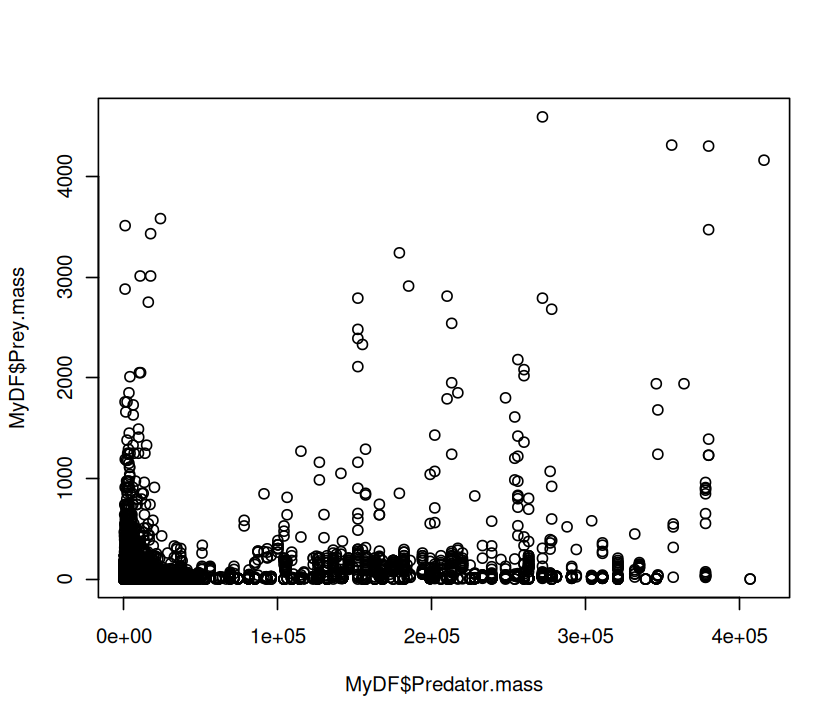

In [34]:
plot(MyDF$Predator.mass,MyDF$Prey.mass)

That doesn't look very meaningful! Let's try taking logarithms. *Why?* - Because body sizes across species tend to be log-normally distributed, with a lot of small species and a few large ones. Taking a log allows you to inspect the body size range in a meaningful (logarithmic) scale and reveals the true relationship. This also illustrates a important point. Just like statistical analyses, the effectiveness of data visualization too depends on the type of distribution of the data.

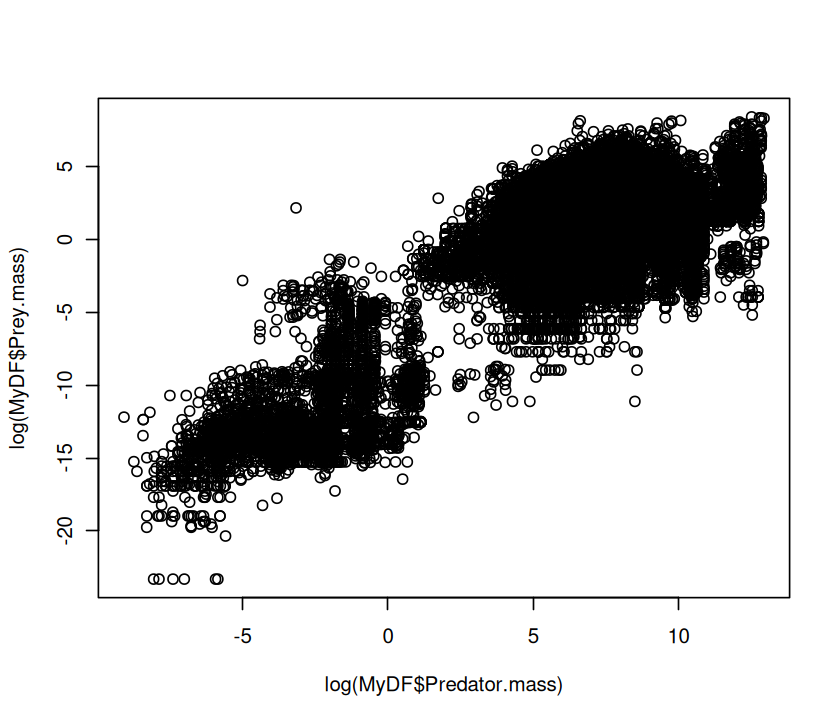

In [35]:
plot(log(MyDF$Predator.mass),log(MyDF$Prey.mass))

Let's look at the same using a base-10 log transform: 

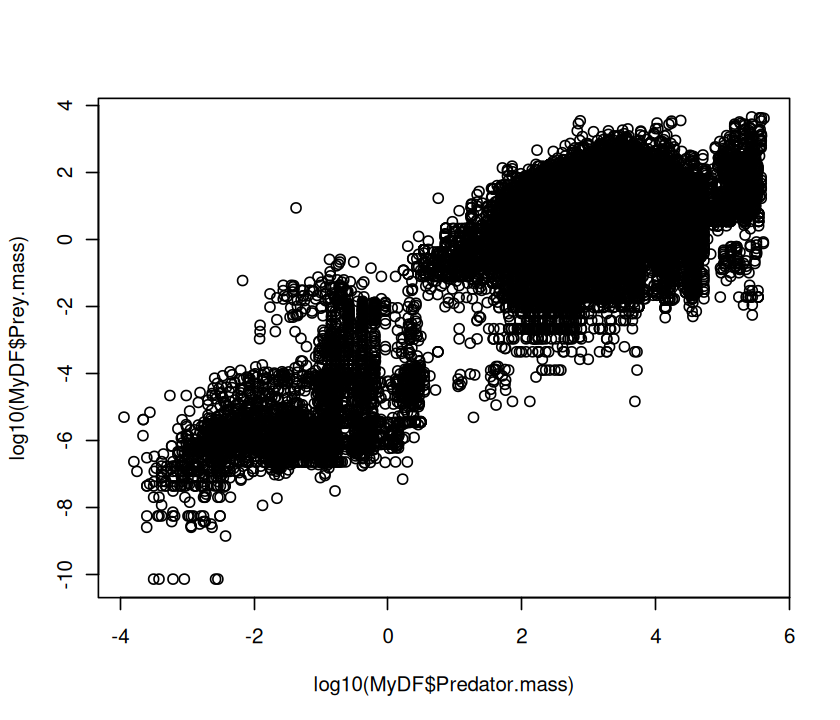

In [36]:
plot(log10(MyDF$Predator.mass),log10(MyDF$Prey.mass))

Using a `log10` transform is often a good idea because then you can see things in terms of "orders of magnitude", ($10^1$, $10^2$, $10^3$, etc), which makes it easier to determine  what the actual values in the original scale are.

We can change almost any aspect of the resulting graph; let's change the symbols by specifying the `p`lot `ch`aracters using `pch`:

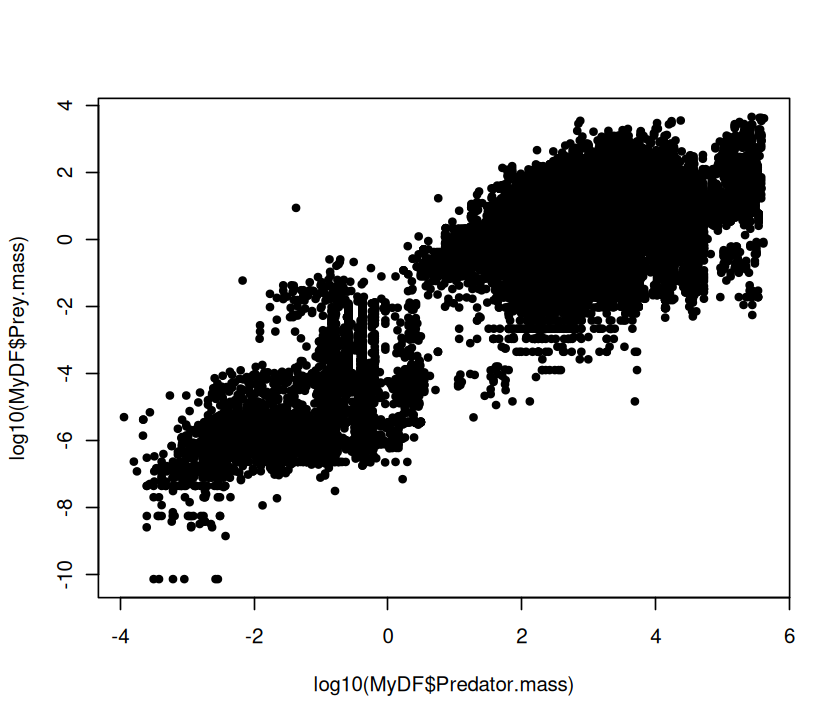

In [37]:
plot(log10(MyDF$Predator.mass),log10(MyDF$Prey.mass),pch=20) # Change marker

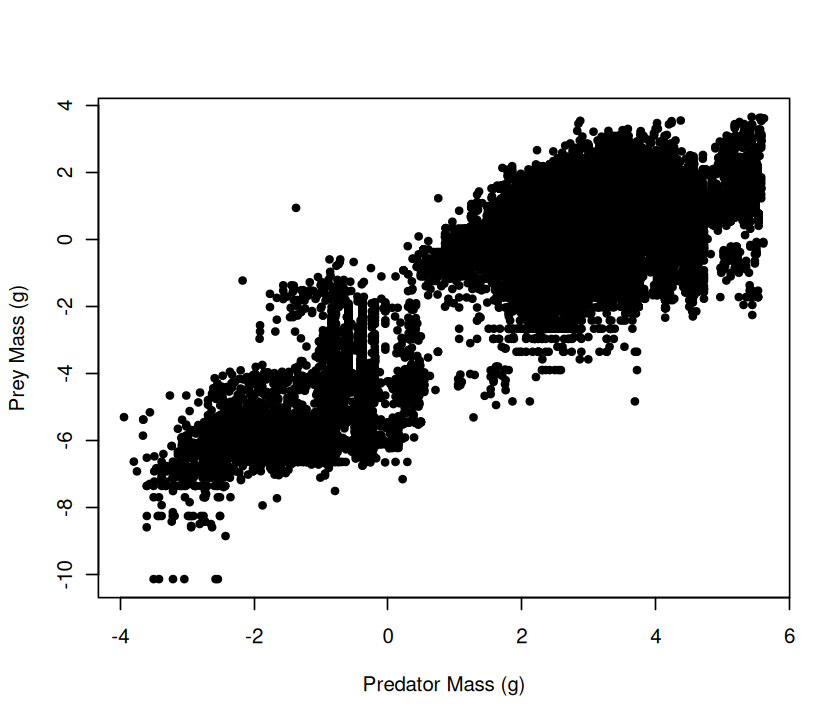

In [38]:
plot(log10(MyDF$Predator.mass),log10(MyDF$Prey.mass),pch=20, xlab = "Predator Mass (g)", ylab = "Prey Mass (g)") # Add labels

A really great summary of basic R graphical parameters can be [found here](https://www.statmethods.net/advgraphs/parameters.html).

### Histograms

Why did we have to take a logarithm to see the relationship between
predator and prey size? Plotting histograms of the two classes
(predator, prey) should be insightful, as we can then see the "marginal"
distributions of the two variables.

Let's first plot a histogram of predator body masses:

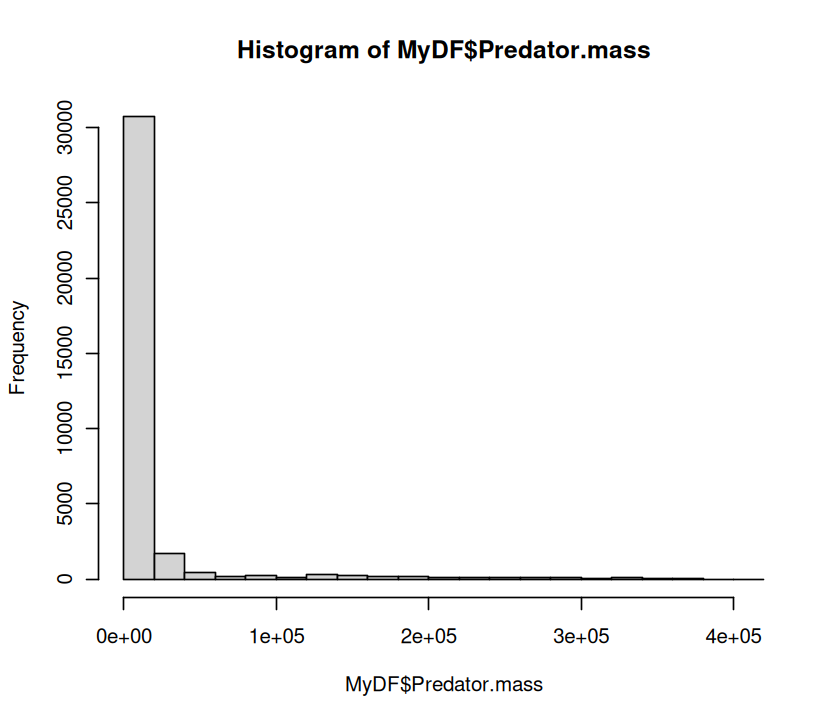

In [39]:
hist(MyDF$Predator.mass)

Clearly, the data are heavily right skewed, with small body sized organisms dominating (that's a general pattern, as mentioned above). Let's now take a logarithm and see if we can get a better idea of what the distribution of predator sizes looks like:

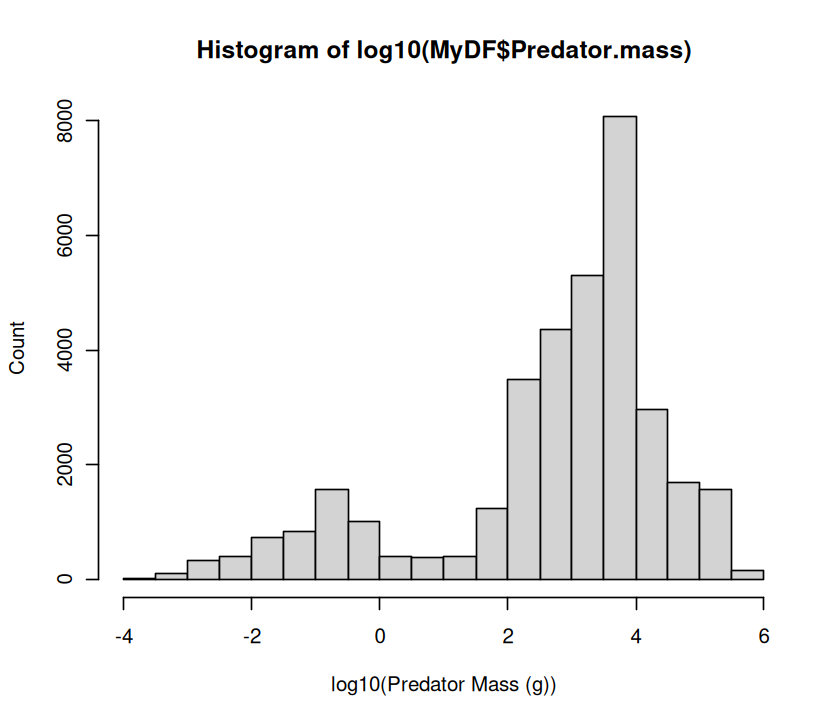

In [40]:
hist(log10(MyDF$Predator.mass), xlab = "log10(Predator Mass (g))", ylab = "Count") # include labels

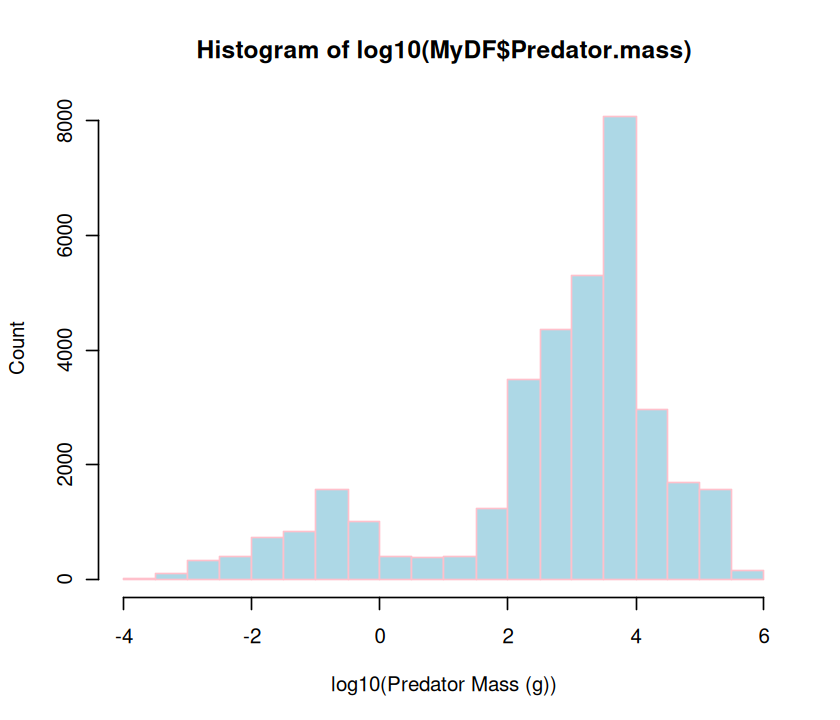

In [41]:
hist(log10(MyDF$Predator.mass),xlab="log10(Predator Mass (g))",ylab="Count", 
    col = "lightblue", border = "pink") # Change bar and borders colors 

So, taking a log really makes clearer what the distribution of body predator sizes looks like. *Try the same with prey body masses.*

$\star$ You can do a lot of beautification and fine-tuning of your R plots! As an exercise, try adjusting the histogram bin widths to make them same for the predator and prey, and making the x and y labels larger and in boldface. To get started, look at the help documentation of `hist`.

### Subplots

We can also plot both predator and prey body masses in different sub-plots using `par` so that we can compare them visually.

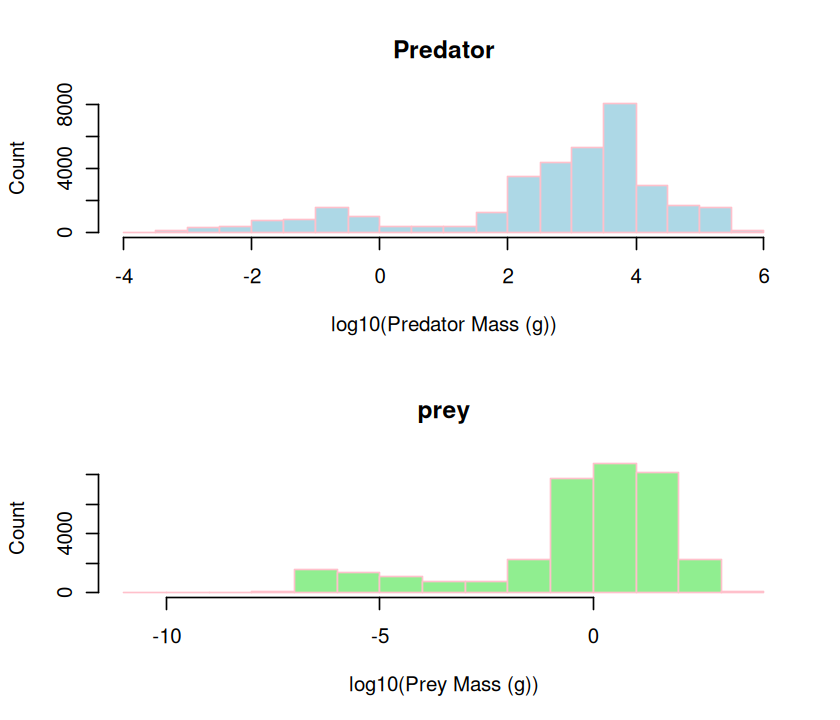

In [42]:
par(mfcol=c(2,1)) #initialize multi-paneled plot
par(mfg = c(1,1)) # specify which sub-plot to use first 
hist(log10(MyDF$Predator.mass),
    xlab = "log10(Predator Mass (g))", ylab = "Count", col = "lightblue", border = "pink", 
    main = 'Predator') # Add title
par(mfg = c(2,1)) # Second sub-plot
hist(log10(MyDF$Prey.mass), xlab="log10(Prey Mass (g))",ylab="Count", col = "lightgreen", border = "pink", main = 'prey')

The `par()` function can set multiple graphics parameters (not just multi-panel plots), including figure margins, axis labels, and more. Check out the [help for this function](https://www.rdocumentation.org/packages/graphics/versions/3.5.1/topics/par).

Another option for making multi-panel plots is the `layout` function.

### Overlaying plots

Better still, we would like to see if the predator mass and prey mass distributions are similar by overlaying them.

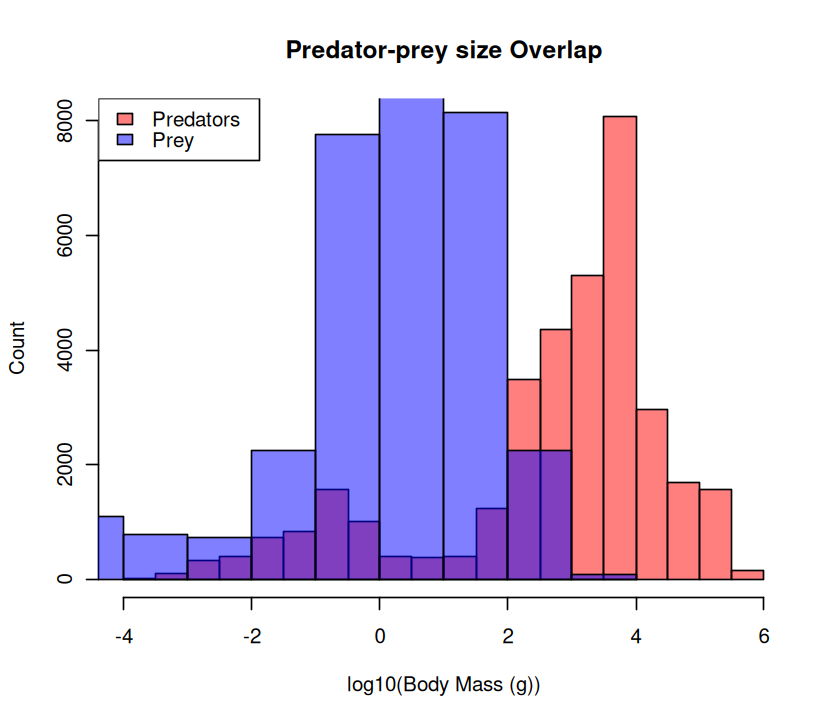

In [43]:
hist(log10(MyDF$Predator.mass), # Predator histogram
    xlab="log10(Body Mass (g))", ylab="Count", 
    col = rgb(1, 0, 0, 0.5), # Note 'rgb', fourth value is transparency
    main = "Predator-prey size Overlap") 
hist(log10(MyDF$Prey.mass), col = rgb(0, 0, 1, 0.5), add = TRUE) # Plot prey
legend('topleft',c('Predators','Prey'),   # Add legend
    fill=c(rgb(1, 0, 0, 0.5), rgb(0, 0, 1, 0.5))) # Define legend colors

Plot annotation with text can be done with either single or double quotes, i.e., 'Plot Title' or "Plot Title", respectively. But it is  generally a good idea to use double quotes because sometimes you would like to use an apostrophe in your title or axis label strings.

&#9733; It would be nicer to have both the plots with the same bin sizes – try to do it

### Boxplots

Box plots are another way to show the distribution of data.  
They display the **median** as a solid horizontal line, and the **interquartile range (IQR)** as the box, which contains the middle 50% of the data.  
The **whiskers** typically extend to 1.5× the IQR on either side, and **outliers** beyond this range are shown as individual points. This provides a compact summary of how values are spread and centered.

![Boxplot](graphics/Boxplot.svg)

Although box plots may seem more *primitive* than histograms or kernel density estimates (KDEs), they are a very useful method of visualising data.  
While they show less detail than a full distribution plot (since they hide the shape of the data), they offer several advantages:

- Because box plots are small and simple, they allow for quick visual comparison between multiple datasets.  
- They are not influenced by the choice of bin width (as histograms are) or bandwidth (as Kernal density estimations are).  
- They provide a quick visual summary of variability and potential outliers.


```{image} ./graphics/Boxplot_vs_PDF.svg
:alt: A boxplot compared with a probability density function
:width: 500px
:align: center
```

Now, let’s try plotting box plots instead of histograms to explore how they summarise data differently.

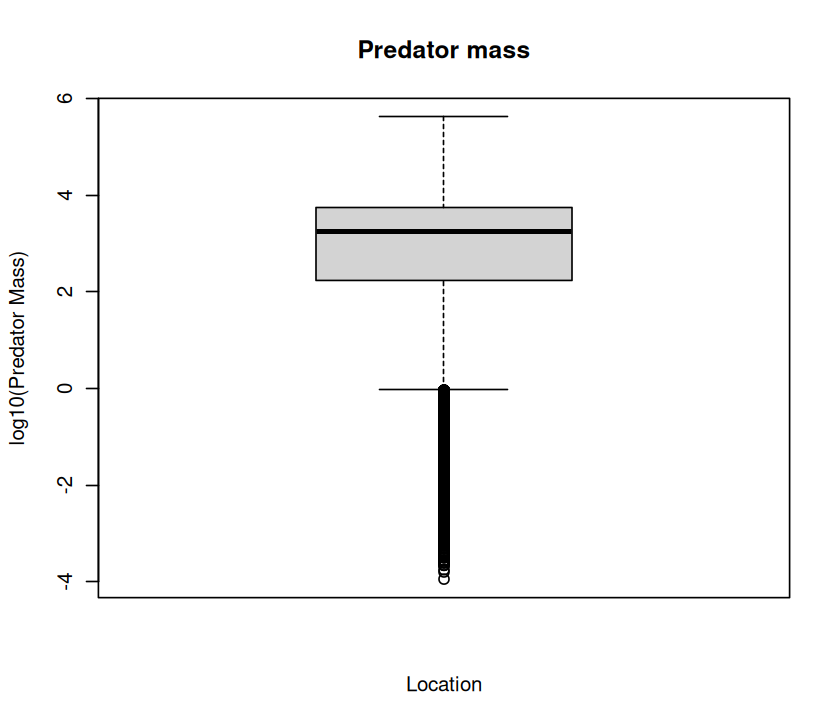

In [44]:
boxplot(log10(MyDF$Predator.mass), xlab = "Location", ylab = "log10(Predator Mass)", main = "Predator mass")

Now let's see how many locations the data are from:

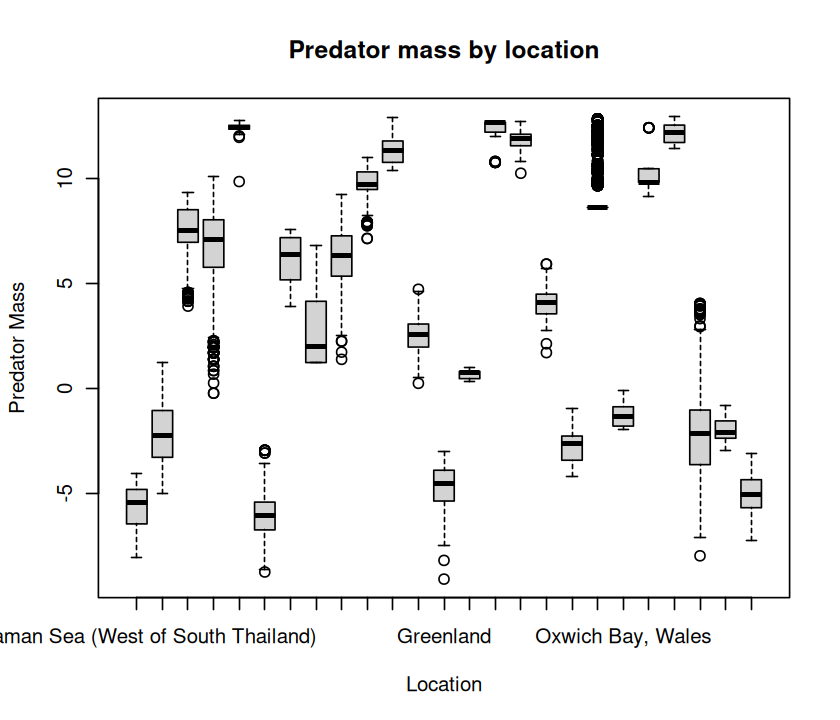

In [45]:
boxplot(log(MyDF$Predator.mass) ~ MyDF$Location, # Why the tilde?
    xlab = "Location", ylab = "Predator Mass",
    main = "Predator mass by location")

Note the tilde (`~`). This is to tell R to subdivide or categorize your analysis and plot by the "Factor" location. More on this later.

That's a lot of locations! You will need an appropriately wide plot to see all the boxplots adequately. Now let's try boxplots by feeding interaction type:

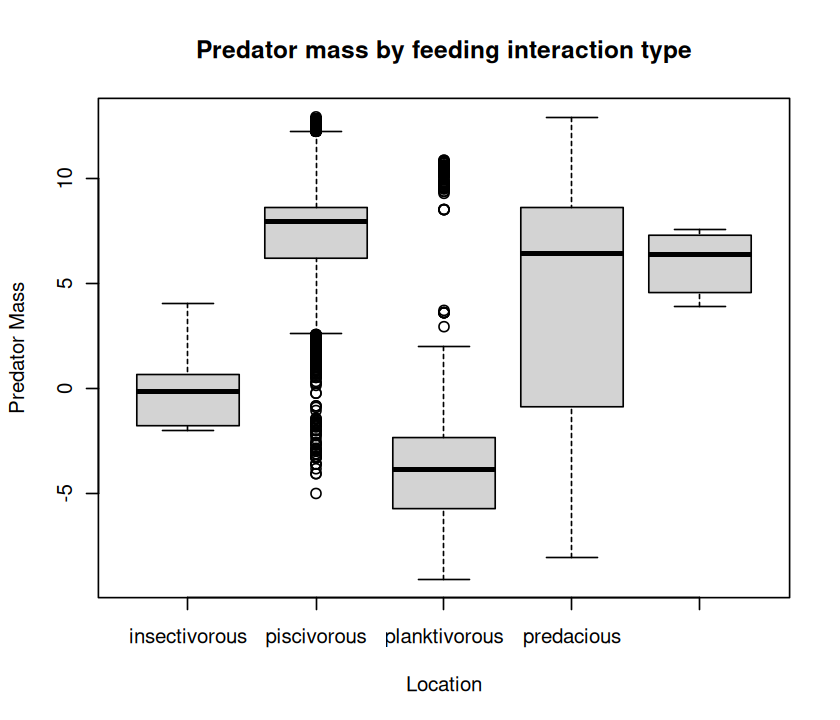

In [46]:
boxplot(log(MyDF$Predator.mass) ~ MyDF$Type.of.feeding.interaction,
    xlab = "Location", ylab = "Predator Mass",
    main = "Predator mass by feeding interaction type")

### Combining plot types

It would be nice to see both the predator and prey (marginal) distributions as well as the scatterplot for an exploratory analysis. We can do this by adding boxplots of the marginal variables to the scatterplot.

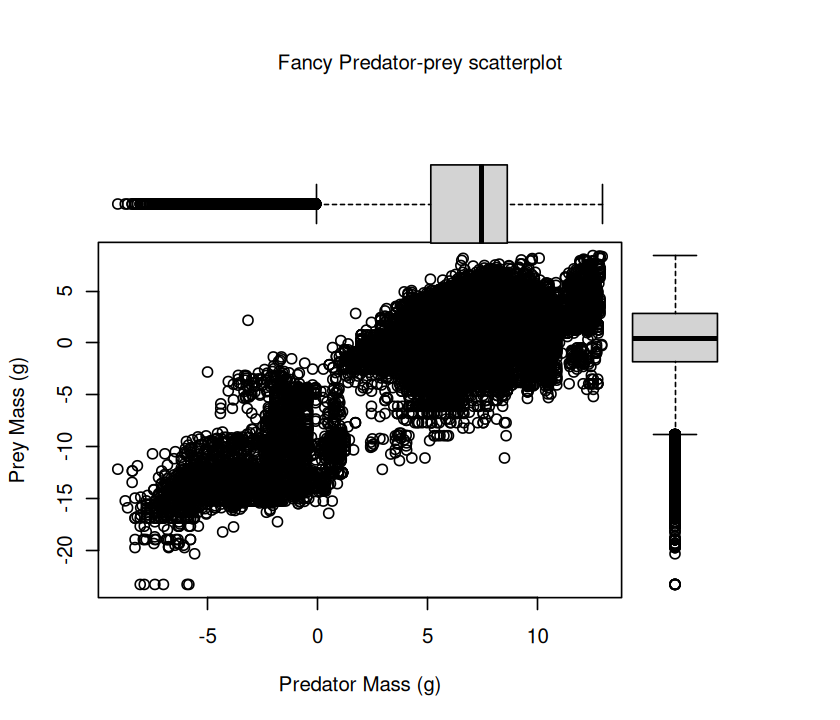

In [47]:
 par(fig=c(0,0.8,0,0.8)) # specify figure size as proportion
 plot(log(MyDF$Predator.mass),log(MyDF$Prey.mass), xlab = "Predator Mass (g)", ylab = "Prey Mass (g)") # Add labels
 par(fig=c(0,0.8,0.4,1), new=TRUE)
 boxplot(log(MyDF$Predator.mass), horizontal=TRUE, axes=FALSE)
 par(fig=c(0.55,1,0,0.8),new=TRUE)
 boxplot(log(MyDF$Prey.mass), axes=FALSE)
 mtext("Fancy Predator-prey scatterplot", side=3, outer=TRUE, line=-3)

To understand this plotting method, think of the full graph area as going from (0,0) in the lower left corner to (1,1) in the upper right corner. The format of the `fig=` parameter is a numerical vector of the form `c(x1, x2, y1, y2)`, corresponding to `c(bottom, left, top, right)`. First, ` par(fig=c(0,0.8,0,0.8))` sets up the scatterplot going from 0 to 0.8 on the x axis and 0 to 0.8 on the y axis, leaving some area for the boxplots at the top and right. The top boxplot goes from 0 to 0.8 on the x axis and 0.4 to 1 on the y axis. The right hand boxplot goes from 0.55 to 1 on the x axis and 0 to 0.8 on the y axis. You can experiment with these proportions to change the spacings between plots.

This plot is useful, because it shows you what the marginal distributions of the two variables (Predator mass and Prey mass) are. 


Below you will learn to use `ggplot` to produce a much more elegant, pretty multi-panel plots. 


### Saving your graphics

And you can also save the figure in a vector graphics format like a pdf. It is important to learn to do this, because you want to be able to save your plots in good resolution, and want to avoid the manual steps of
clicking on the figure, doing "save as", etc. So let's save the figure as a PDF:

In [48]:
pdf("results/Pred_Prey_Overlay.pdf", # Open a PDF file under results/
    11.7, 8.3) # These numbers are page dimensions in inches
hist(log(MyDF$Predator.mass), # Plot predator histogram (note 'rgb')
    xlab="Body Mass (g)", ylab="Count", col = rgb(1, 0, 0, 0.5), main = "Predator-Prey Size Overlap") 
hist(log(MyDF$Prey.mass), # Plot prey weights
    col = rgb(0, 0, 1, 0.5), 
    add = TRUE)  # Add to the same plot
legend('topleft',c('Predators','Prey'), # Add legend
    fill=c(rgb(1, 0, 0, 0.5), rgb(0, 0, 1, 0.5))) 
graphics.off(); #you can also use dev.off() 

Always try to save results in a vector format, which can be scaled up to any size. For more on vector vs raster images/graphics, [see this](https://en.wikipedia.org/wiki/Vector_graphics).

The figure is saved under `results/`. Keep source data in `data/`, scripts in `code/`, and generated tables and figures in `results/`. Because every command is run from the project root, the same paths work in this chapter and in the preceding R chapter.

You can also try other graphic output formats. For example, `png()` (a raster format) instead of `pdf()`. As always, look at the help documentation of each of these commands!

## Integrated practical: from checked data to a figure

Download {download}`the observations <../data/bootcamp_observations.csv>`, {download}`boundary observations <../data/bootcamp_observations_boundary.csv>` and {download}`invalid observations <../data/bootcamp_observations_invalid.csv>` into `data/` in a project with `code/`, `data/` and `results/` directories. Write `code/observations_practice.R` as a complete script: check that counts are non-negative integers or missing, remove exact duplicate rows, keep known zero counts distinct from missing counts, and report a known-count total and missing-count number for each site. Reject invalid counts with a clear message. Use the boundary and invalid files to check your decisions. Then carry the clean summary through to a figure that another person can rerun and understand.

1. Read the observations and produce the site summary from your checked data. Keep the raw CSV unchanged.
2. Save the summary as `results/observations_by_site.csv`, with column names that make sense without looking back at the script.
3. Draw a well-labelled figure of the observed totals by site, using either base R or `ggplot2`, and save it as `results/observations_by_site.pdf`.
4. Make the distinction between zero observations and entirely missing observations visible in the figure or its caption. Do not turn the all-missing result into a zero.
5. Add two or three sentences explaining what the figure shows and what the data do not allow you to conclude.
6. Close R and run the whole script again from the project root with `Rscript code/observations_practice.R`. Check that it recreates both output files.

Make the same figure with the other plotting system. Compare the choices you had to make rather than asking which version is prettier.

## Practical: body-mass distributions

Download {download}`the predator-prey data <../data/ecol_archives_e_089_51_d_1.csv>` into `data/` in a project with `code/`, `data/` and `results/` directories. Write a script that reads this file and saves three figures, each containing subplots of distributions of predator mass, prey mass, and the size ratio of prey mass over predator mass *by feeding interaction type*. Use logarithms of masses (or size ratios)for all three plots. In addition, the script should calculate the (log) mean and median predator mass, prey mass and predator-prey size-ratios to a csv file.

Call the script `PP_Dists.R` and save it in `code/`. Running it from the project root should create three files—`Pred_Subplots.pdf`, `Prey_Subplots.pdf`, and `SizeRatio_Subplots.pdf`—and a CSV file called `PP_Results.csv` under `results/`. The CSV file should contain the mean and median log predator mass, prey mass, and predator-prey size ratio by feeding type, with clear column names. You will need to create a data frame or matrix to hold these calculations before writing them.

The script should not depend on objects left in an R session. Read `data/ecol_archives_e_089_51_d_1.csv` and write outputs under `results/`, creating that directory if needed. Run it from the project root with `Rscript code/PP_Dists.R` and rerun it to check reproducibility.

Use the `par()` function to create the subplots. For calculating the body size statistics by feeding type, you can either use the "loopy" way — first obtaining a list of feeding types (look up the `unique` or `levels` functions) and then loop over them, using `subset` to extract the dataset by feeding type at each iteration, or the R-savvy way, by using `tapply` or `ddply` and avoiding looping altogether. You can also use tidyverse and `dplyr` for the data manipulations.

## Beautiful graphics in R

R can produce beautiful visualizations, but it typically takes a lot of work to obtain the desired result. This is because the starting point is pretty much a "bare" plot, and adding features commonly required for publication-grade figures (legends, statistics, regressions, sub-plotting etc.) can require a lot of small and painful additional arguments to the plotting commands *at the same time*, or even additional steps (such as the [fancy predator-prey scatterplot](#Combining-plot-types) above).

Moreover, it is very difficult to switch from one representation of the data to another (i.e., from boxplots to scatterplots), or to plot several datasets together. The R package `ggplot2` overcomes these issues, and produces truly high-quality, publication-ready graphics suitable for papers, theses and reports.

```{note}
**3D plots:** *Currently, `ggplot2` cannot be used to create 3D graphs or mosaic plots (but [see this](https://www.tylermw.com/3d-ggplots-with-rayshader)). In any case, most of you won't be needing 3D plots. If you do, there are many ways to do 3D plots using other plotting packages in R. In particular, look up the `scatterplot3d` and `plot3D` packages.*
```

`ggplot2` differs from other approaches as it attempts to provide a "grammar" for graphics in which each layer is the equivalent of a verb, subject etc. and a plot is the equivalent of a sentence. All graphs start with a layer showing the data, other layers and attributes/styles are added to modify the plot. Specifically, according to this grammar, a statistical graphic is a "mapping" from data to geometric objects (points, lines, bars; set using `geom`) with aesthetic attributes (colour, shape, size; set using `aes`).

For more on the ideas underlying ggplot, see the book "ggplot2: Elegant Graphics for Data Analysis", by H. Wickham (in your Reading directory). Also, the [ggplot2 website](http://ggplot2.tidyverse.org/) is an excellent resource.

If `ggplot2` is not available on your computer, look up the section on installing packages in the [R Chapter](r.ipynb).

For new work, build plots with `ggplot()`, aesthetic mappings and one or more geometries. This makes each part of the graphic explicit and gives you a route from a quick exploratory plot to a finished figure.

*Note that `ggplot2` only accepts data in data frames.*

### Legacy reference: quick plotting with `qplot`

Earlier versions of this chapter used `qplot()` as a bridge from base R graphics. It is now deprecated in `ggplot2`, so do not use this section as the starting point for new scripts. It remains here for the moment because you may encounter `qplot()` in older course or research code. For current work, read it only as a translation exercise and use the [`ggplot()` section below](#advanced-plotting-ggplot) to write your plots.

We will use the same predator-prey body size dataset again – you will soon see how much nice the same types of plots you made above look when done with ggplot!

First, load the package:

In [49]:
require(ggplot2)

#### Scatterplots

Let's start plotting the `Predator.mass` vs `Prey.mass`:

Warning message:
“`qplot()` was deprecated in ggplot2 3.4.0.”


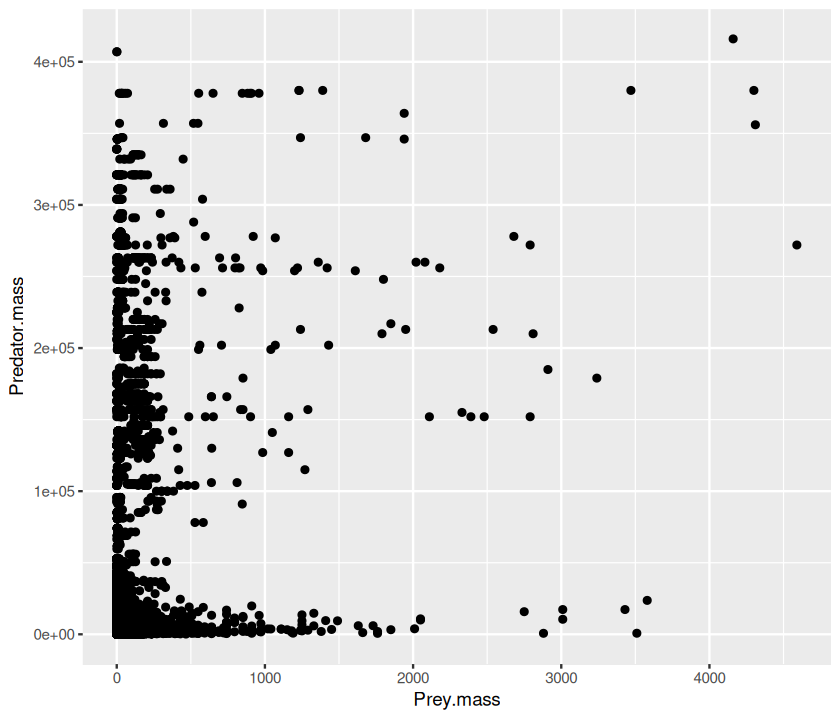

In [50]:
qplot(Prey.mass, Predator.mass, data = MyDF)

As before, let's take logarithms and plot:

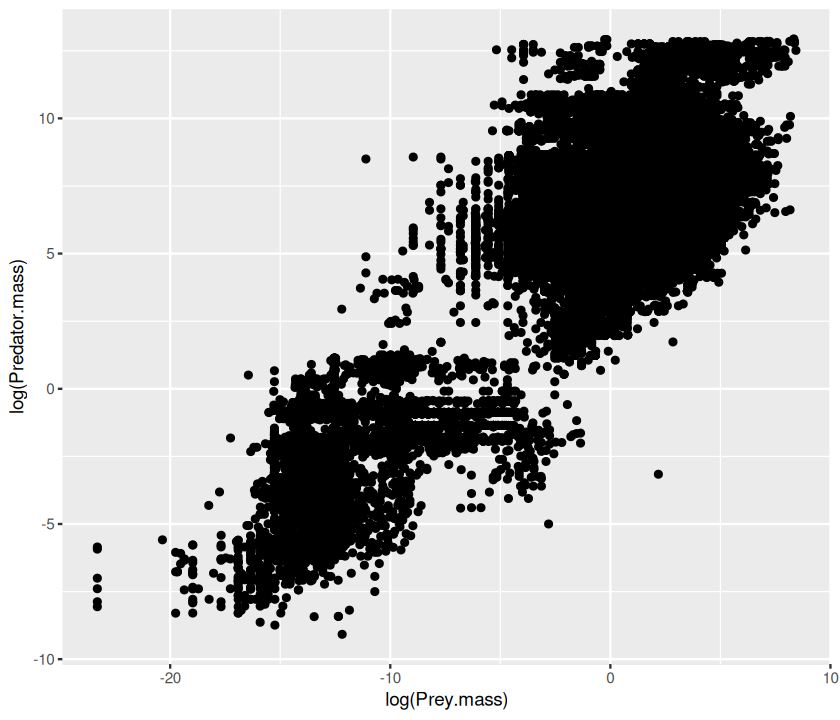

In [51]:
qplot(log(Prey.mass), log(Predator.mass), data = MyDF)

Now, color the points according to the type of feeding interaction:

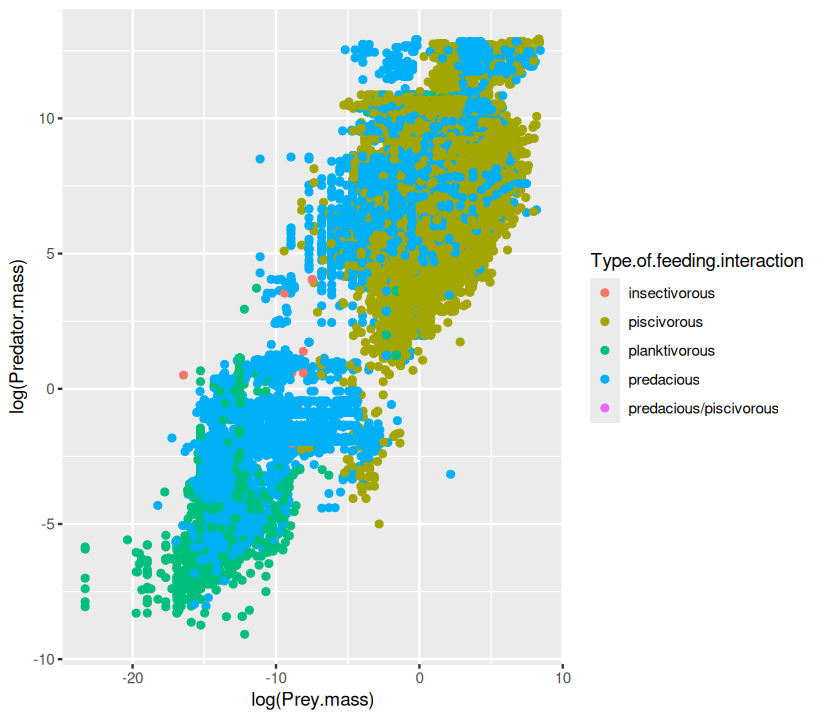

In [52]:
qplot(log(Prey.mass), log(Predator.mass), data = MyDF, colour = Type.of.feeding.interaction)

But the figure's aspect ratio is not very nice. Let's change it using the `asp` option:

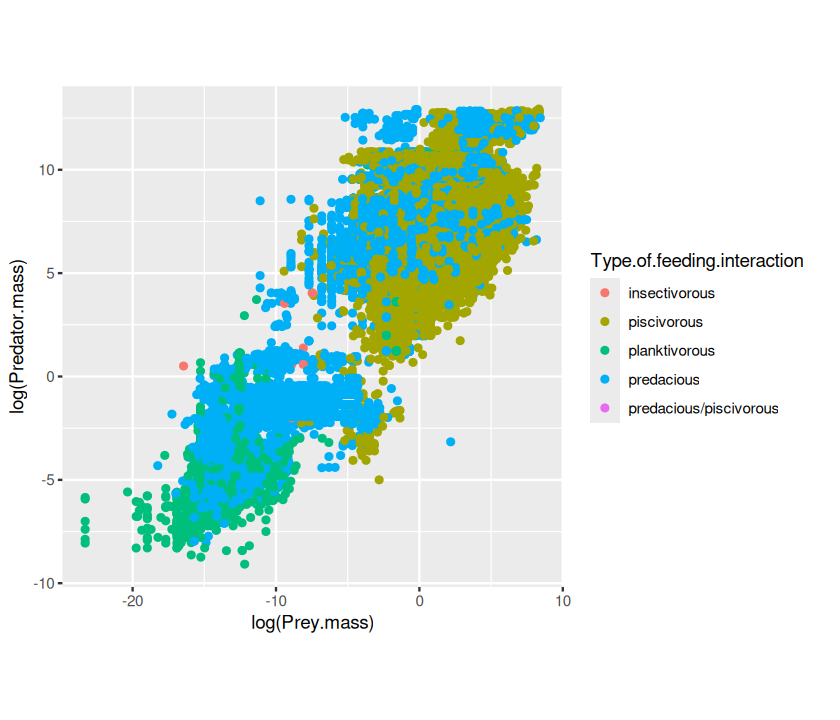

In [53]:
qplot(log(Prey.mass), log(Predator.mass), data = MyDF, colour = Type.of.feeding.interaction, asp = 1)

The same as above, but changing the shape:

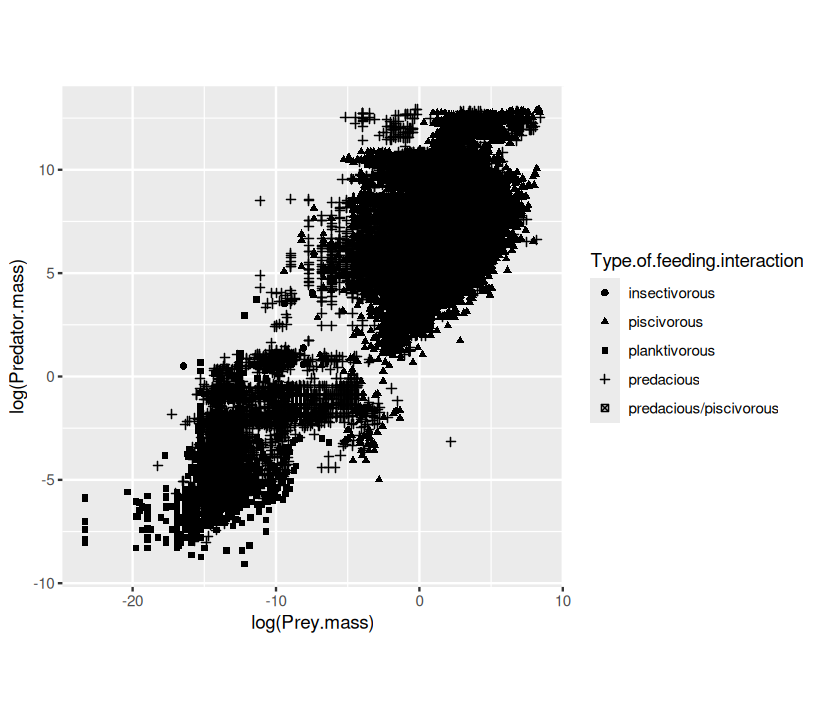

In [54]:
qplot(log(Prey.mass), log(Predator.mass), data = MyDF, shape = Type.of.feeding.interaction, asp = 1)

#### Aesthetic mappings

These examples demonstrate a key difference between `qplot` (and indeed, ggplot2's approach) and the standard `plot` command: When you want to assign colours, sizes or shapes to the points on your plot, using the `plot` command, it's your responsibility to convert (i.e., "map") a categorical variable in your data (e.g., type of feeding interaction in the above case) onto colors (or shapes) that `plot` knows how to use (e.g., by specifying "red", "blue", "green", etc).

ggplot does this mapping for you automatically, and also provides a legend! This makes it really easy to quickly include additional data (e.g., if a new feeding interaction type was added to the data) on the plot.

Instead of using ggplot's automatic mapping, if you want to manually set a color or a shape, you have to use `I()` (meaning "Identity"). To see this in practice, try the following:

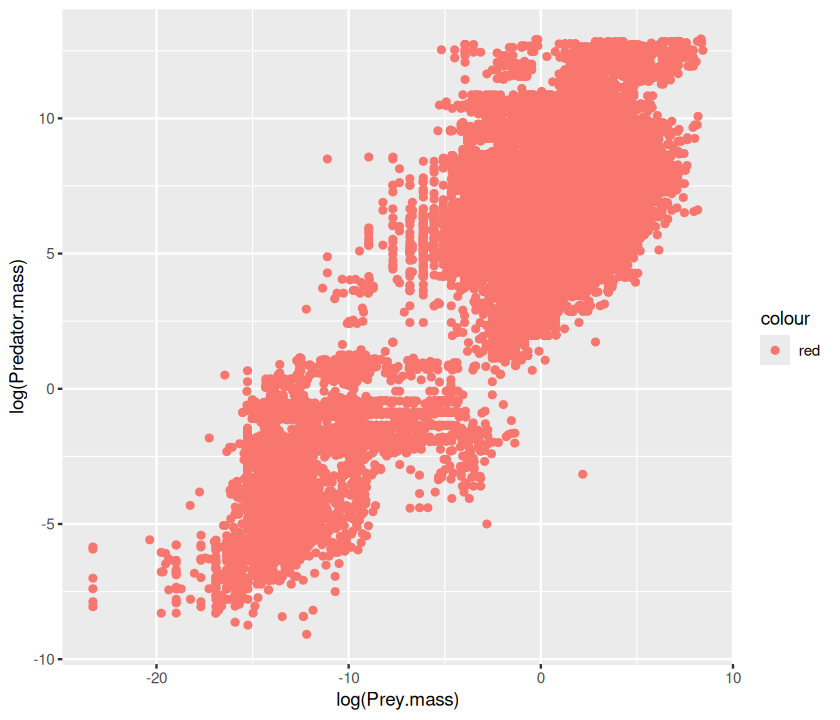

In [55]:
qplot(log(Prey.mass), log(Predator.mass), 
    data = MyDF, colour = "red")

You chose red, but ggplot used mapping to convert it to a particular
shade of red. To set it manually to the real red, do this:

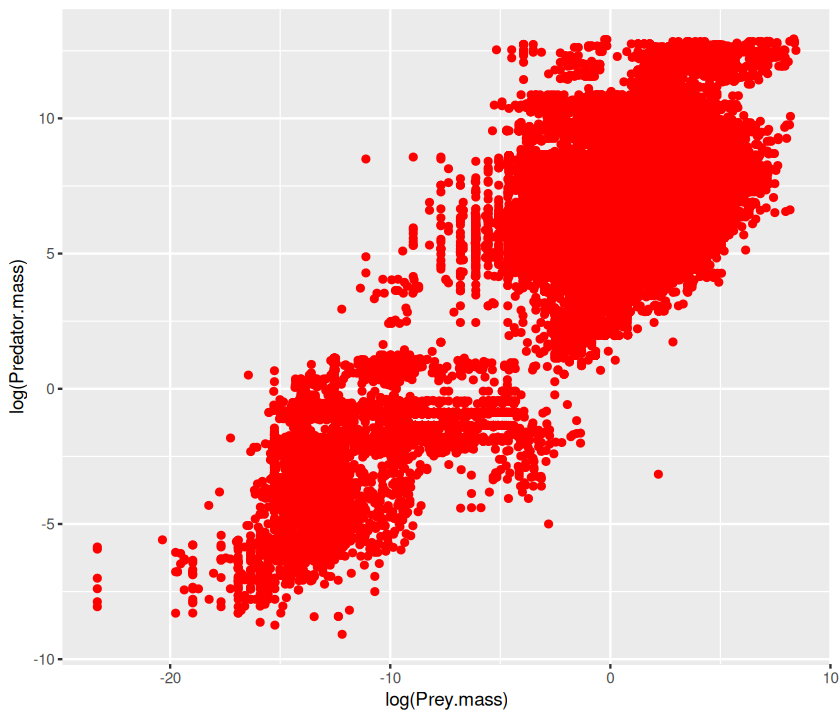

In [56]:
qplot(log(Prey.mass), log(Predator.mass), data = MyDF, colour = I("red"))

Similarly, for point size, compare these two:

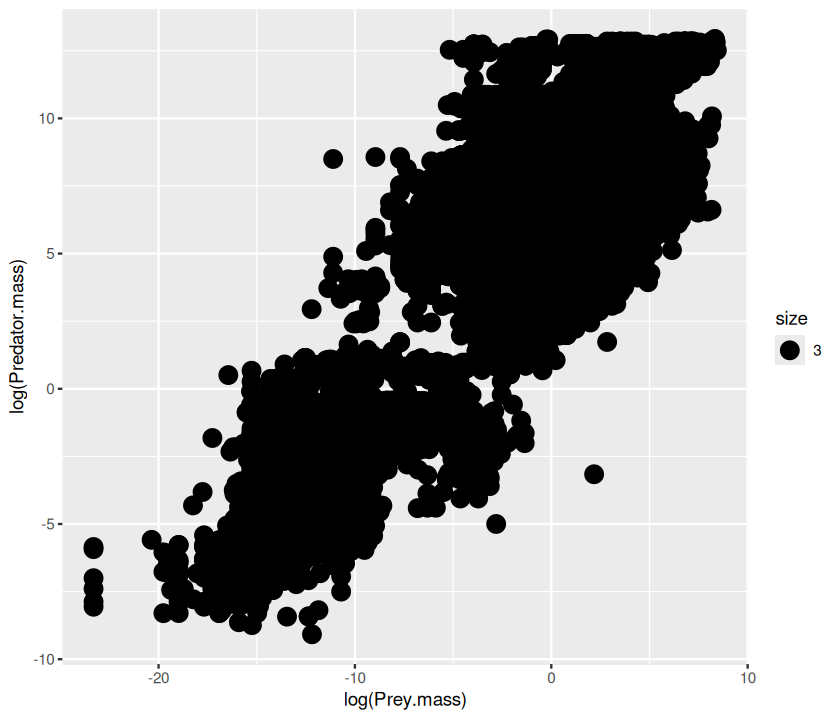

In [57]:
qplot(log(Prey.mass), log(Predator.mass), data = MyDF, size = 3) #with ggplot size mapping

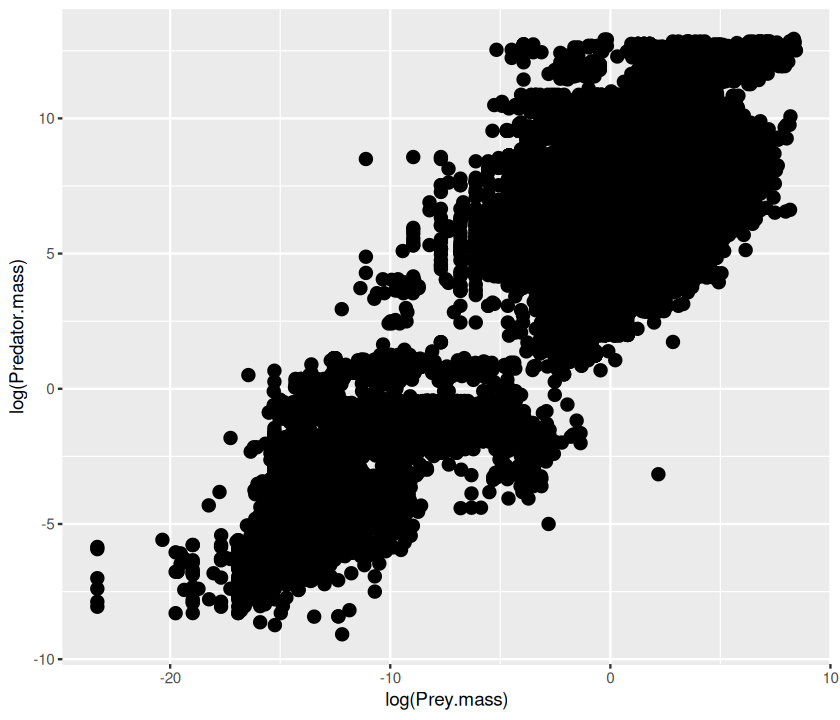

In [58]:
qplot(log(Prey.mass), log(Predator.mass),  data = MyDF, size = I(3)) #no mapping

But for shape, ggplot doesn't have a continuous mapping because shapes are a discrete variable.So

```r
qplot(log(Prey.mass), log(Predator.mass), data = MyDF, shape = 3)
```
will give an error.

Instead, try this: 

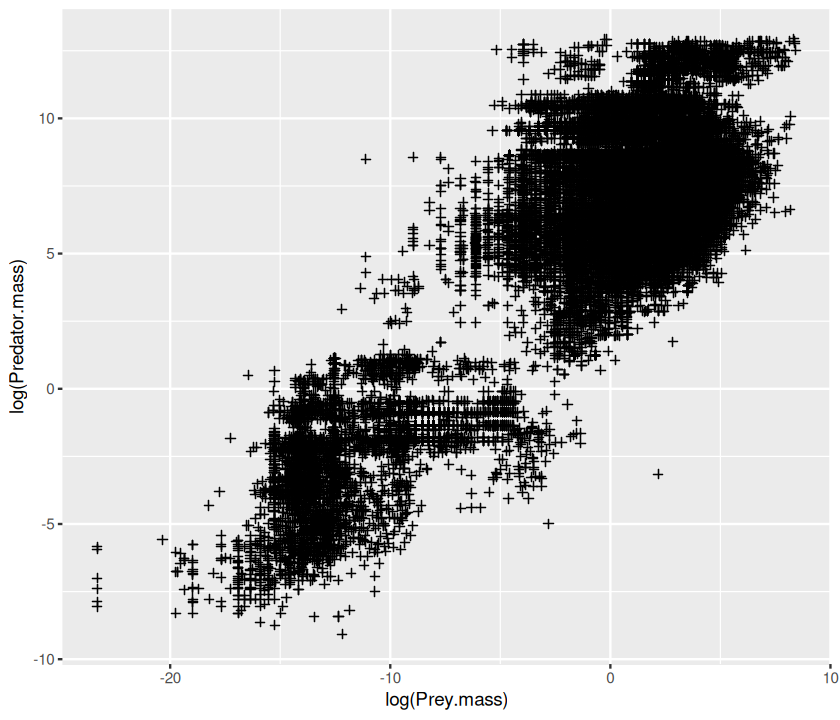

In [59]:
qplot(log(Prey.mass), log(Predator.mass), data = MyDF, shape= I(3))

#### Setting transparency

Because there are so many points, we can make them semi-transparent using `alpha` so that the overlaps can be seen:

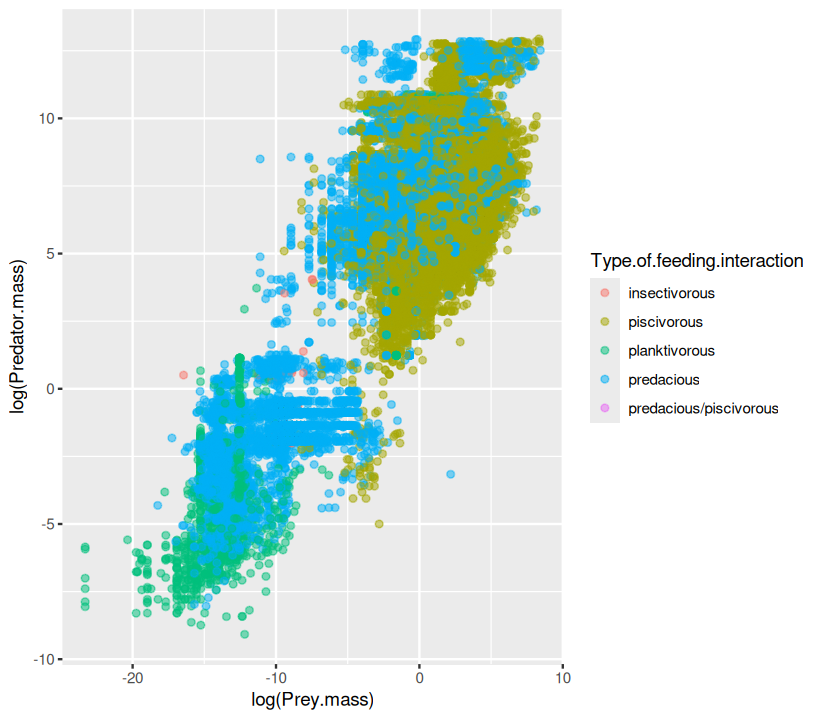

In [60]:
qplot(log(Prey.mass), log(Predator.mass), data = MyDF, colour = Type.of.feeding.interaction, alpha = I(.5))

Here, try using `alpha = .5` instead of `alpha = I(.5)` and see what happens.

#### Adding smoothers and regression lines

Now add a smoother to the points:

`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'


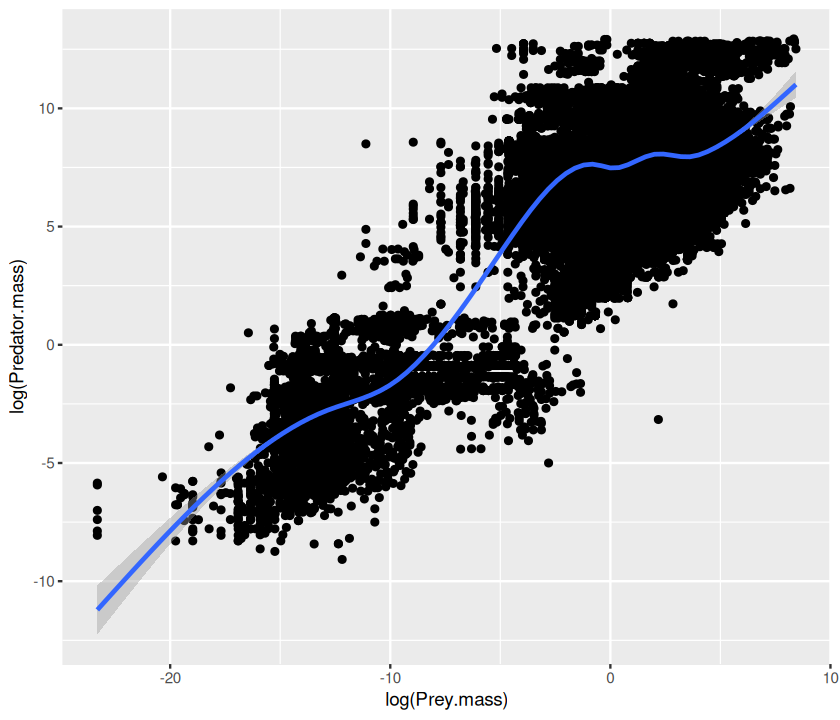

In [61]:
qplot(log(Prey.mass), log(Predator.mass), data = MyDF, geom = c("point", "smooth"))

If we want to have a linear regression, we need to specify the method as
being `lm`:

`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'


`geom_smooth()` using formula = 'y ~ x'


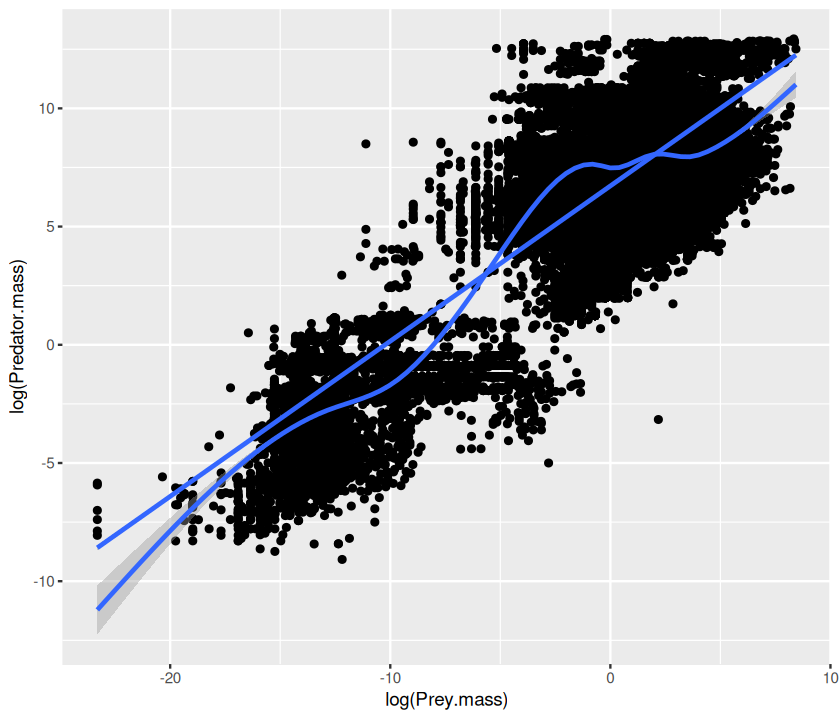

In [62]:
qplot(log(Prey.mass), log(Predator.mass), data = MyDF, geom = c("point", "smooth")) + geom_smooth(method = "lm")

`lm` stands for `l`inear `m`odels. Linear regression is a type of linear model. More on this in the [BASIC DATA ANALYSES AND STATISTICS](../part-basic-stats.md) section of these notes.  

We can also add a "smoother" for each type of interaction:

`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'


`geom_smooth()` using formula = 'y ~ x'


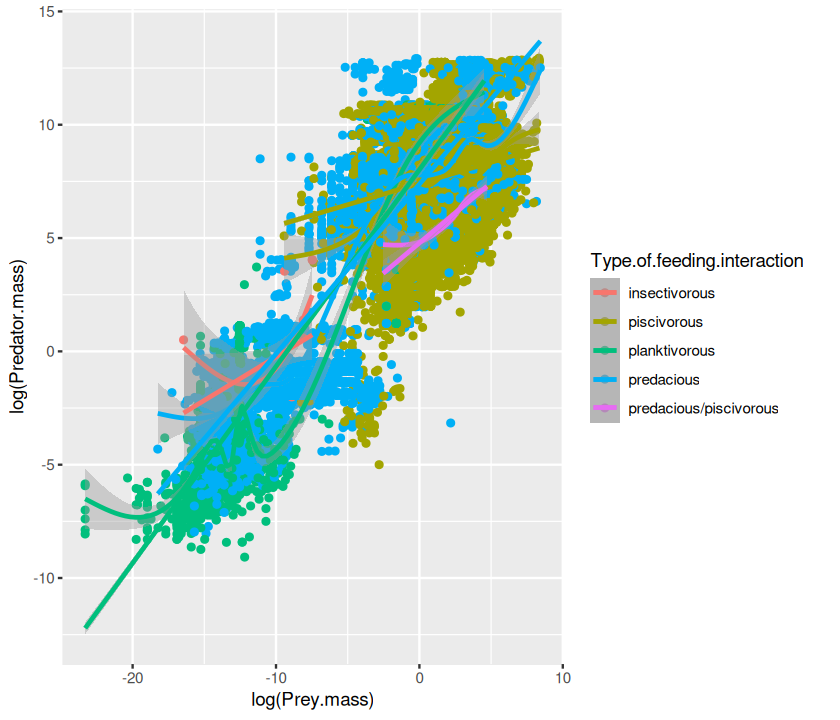

In [63]:
qplot(log(Prey.mass), log(Predator.mass), data = MyDF, geom = c("point", "smooth"), 
      colour = Type.of.feeding.interaction) + geom_smooth(method = "lm")

To extend the lines to the full range, use `fullrange = TRUE`:

`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'


`geom_smooth()` using formula = 'y ~ x'


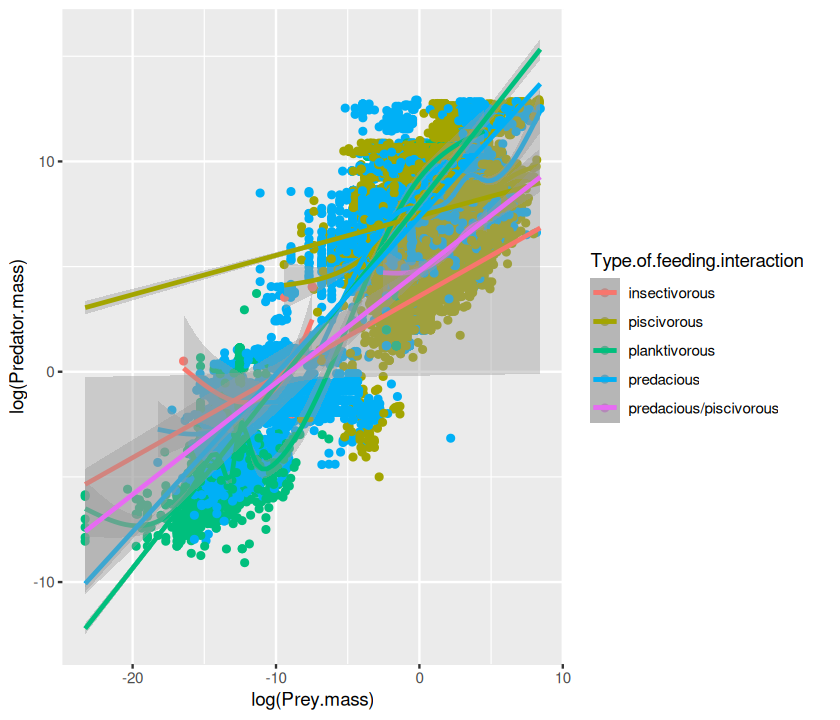

In [64]:
qplot(log(Prey.mass), log(Predator.mass), data = MyDF, geom = c("point", "smooth"),
      colour = Type.of.feeding.interaction) + geom_smooth(method = "lm",fullrange = TRUE)

Now let's see how the ratio between prey and predator mass changes according to the type of interaction:

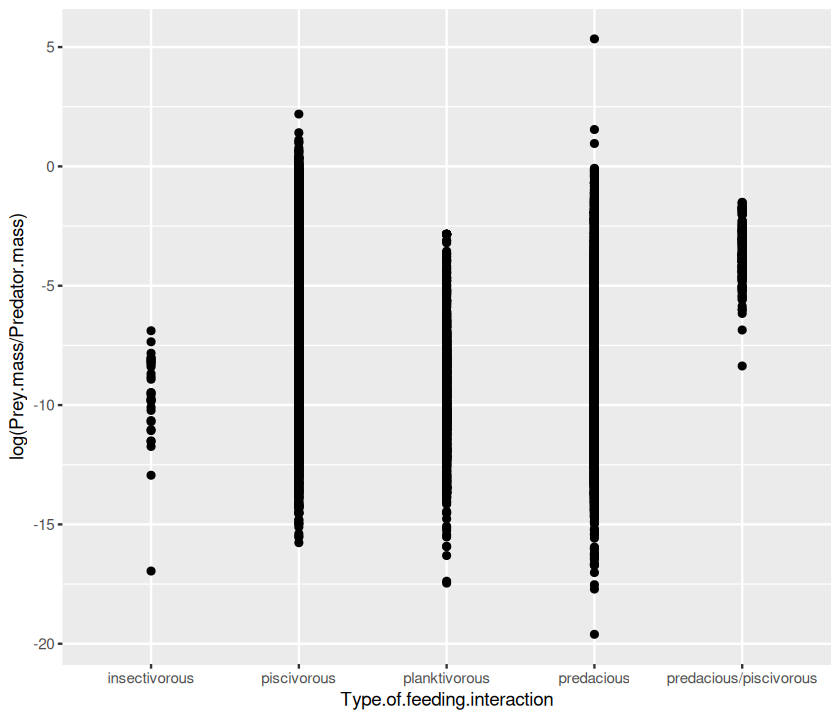

In [65]:
qplot(Type.of.feeding.interaction, log(Prey.mass/Predator.mass), data = MyDF)

Because there are so many points, we can "jitter" them to get a better
idea of the spread:

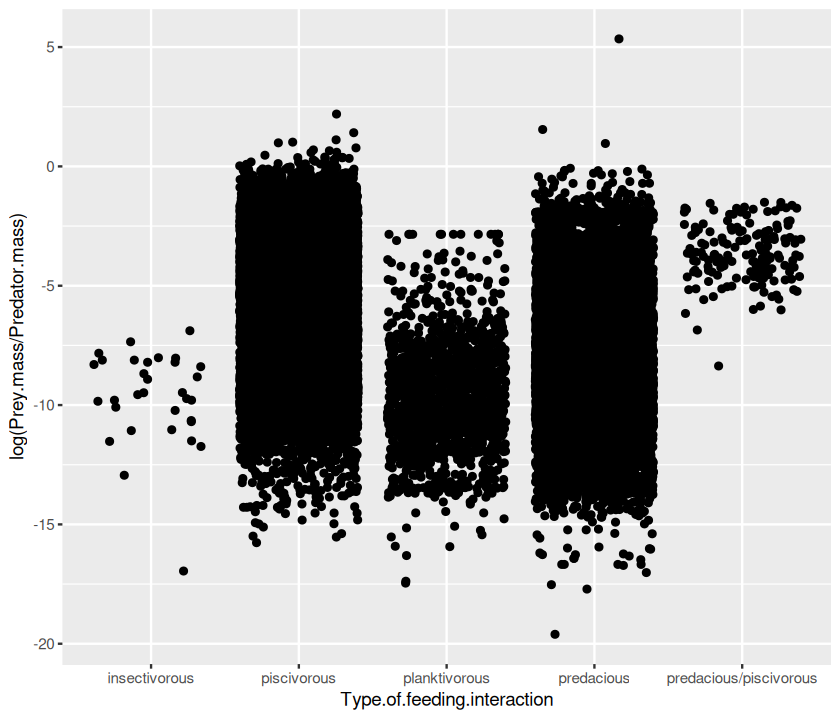

In [66]:
qplot(Type.of.feeding.interaction, log(Prey.mass/Predator.mass), data = MyDF, geom = "jitter")

#### Boxplots

Or we can draw a boxplot of the data (note the `geom` argument, which stands for `geom`etry):

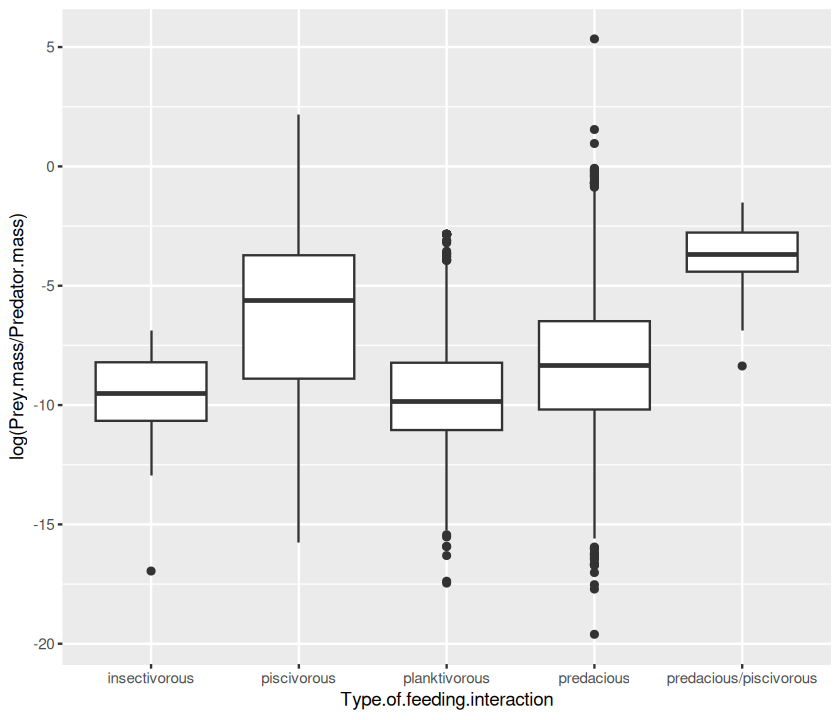

In [67]:
qplot(Type.of.feeding.interaction, log(Prey.mass/Predator.mass), data = MyDF, geom = "boxplot")

#### Histograms and density plots

Now let's draw an histogram of predator-prey mass ratios:

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


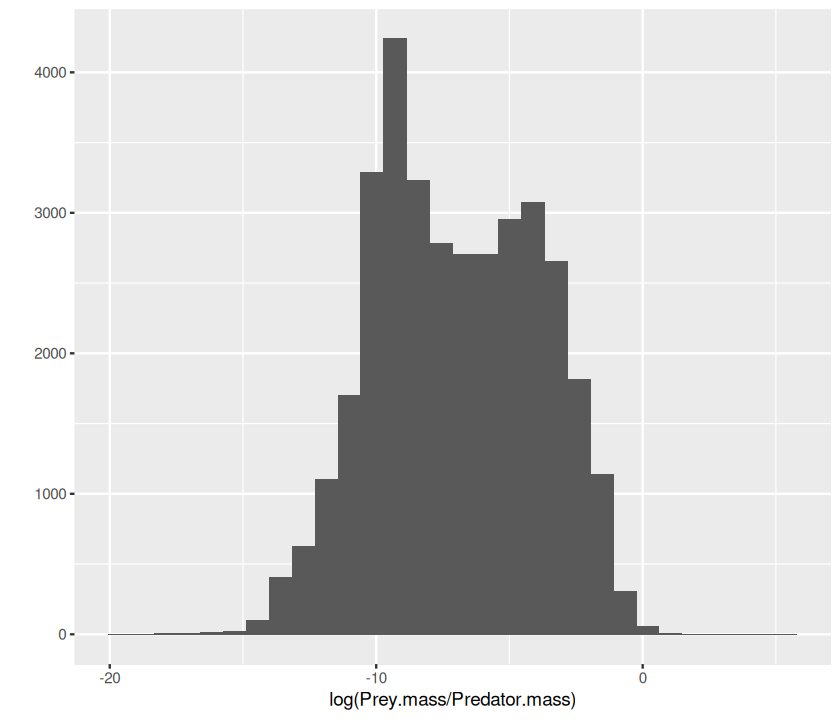

In [68]:
qplot(log(Prey.mass/Predator.mass), data = MyDF, geom =  "histogram")

Color the histogram according to the interaction type:

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


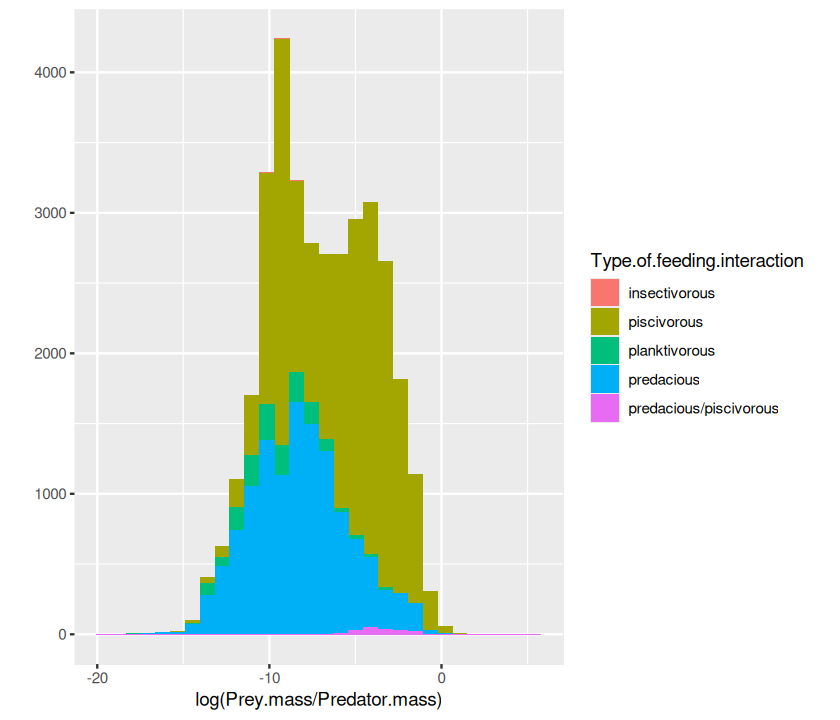

In [69]:
qplot(log(Prey.mass/Predator.mass), data = MyDF, geom =  "histogram", 
      fill = Type.of.feeding.interaction)

You can also define your own  bin widths (in units of the x axis):

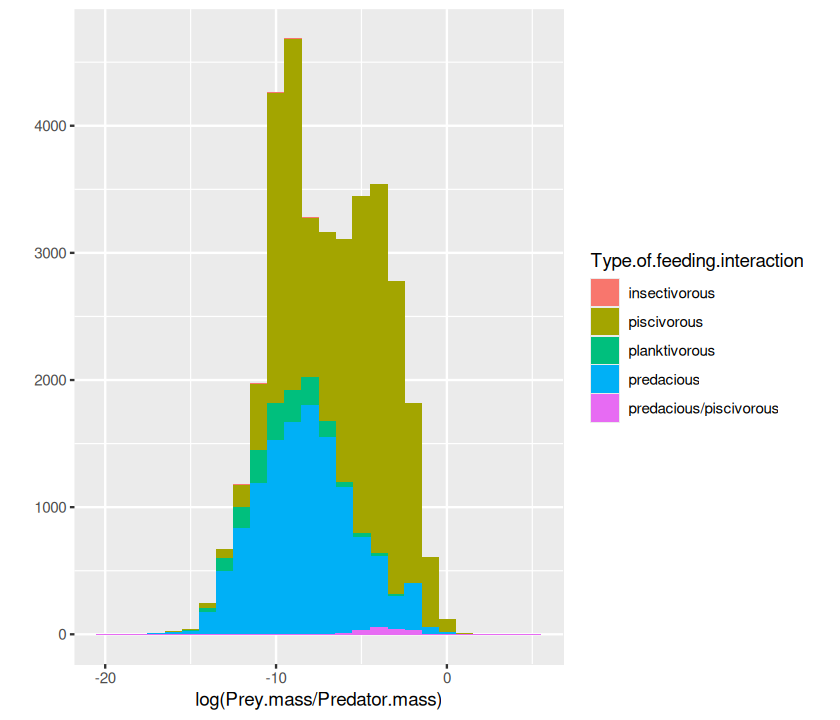

In [70]:
qplot(log(Prey.mass/Predator.mass), data = MyDF, geom =  "histogram", 
      fill = Type.of.feeding.interaction, binwidth = 1)

To make it easier to read, we can plot the smoothed density of the data:

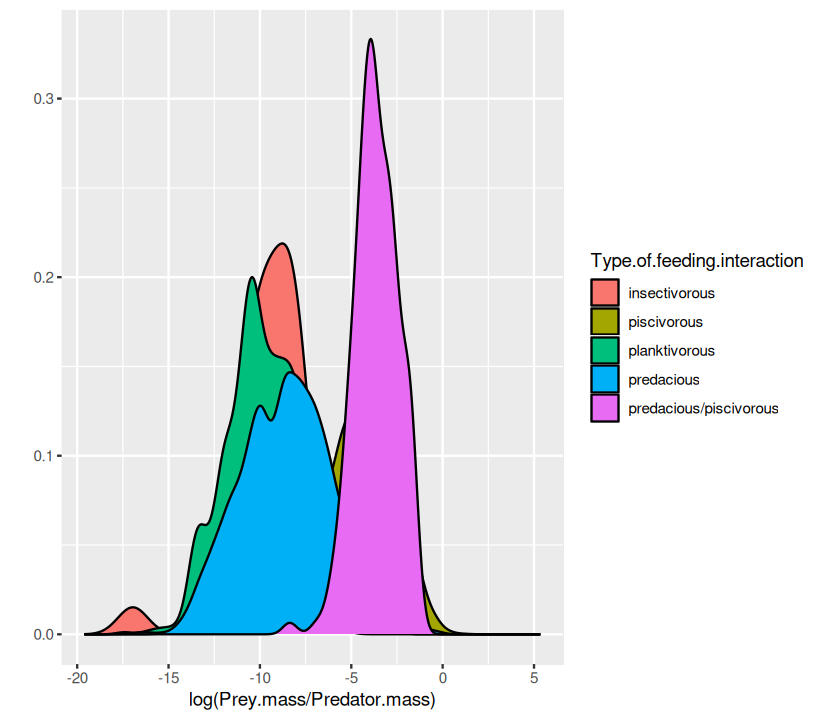

In [71]:
qplot(log(Prey.mass/Predator.mass), data = MyDF, geom =  "density", 
      fill = Type.of.feeding.interaction)

And you can make the densities transparent so that the overlaps are visible:

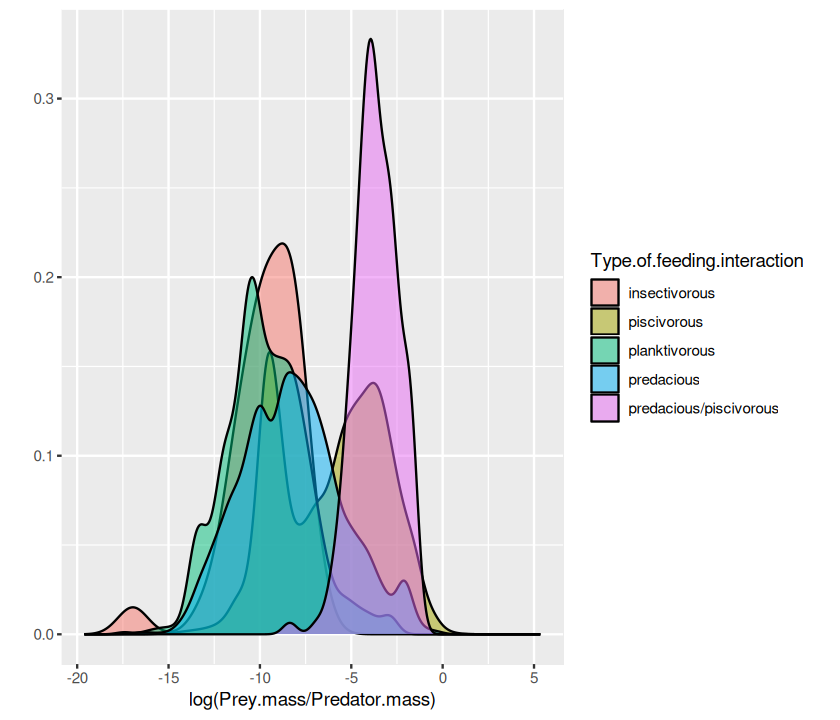

In [72]:
qplot(log(Prey.mass/Predator.mass), data = MyDF, geom =  "density", 
      fill = Type.of.feeding.interaction, 
      alpha = I(0.5))

or using `colour` instead of `fill` draws only the edge of the curve:

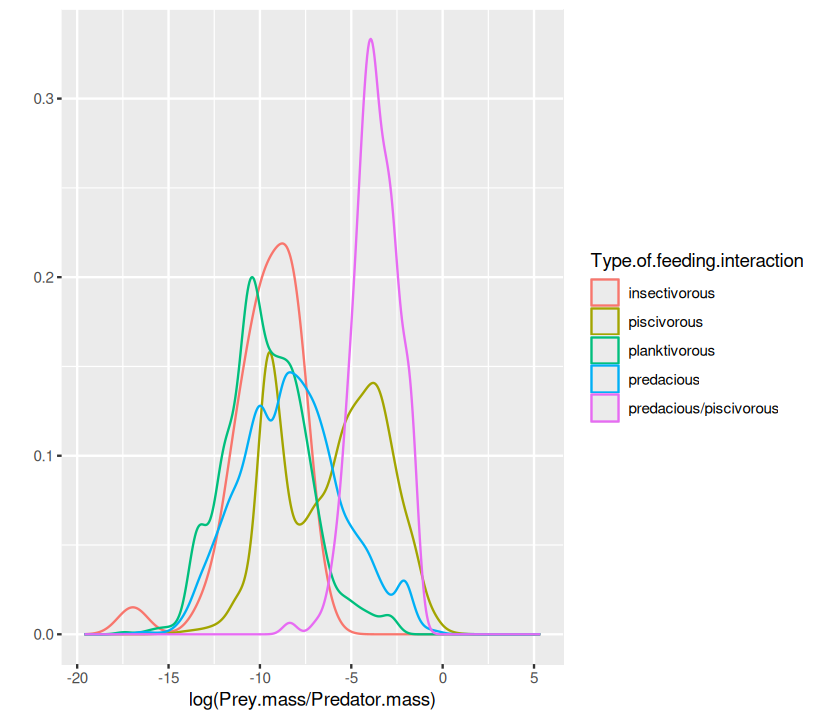

In [73]:
qplot(log(Prey.mass/Predator.mass), data = MyDF, geom =  "density", 
      colour = Type.of.feeding.interaction)

Similarly, `geom = "bar"` produces a barplot, `geom = "line"` a series of points joined by a line, etc.

#### Multi-faceted plots

An alternative way of displaying data belonging to different classes is using "faceting":

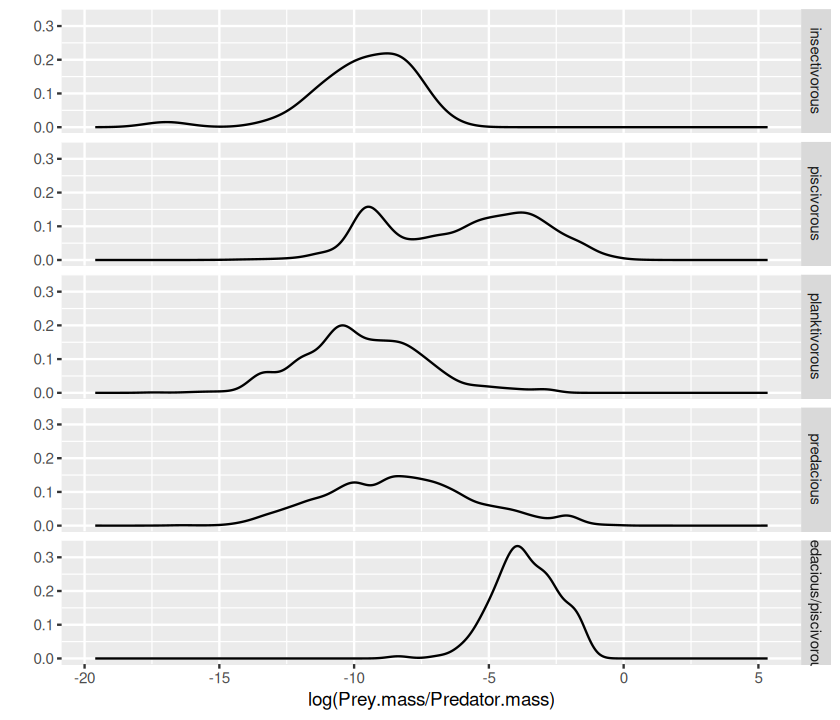

In [74]:
qplot(log(Prey.mass/Predator.mass), facets = Type.of.feeding.interaction ~., data = MyDF, geom =  "density")

The `~.` (the space is not important) notation tells ggplot whether to do the faceting by row or by column. So if you want a by-column configuration, switch `~` and `.`, and also swap the position of the `.~`:

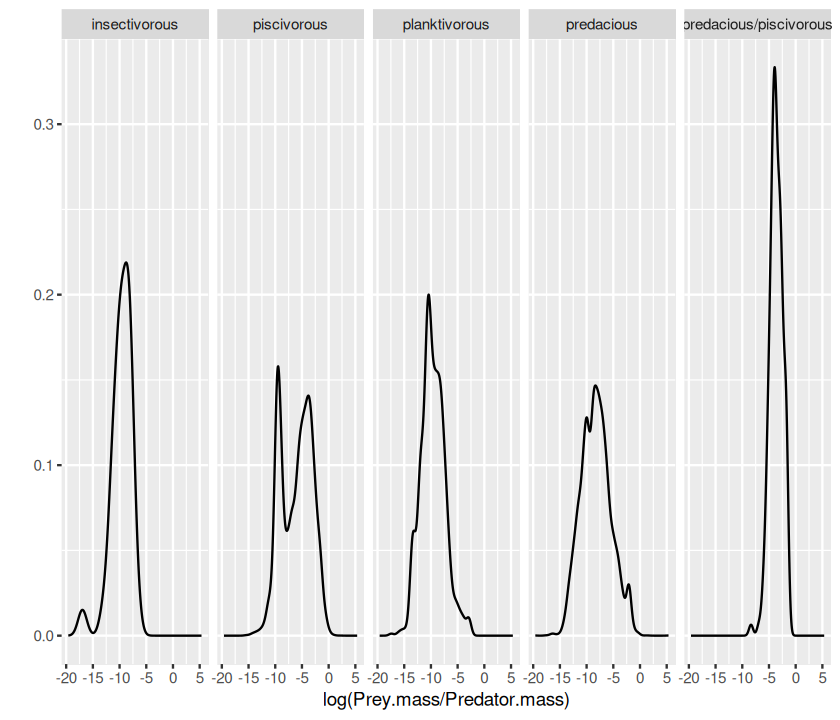

In [75]:
qplot(log(Prey.mass/Predator.mass), facets =  .~ Type.of.feeding.interaction, data = MyDF, geom =  "density")

#### Logarithmic axes

A better way to plot data in the log scale is to also set the axes to be logarithmic:

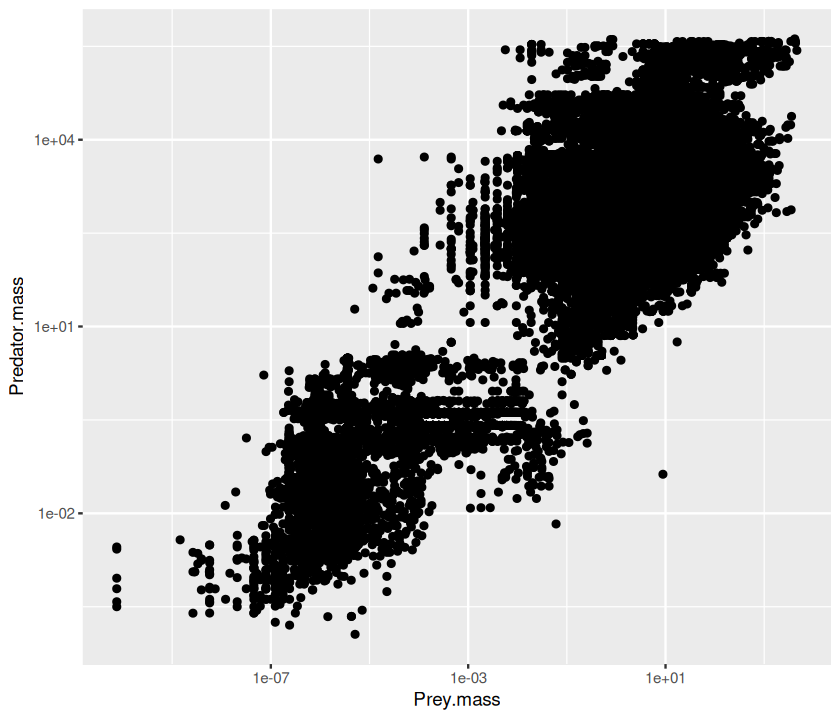

In [76]:
qplot(Prey.mass, Predator.mass, data = MyDF, log="xy")

#### Plot annotations

Let's add a title and labels:

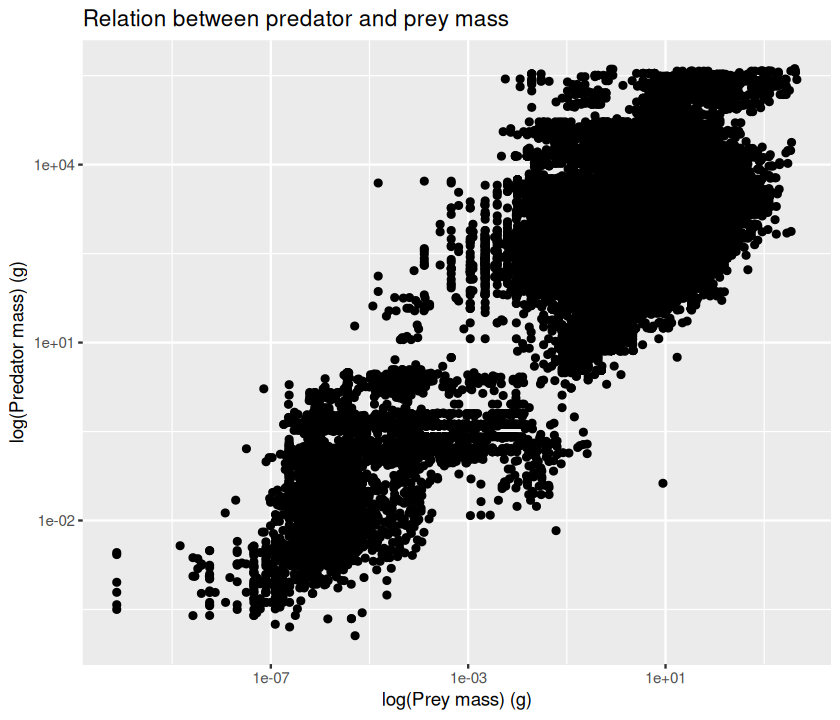

In [77]:
qplot(Prey.mass, Predator.mass, data = MyDF, log="xy",
    main = "Relation between predator and prey mass", 
    xlab = "log(Prey mass) (g)", 
    ylab = "log(Predator mass) (g)")

Adding `+ theme_bw()` makes it suitable for black and white printing.

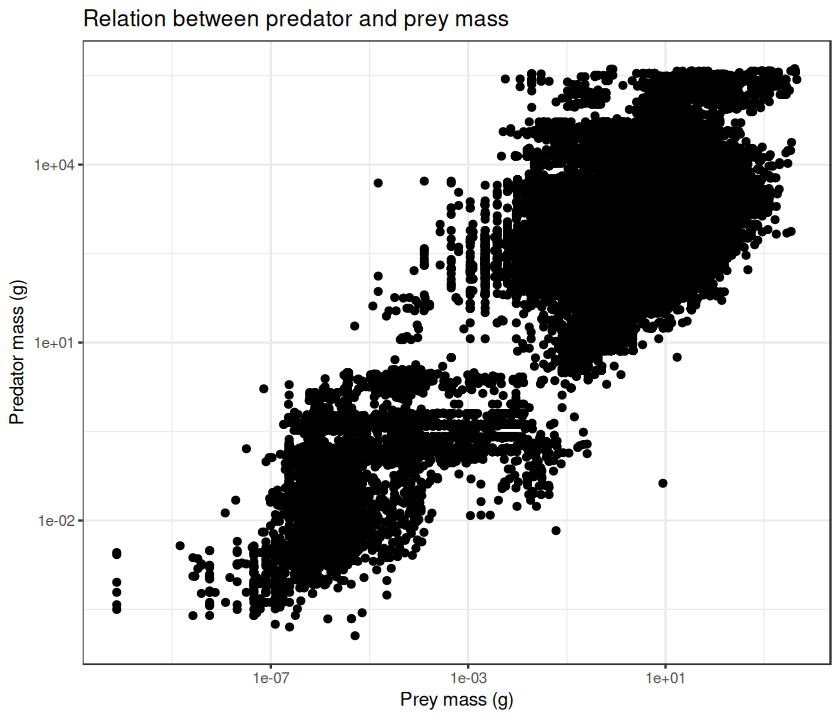

In [78]:
qplot(Prey.mass, Predator.mass, data = MyDF, log="xy",
    main = "Relation between predator and prey mass", 
    xlab = "Prey mass (g)", 
    ylab = "Predator mass (g)") + theme_bw()

#### Saving your plots

Finally, let's save a pdf file of the figure (same approach as we [used before](#Saving-your-graphics)):

In [79]:
pdf("results/MyFirst-ggplot2-Figure.pdf")
print(qplot(Prey.mass, Predator.mass, data = MyDF,log="xy",
    main = "Relation between predator and prey mass", 
    xlab = "log(Prey mass) (g)", 
    ylab = "log(Predator mass) (g)") + theme_bw())
dev.off()

agg_record_4d7835387b627 
                       2

Using `print` ensures that the whole command is kept together and that you can use the command in a script.

### Some more important ggplot options

Other important options to keep in mind:

|   Option            |                |
|--- |--- |
|`xlim`      | limits for x axis: `xlim = c(0,12)`|
|`ylim`      | limits for y axis|
|`log`       |log transform variable `log = "x"`, `log = "y"`, `log = "xy"`|
|`main`      |title of the plot `main = "My Graph"`|
|`xlab`      |x-axis label|
|`ylab`      |y-axis label|
|`asp`       | aspect ratio `asp = 2`, `asp = 0.5`|
|`margins`   |whether or not margins will be displayed|


### The `geom` argument

`geom` Specifies the geometric objects that define the graph type. The geom option is expressed as a R character vector with one or more entries. geom values include "point", "smooth", "boxplot", "line", "histogram", "density", "bar", and "jitter".

Try the following:

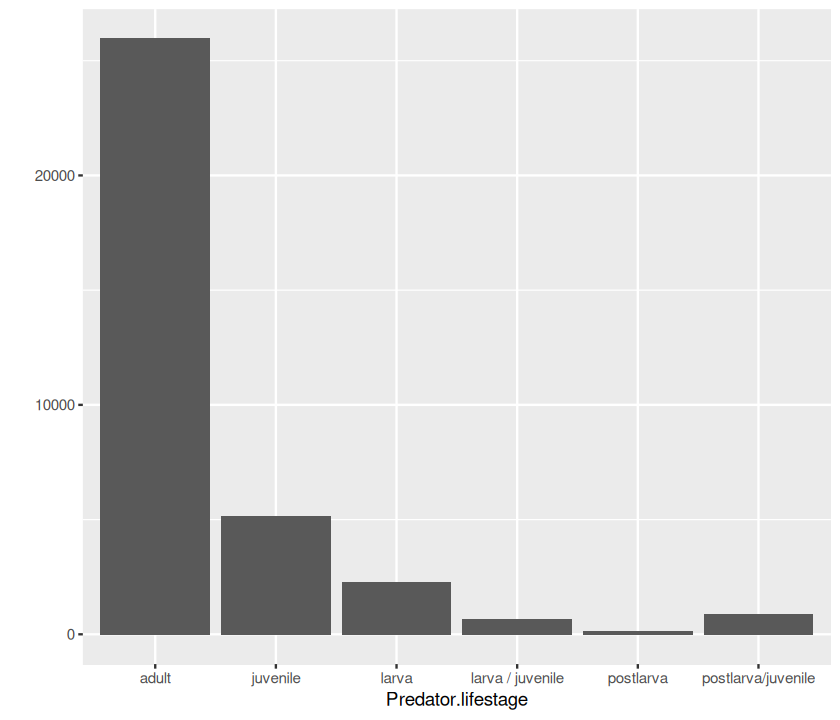

In [80]:
# load the data
MyDF <- as.data.frame(read.csv("data/ecol_archives_e_089_51_d_1.csv"))

# barplot
qplot(Predator.lifestage, data = MyDF, geom = "bar")

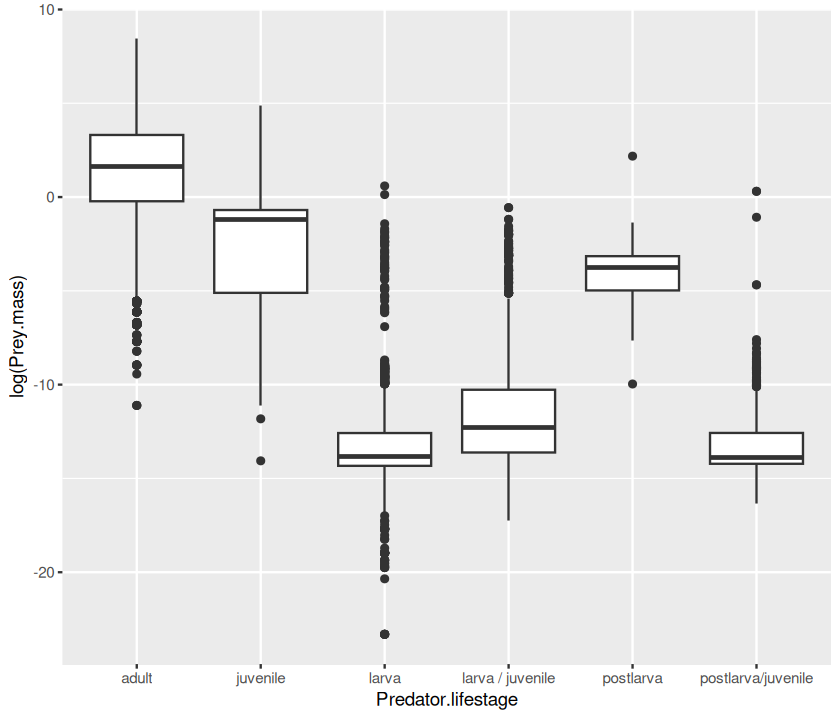

In [81]:
# boxplot
qplot(Predator.lifestage, log(Prey.mass), data = MyDF, geom = "boxplot")

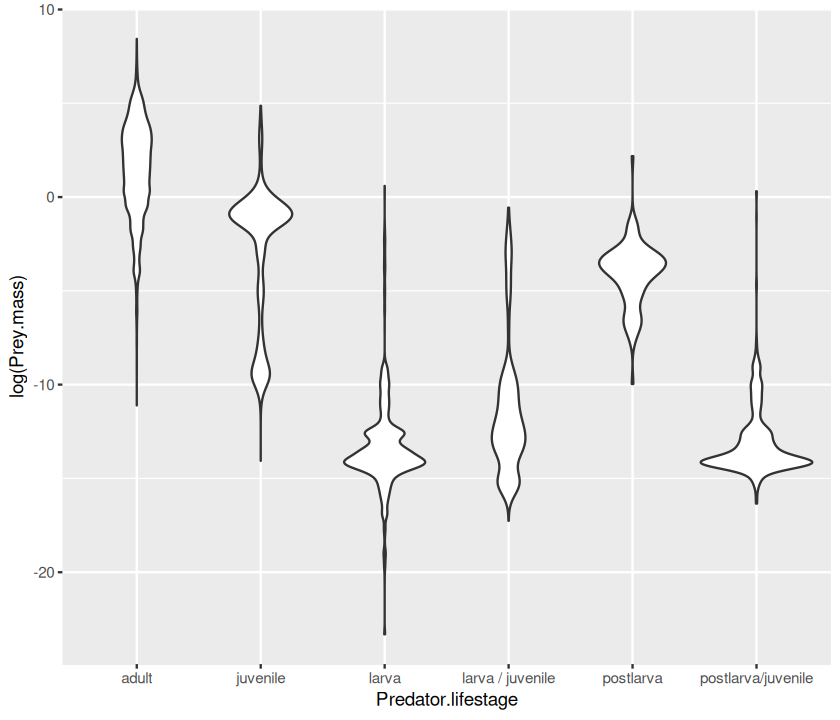

In [82]:
# violin plot
qplot(Predator.lifestage, log(Prey.mass), data = MyDF, geom = "violin")

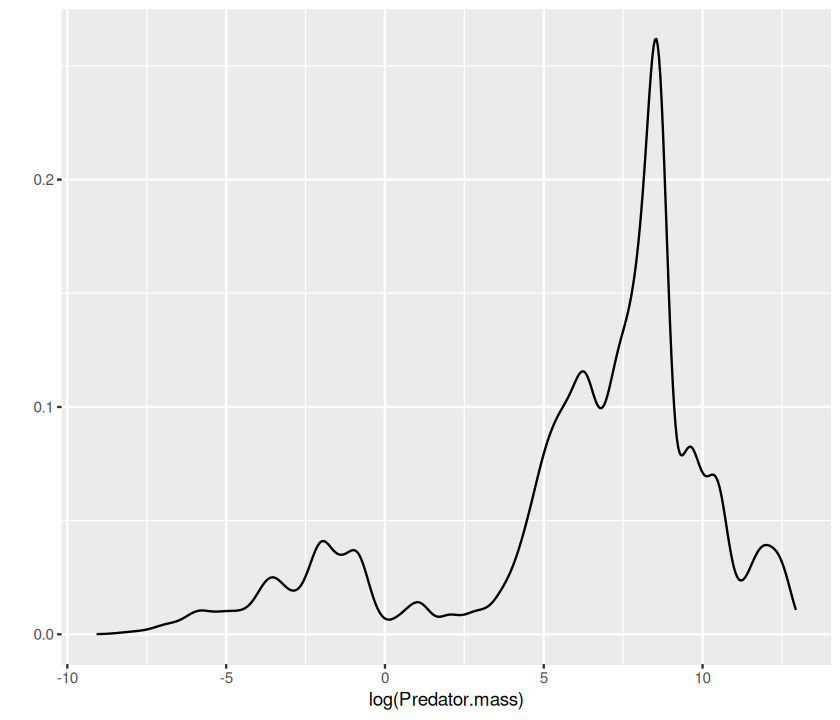

In [83]:
# density
qplot(log(Predator.mass), data = MyDF, geom = "density")

`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


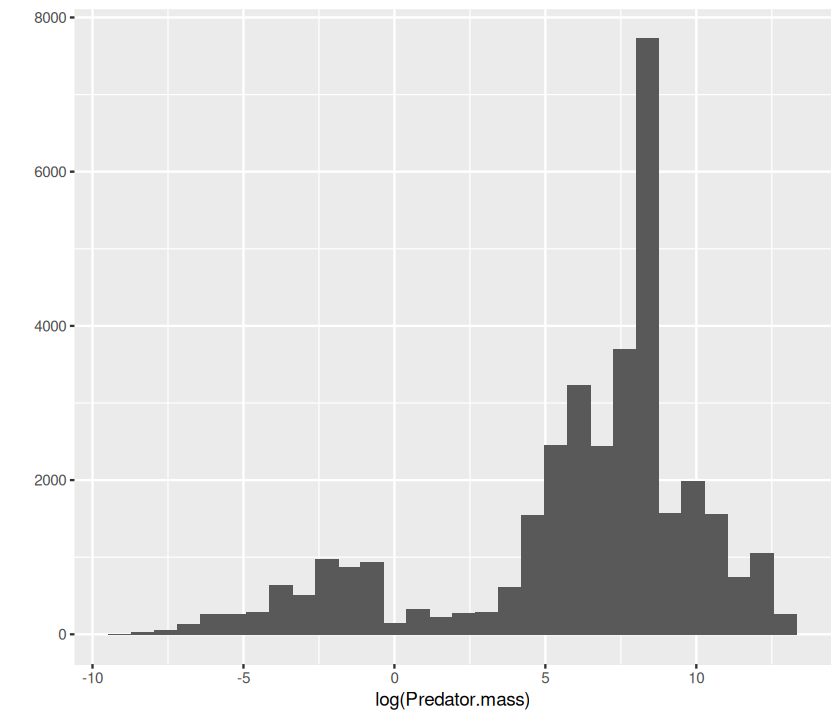

In [84]:
# histogram
qplot(log(Predator.mass), data = MyDF, geom = "histogram")

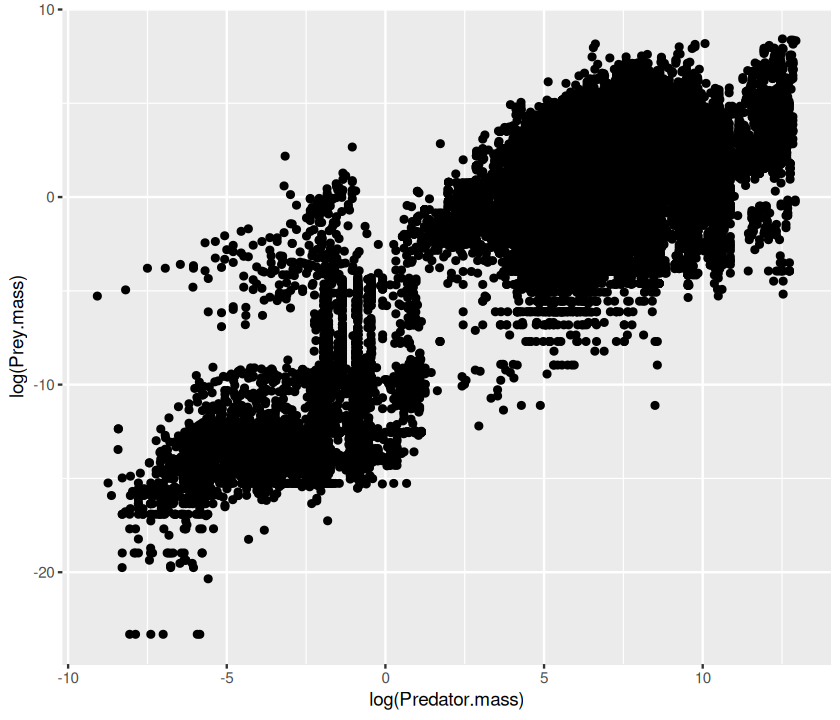

In [85]:
# scatterplot
qplot(log(Predator.mass), log(Prey.mass), data = MyDF, geom = "point")

`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'


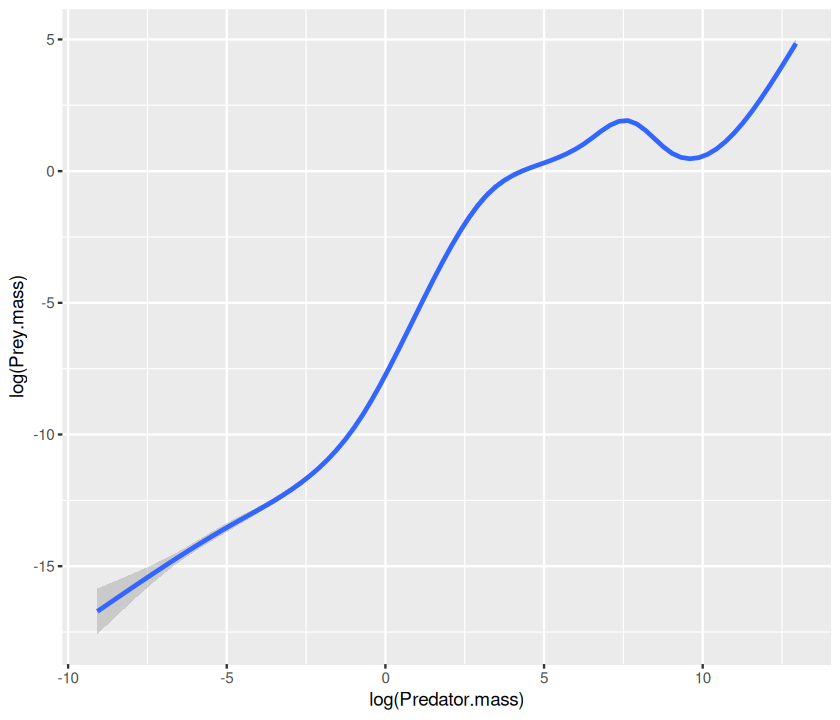

In [86]:
# smooth
qplot(log(Predator.mass), log(Prey.mass), data = MyDF, geom = "smooth")

`geom_smooth()` using formula = 'y ~ x'


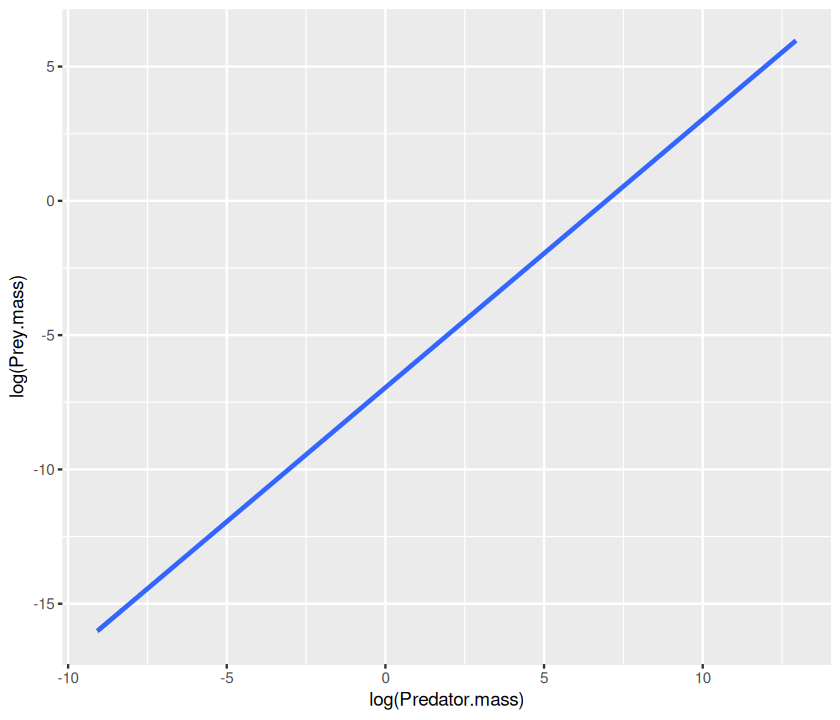

In [87]:
qplot(log(Predator.mass), log(Prey.mass), data = MyDF, geom = "smooth", method = "lm")

### Advanced plotting: `ggplot`

The command `qplot` allows you to use only a single dataset and a single set of "aesthetics" (x, y, etc.). To make full use of `ggplot2`, we need to use the command `ggplot`, which allows you to use "layering". Layering is the mechanism by which additional data elements are added to a plot. Each layer can come from a different dataset and have a different aesthetic mapping, allowing us to create plots that could not be generated using `qplot()`, which permits only a single dataset and a single set of aesthetic mappings.

For a `ggplot` plotting command, we need at least:

-   The data to be plotted, in a data frame;

-   Aesthetics mappings, specifying which variables we want to plot, and how;

-   The `geom`, defining the geometry for representing the data;

-   (Optionally) some `stat` that transforms the data or performs statistics using the data.

To start a graph, we must specify the data and the aesthetics:

In [88]:
p <- ggplot(MyDF, aes(x = log(Predator.mass),
                y = log(Prey.mass),
                colour = Type.of.feeding.interaction))

Here we have created a graphics object `p` to which we can add layers and other plot elements.

Now try to plot the graph:

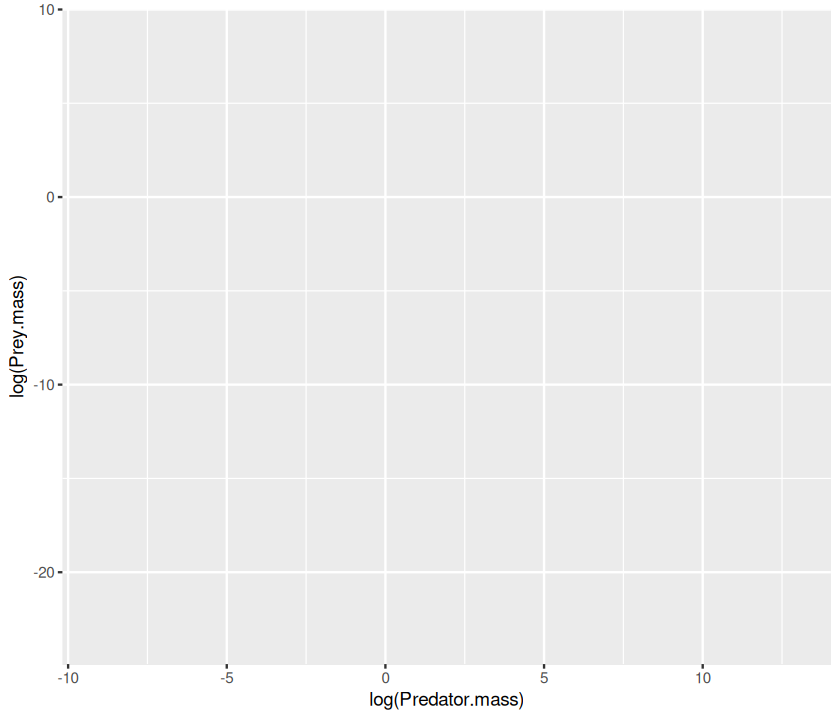

In [89]:
p

Plot is blank because we are yet to specify a geometry — only then can we see the graph:

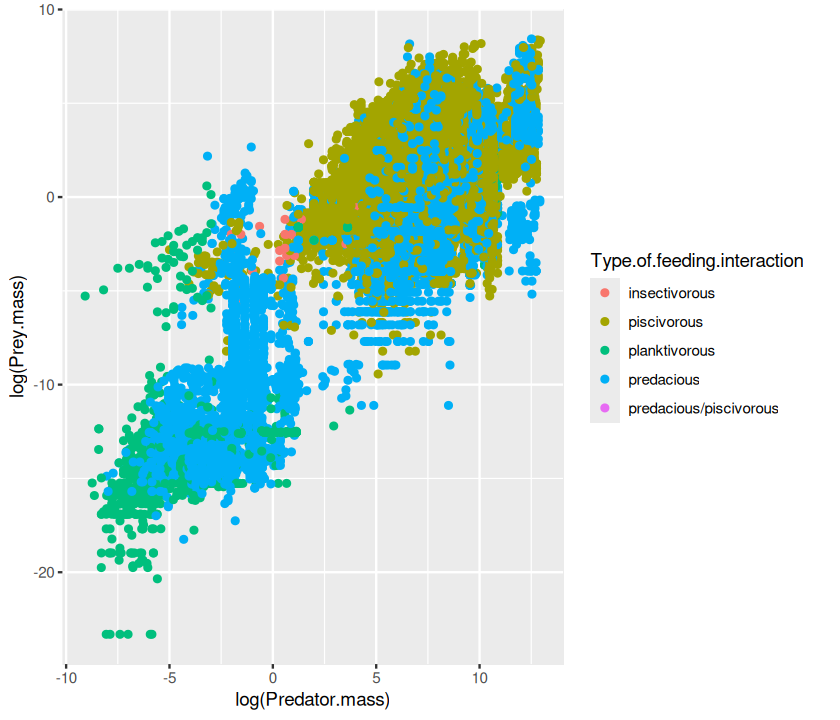

In [90]:
p + geom_point()

We can use the "+" sign to concatenate different commands:

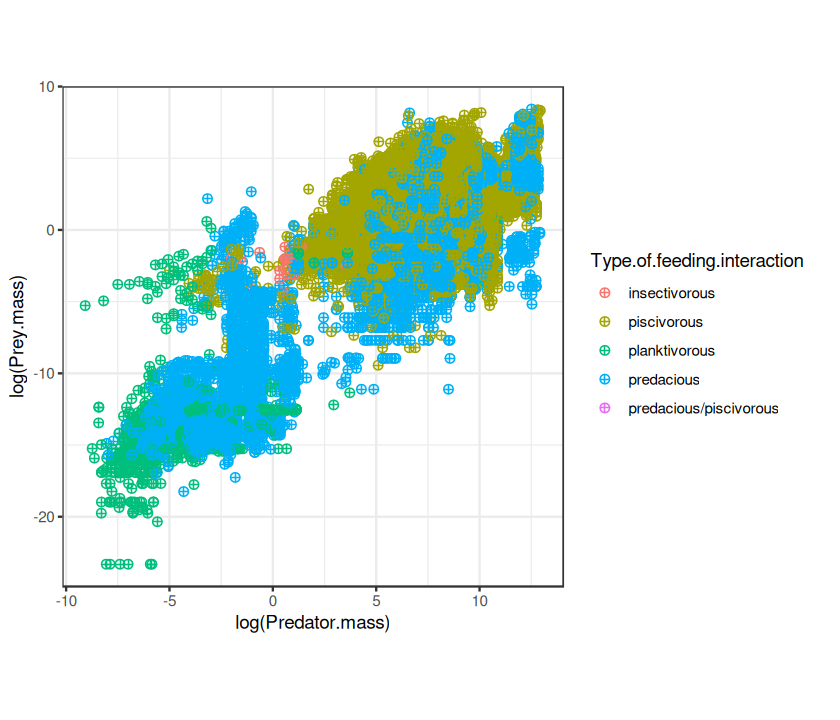

In [91]:
p <- ggplot(MyDF, aes(x = log(Predator.mass), y = log(Prey.mass), colour = Type.of.feeding.interaction ))
q <- p + 
geom_point(size=I(2), shape=I(10)) +
theme_bw() + # make the background white
theme(aspect.ratio=1) # make the plot square
q

Let's remove the legend:

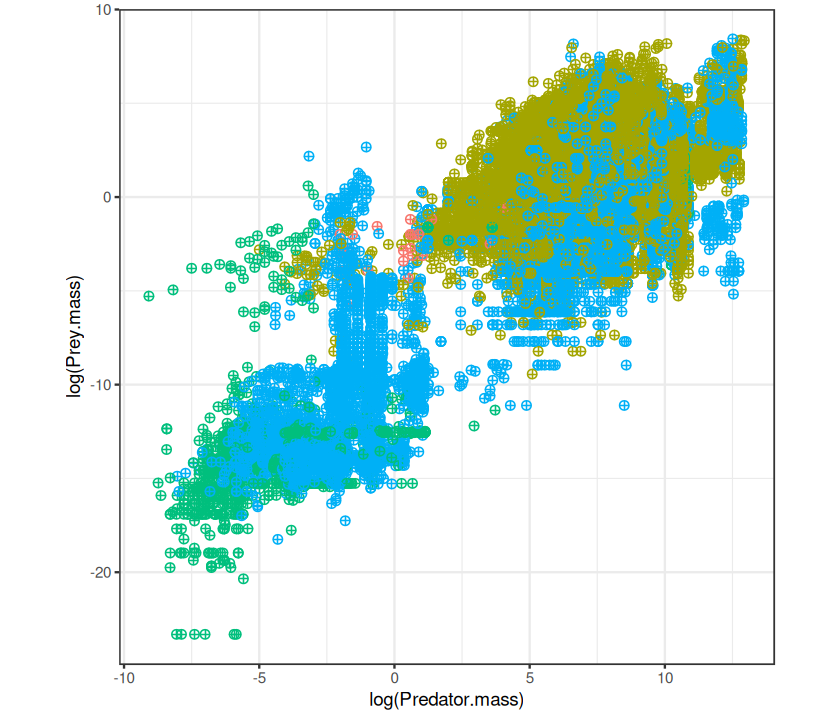

In [92]:
q + theme(legend.position = "none") + theme(aspect.ratio=1)

Now, same as before, but using ggplot instead of qplot:

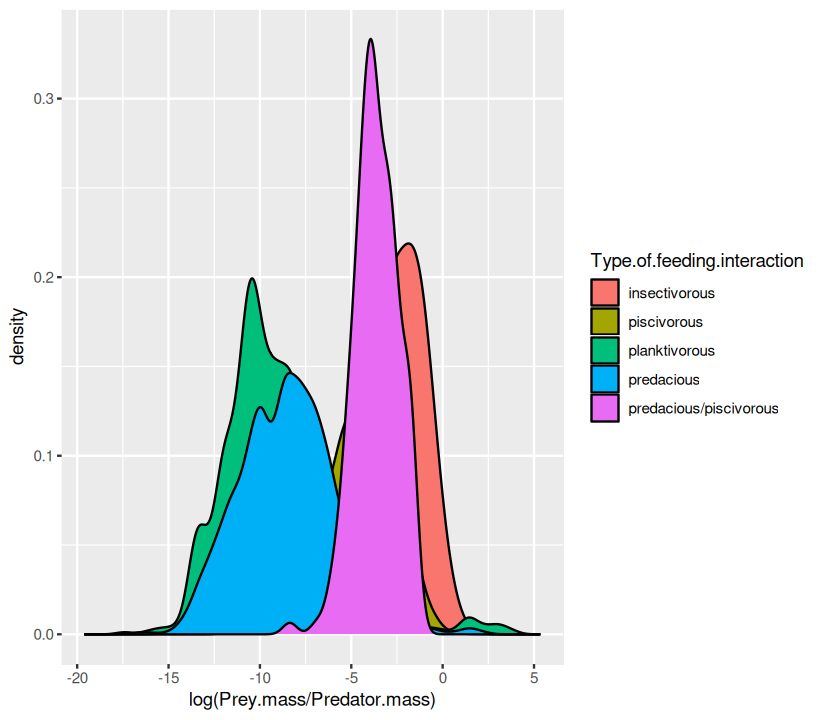

In [93]:
p <- ggplot(MyDF, aes(x = log(Prey.mass/Predator.mass), fill = Type.of.feeding.interaction )) + geom_density()
p

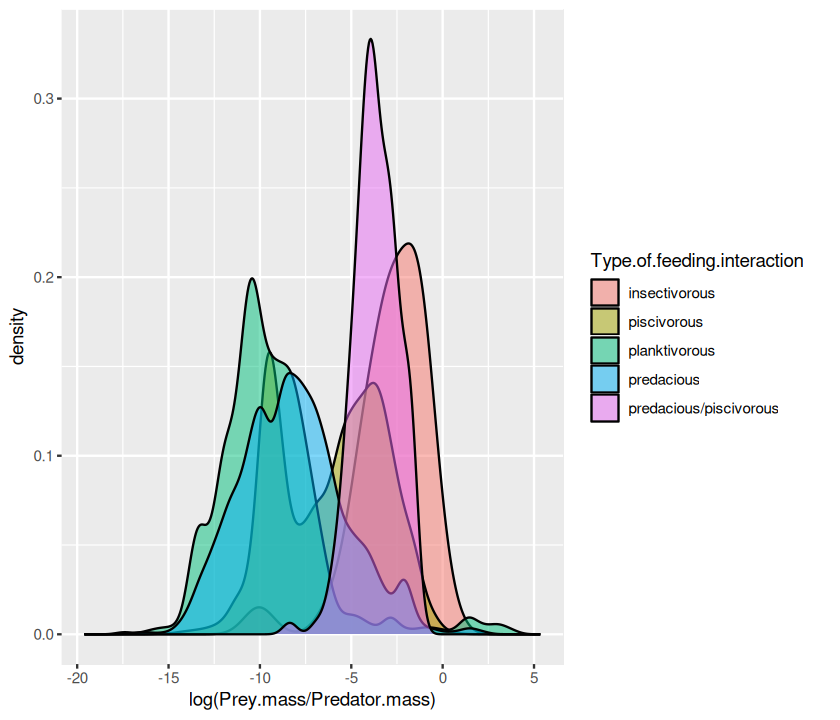

In [94]:
p <- ggplot(MyDF, aes(x = log(Prey.mass/Predator.mass), fill = Type.of.feeding.interaction)) + geom_density(alpha=0.5)
p

In [95]:
options(repr.plot.width=12, repr.plot.height= 8) # Change plot size (in cm)

You can also create a multifaceted plot:

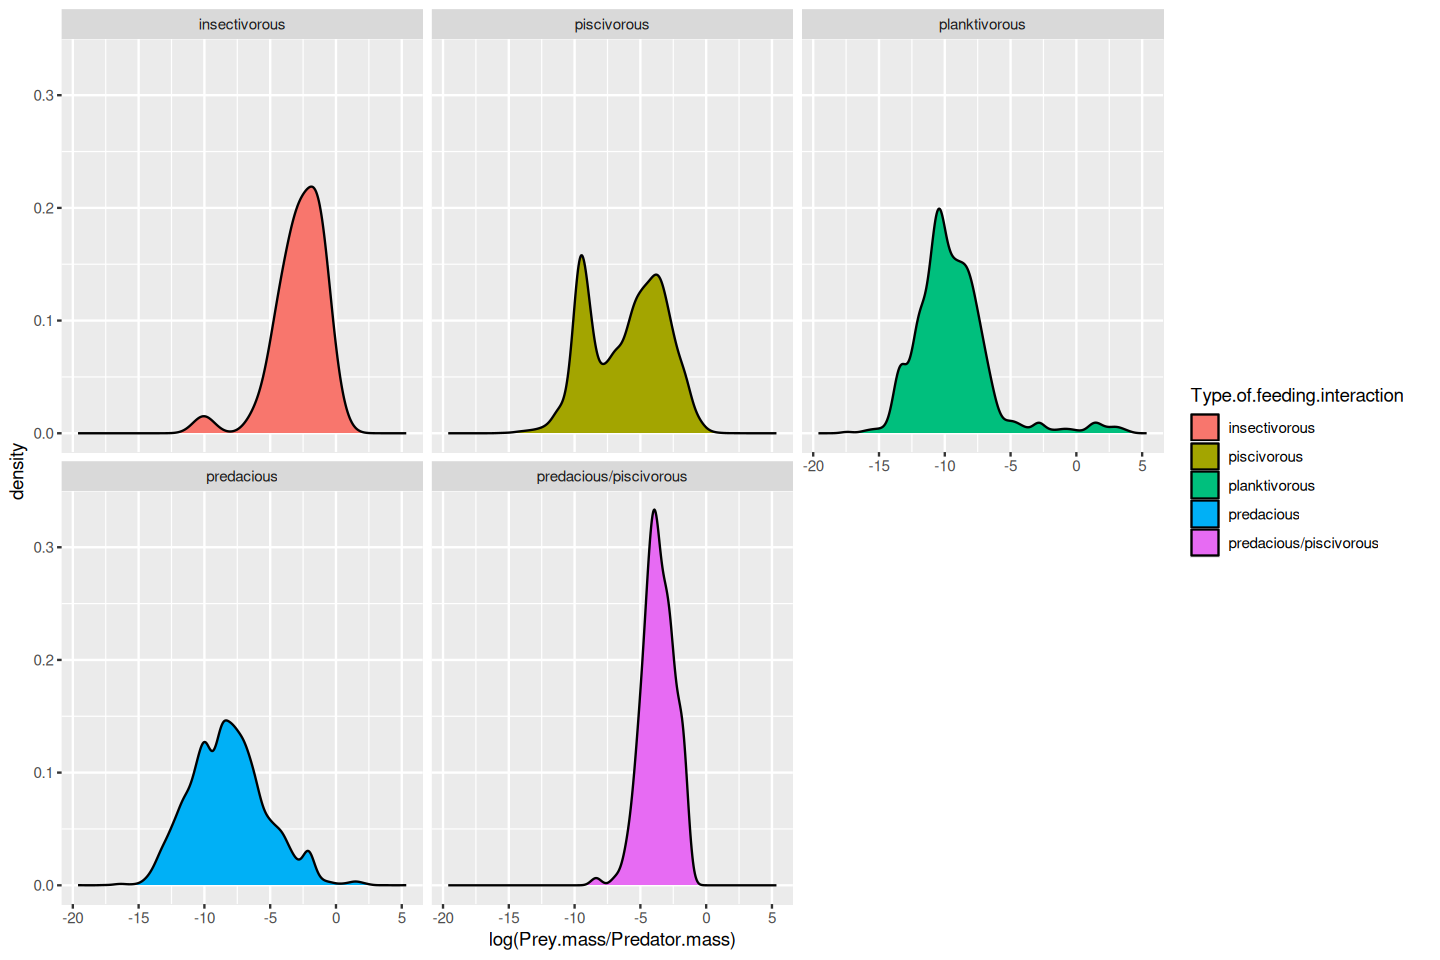

In [96]:
p <- ggplot(MyDF, aes(x = log(Prey.mass/Predator.mass), fill = Type.of.feeding.interaction )) +  geom_density() + facet_wrap( .~ Type.of.feeding.interaction)
p

The axis limits in the plots are fixed irrespective of the data ranges, making it harder to visualize the shapes of the distributions. You can free up the axes to allow data-specific axis limits by using the `scales = "free"` argument:   

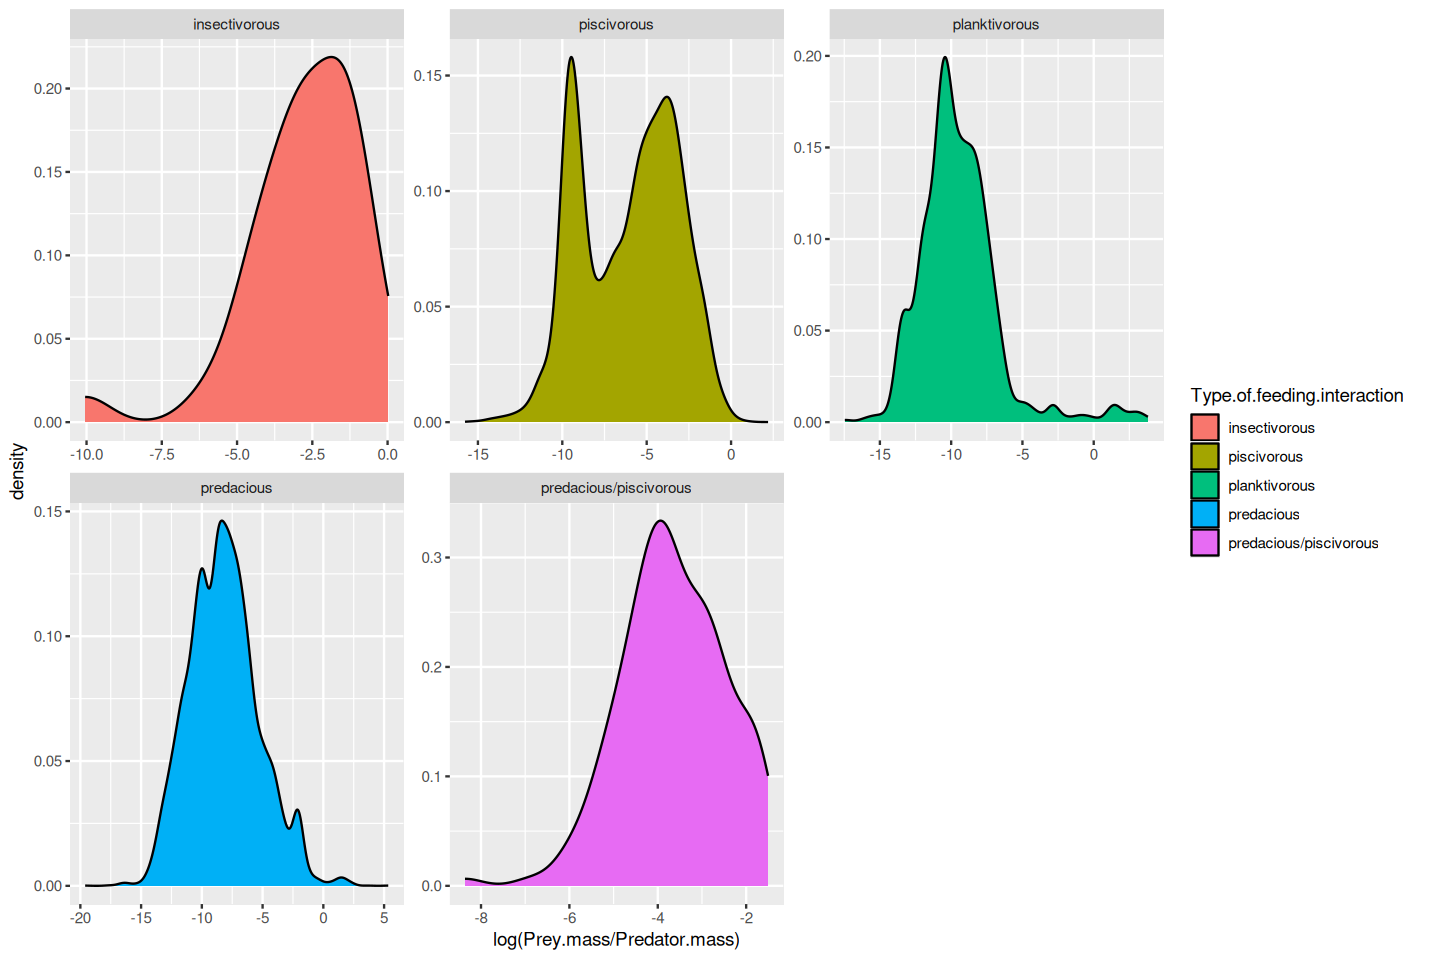

In [97]:
p <- ggplot(MyDF, aes(x = log(Prey.mass/Predator.mass), fill = Type.of.feeding.interaction )) +  geom_density() + facet_wrap( .~ Type.of.feeding.interaction, scales = "free")
p

```{tip}
In `facet_wrap`, You can also free up just the x or y scales; look up the documentation for this function.
```

In [98]:
options(repr.plot.width=10, repr.plot.height= 12) # Change plot size (in cm)

Now let's plot the size-ratio distributions by location (and again, with scales free):  

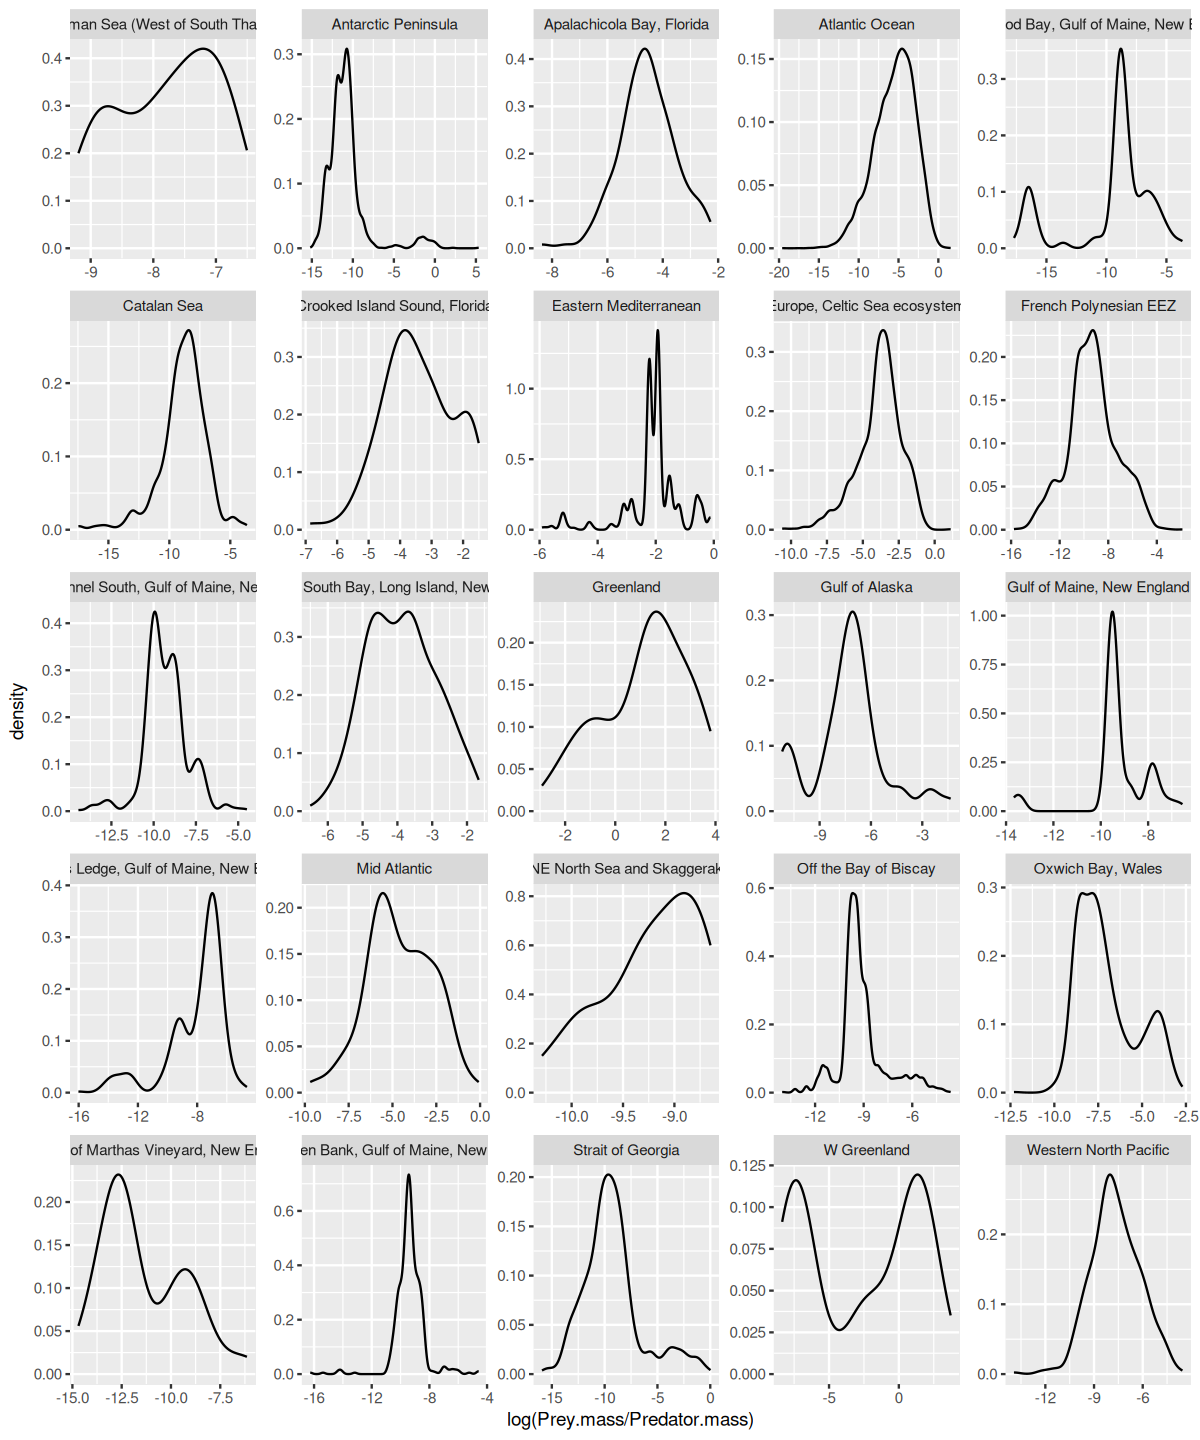

In [99]:
p <- ggplot(MyDF, aes(x = log(Prey.mass/Predator.mass))) +  geom_density() + facet_wrap( .~ Location, scales = "free")
p

A different example:

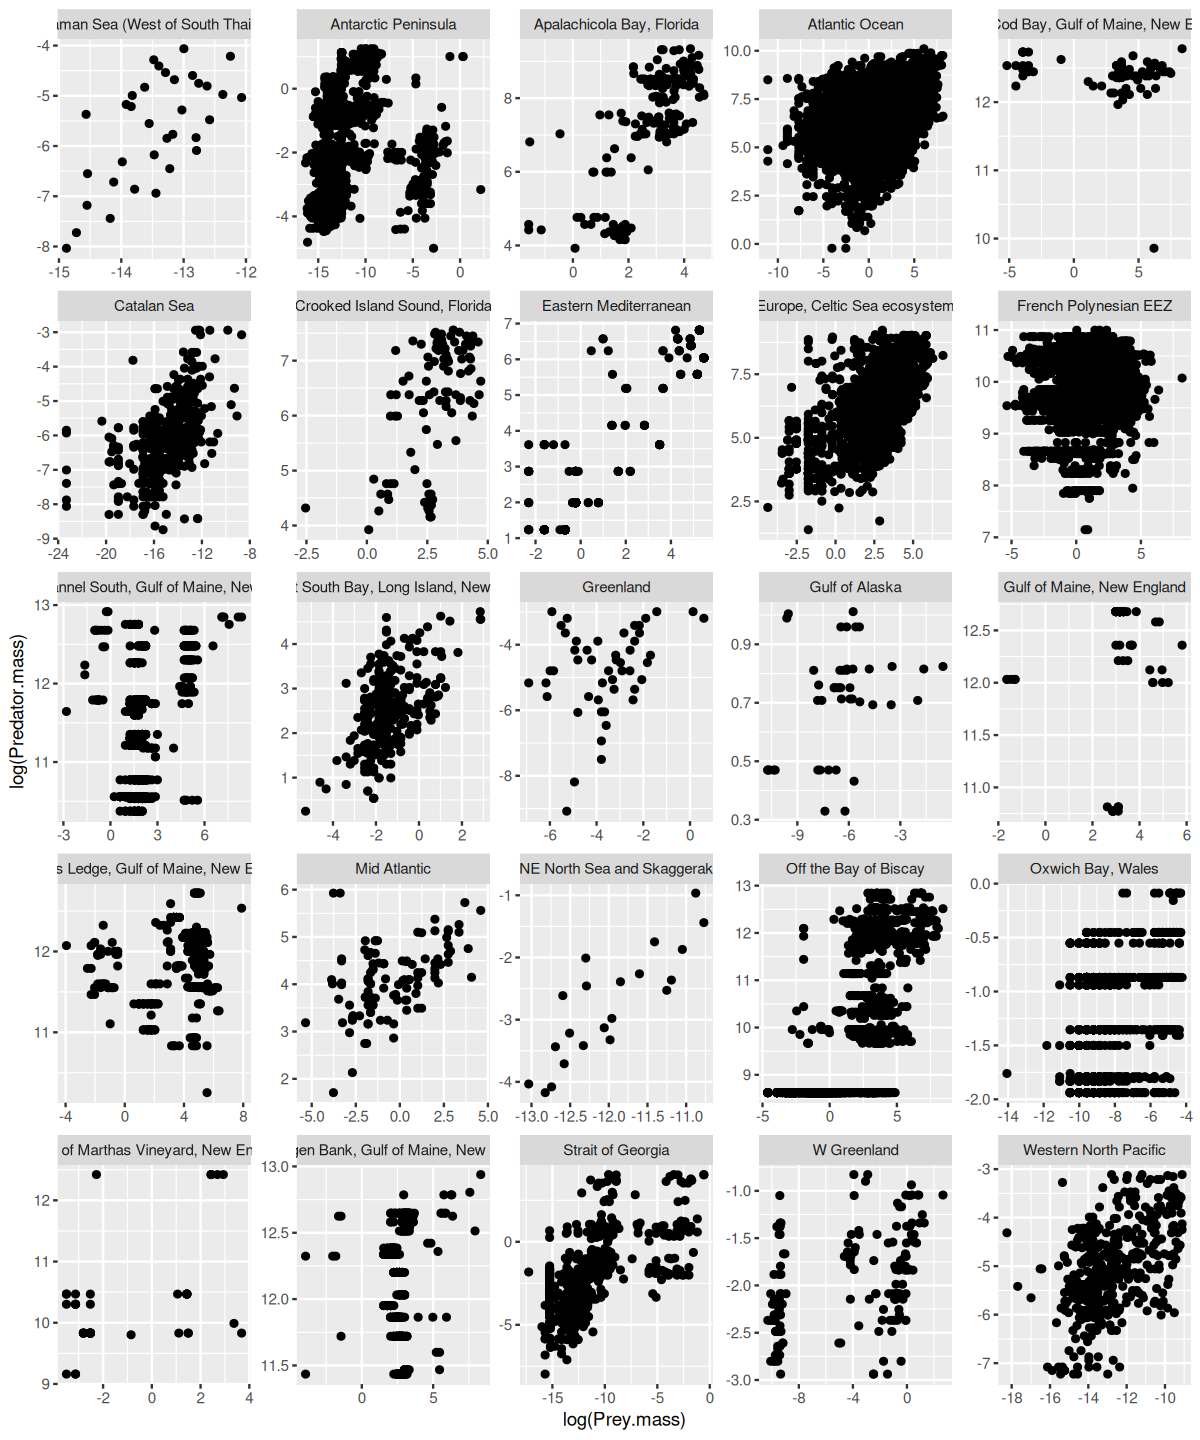

In [100]:
p <- ggplot(MyDF, aes(x = log(Prey.mass), y = log(Predator.mass))) +  geom_point() + facet_wrap( .~ Location, scales = "free")
p

You can also combine categories like this (this will be BIG plot!):

In [101]:
options(repr.plot.width=12, repr.plot.height= 14) # Change plot size (in cm)

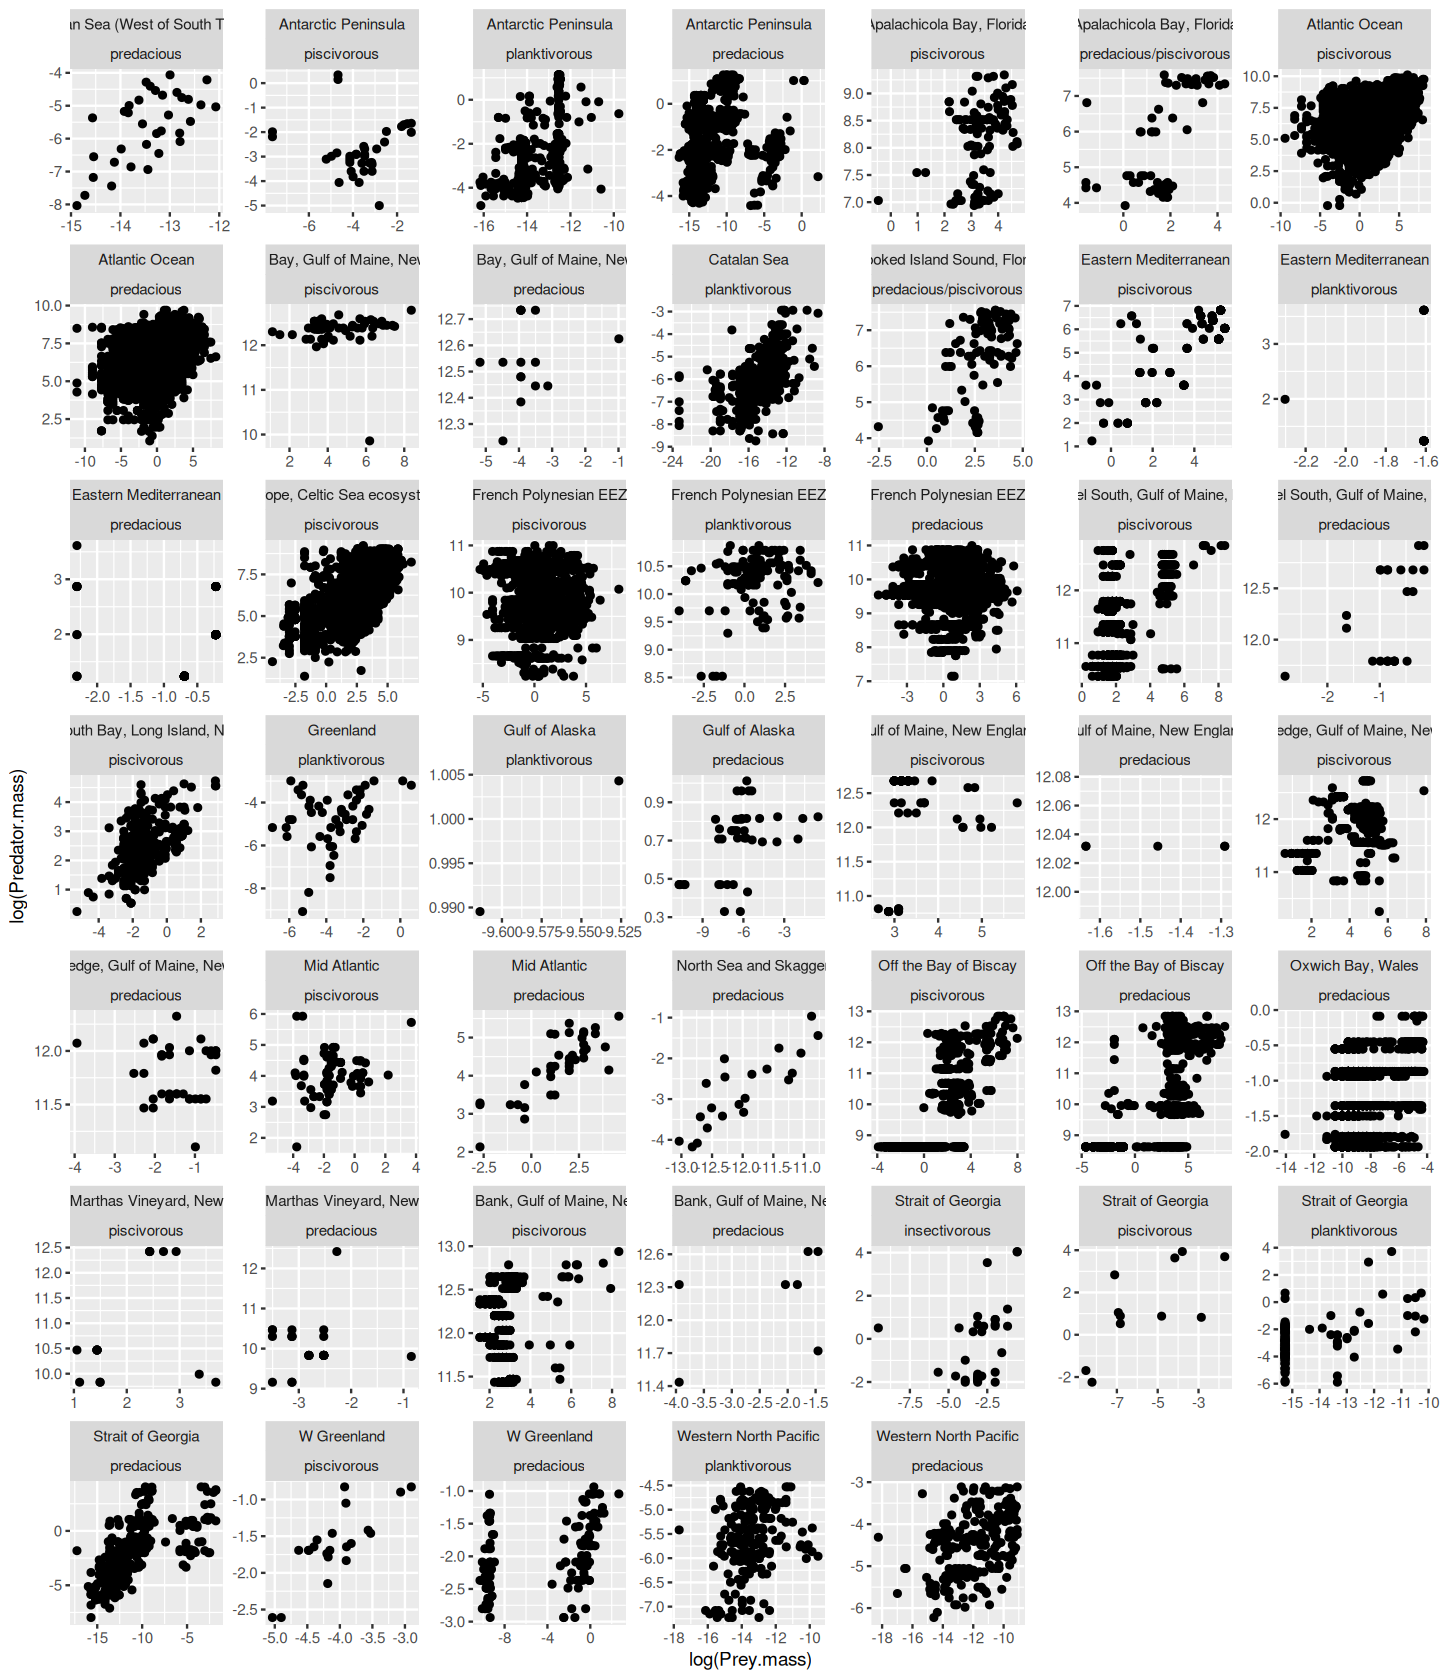

In [102]:
p <- ggplot(MyDF, aes(x = log(Prey.mass), y = log(Predator.mass))) +  geom_point() + facet_wrap( .~ Location + Type.of.feeding.interaction, scales = "free")
p

And you can also change the order of the combination:

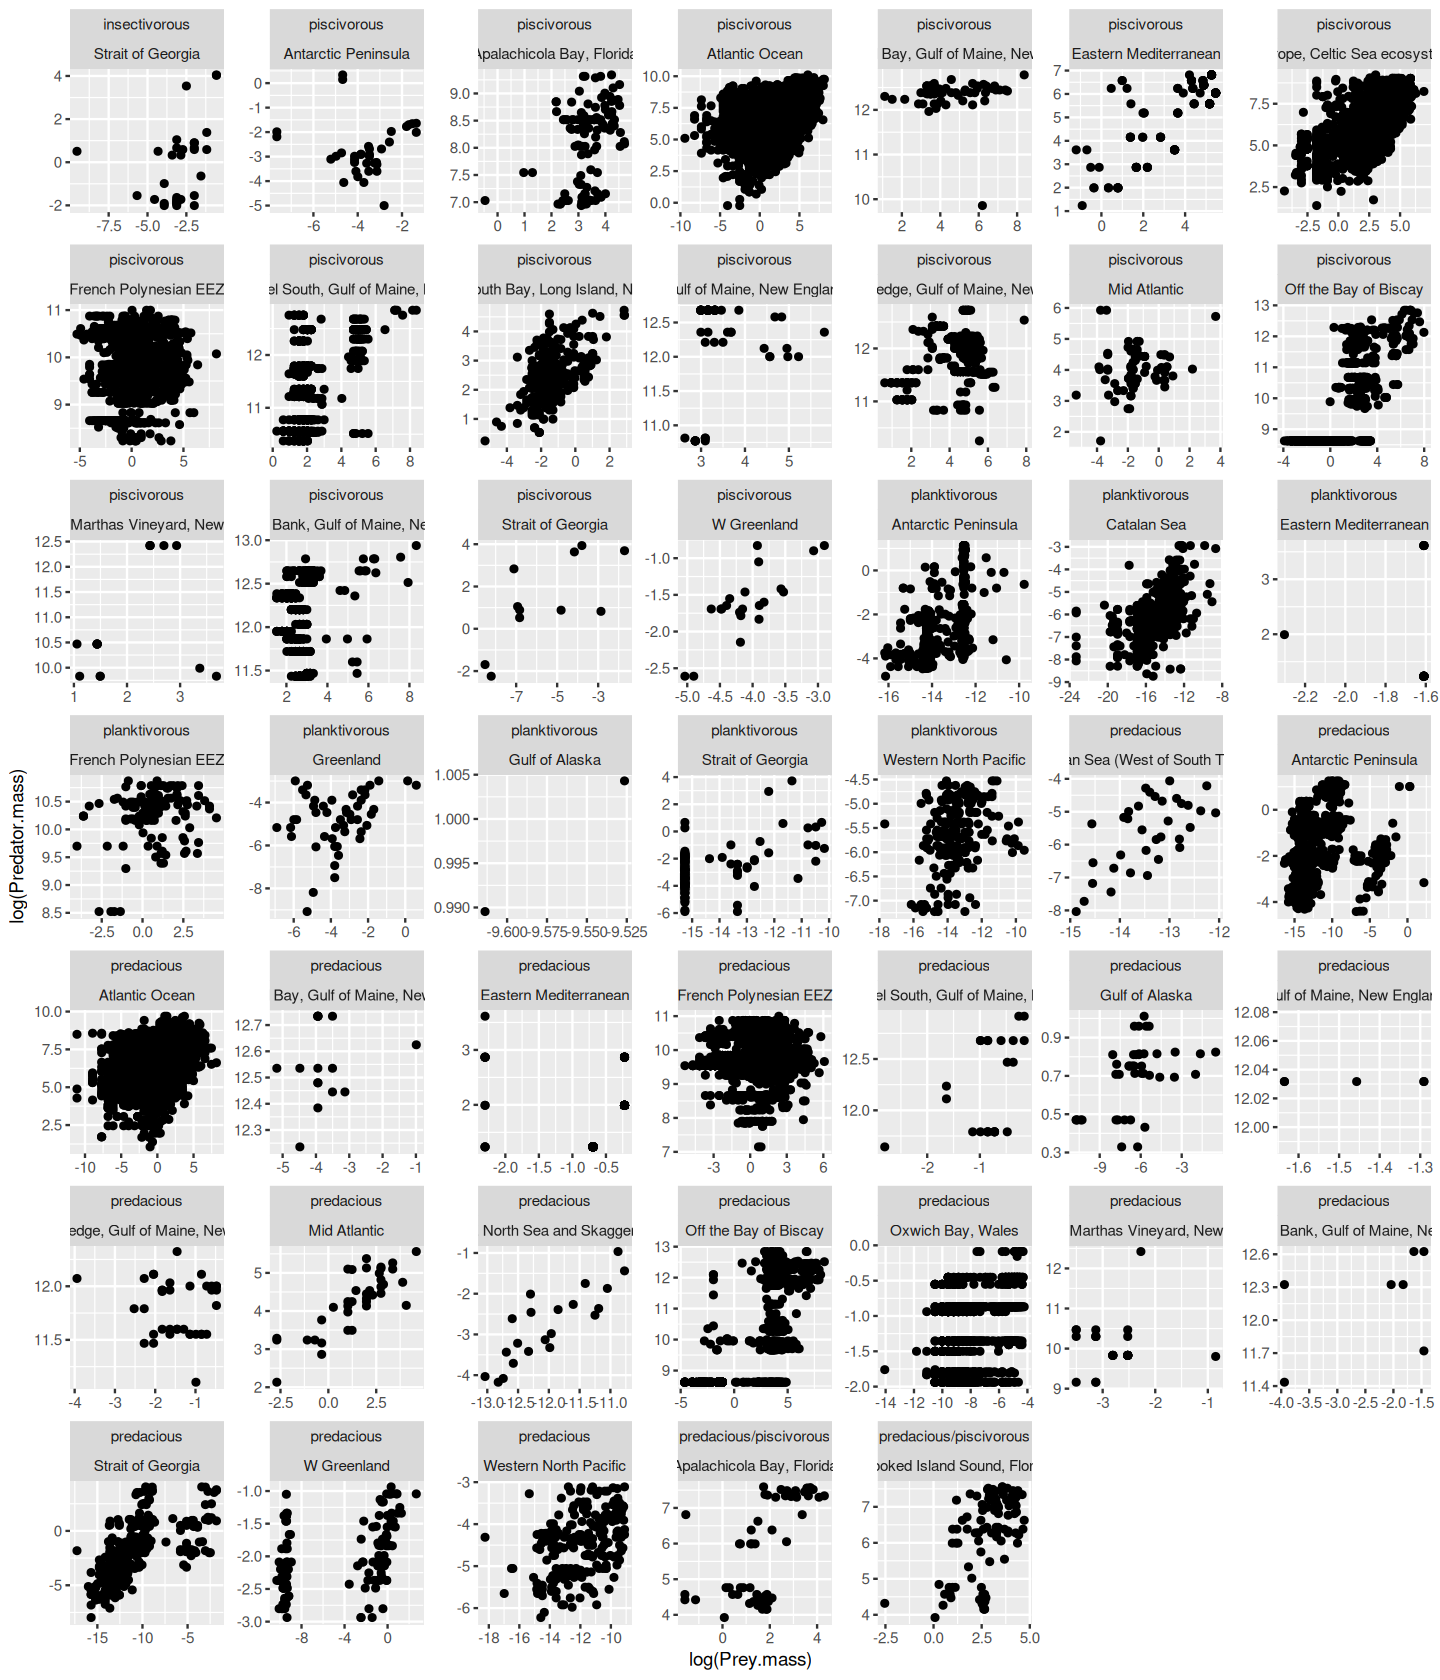

In [103]:
p <- ggplot(MyDF, aes(x = log(Prey.mass), y = log(Predator.mass))) +  geom_point() + facet_wrap( .~ Type.of.feeding.interaction + Location, scales = "free")
p

For more fine-tuned faceting, look up the `facet_grid()` and `facet_wrap()` functions within `ggplot2`. The [R Graphics Cookbook](http://www.cookbook-r.com/Graphs) has more examples.

In [104]:
options(repr.plot.width=7, repr.plot.height= 6) # Change plot size (in cm)

### Some useful ggplot examples 


### Plotting a matrix

Let's plot the values of a matrix. This is basically the same as rendering a 2D image. We will visualize random values taken from a unform distribution $\mathcal U [0,1]$. Because we want to plot a matrix, and ggplot2 accepts only dataframes, we use the package reshape2, which can "melt" a matrix into a dataframe:

In [105]:
require(reshape2)

In [106]:
GenerateMatrix <- function(N){
    M <- matrix(runif(N * N), N, N)
    return(M)
}

In [107]:
M <- GenerateMatrix(10)
Melt <- melt(M)

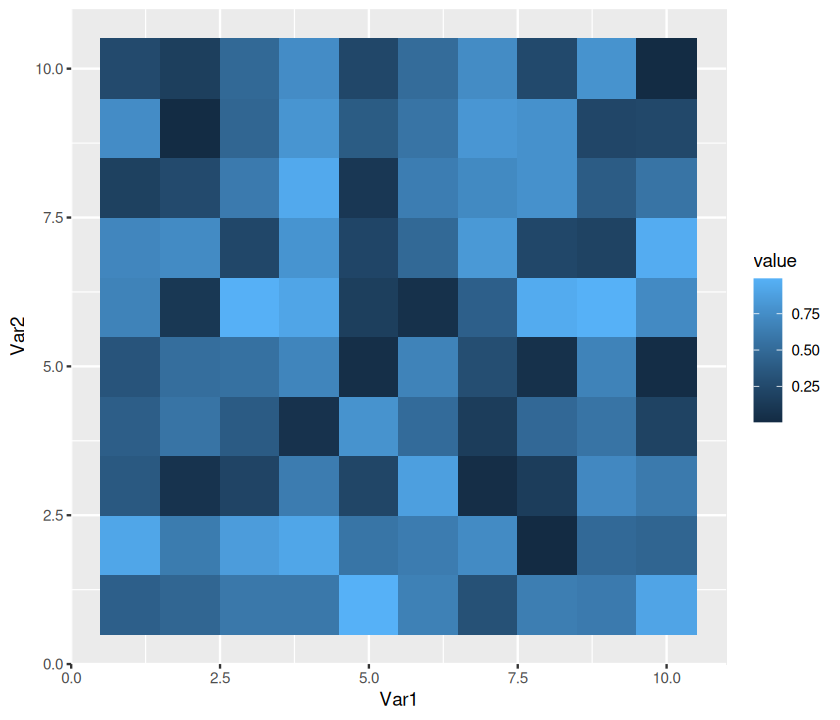

In [108]:
p <- ggplot(Melt, aes(Var1, Var2, fill = value)) + geom_tile() + theme(aspect.ratio = 1)
p

Add a black line dividing cells:

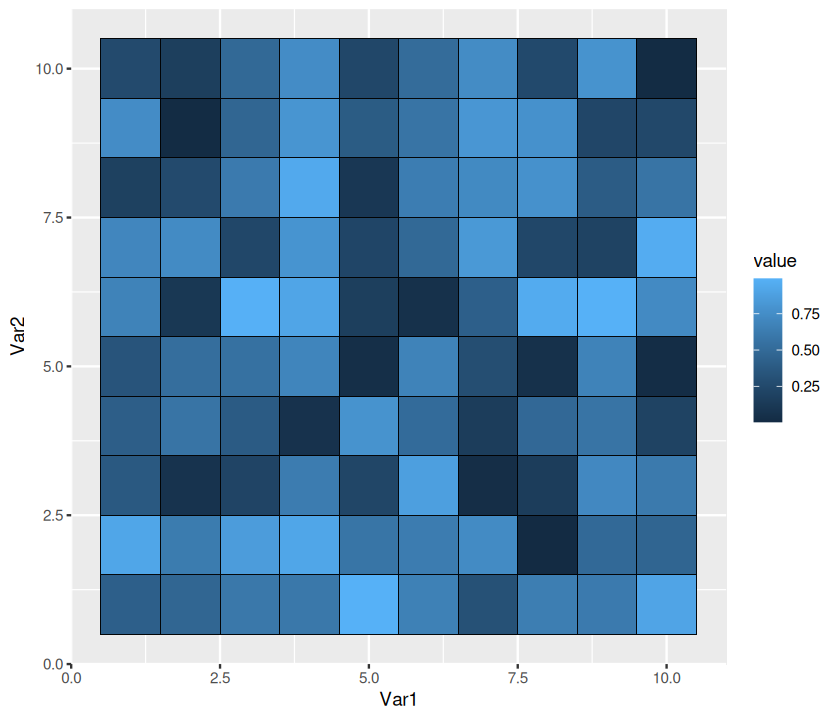

In [109]:
p + geom_tile(colour = "black") + theme(aspect.ratio = 1)

Remove the legend:

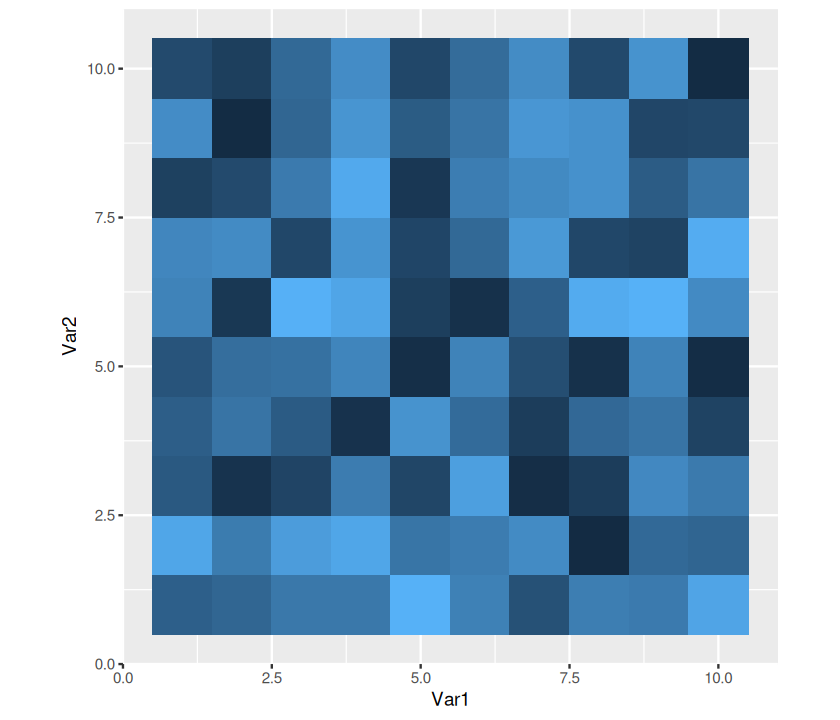

In [110]:
p + theme(legend.position = "none") + theme(aspect.ratio = 1)

Remove all the rest:

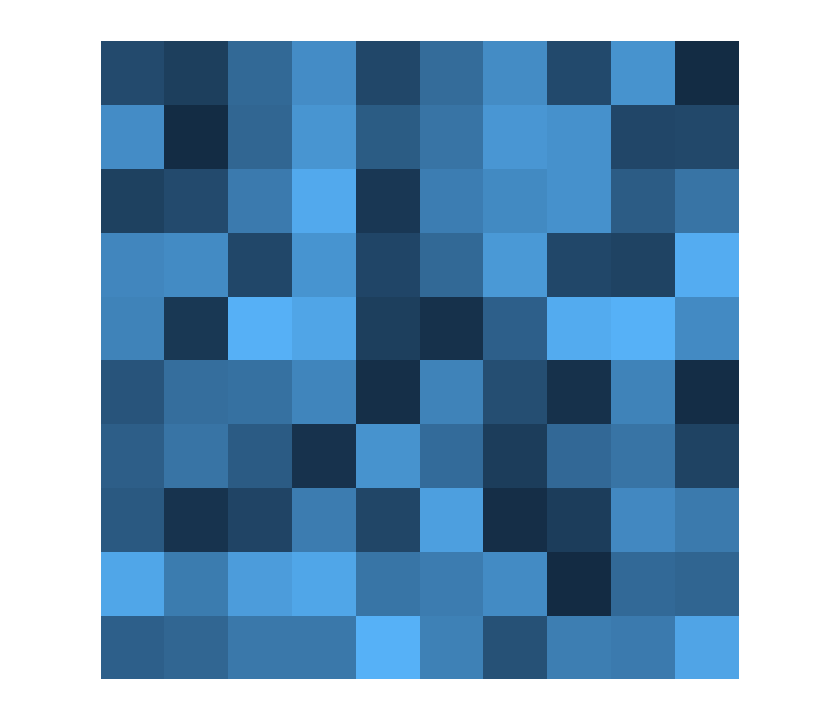

In [111]:
p + theme(legend.position = "none", 
     panel.background = element_blank(),
     axis.ticks = element_blank(), 
     panel.grid.major = element_blank(),
     panel.grid.minor = element_blank(),
     axis.text.x = element_blank(),
     axis.title.x = element_blank(),
     axis.text.y = element_blank(),
     axis.title.y = element_blank())

Explore some colors:

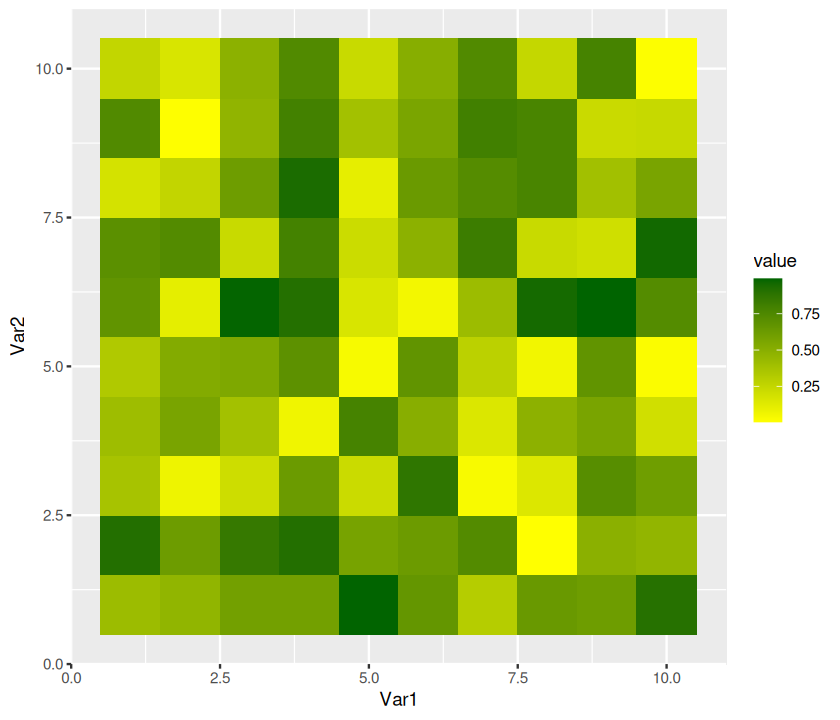

In [112]:
p + scale_fill_continuous(low = "yellow", high = "darkgreen")

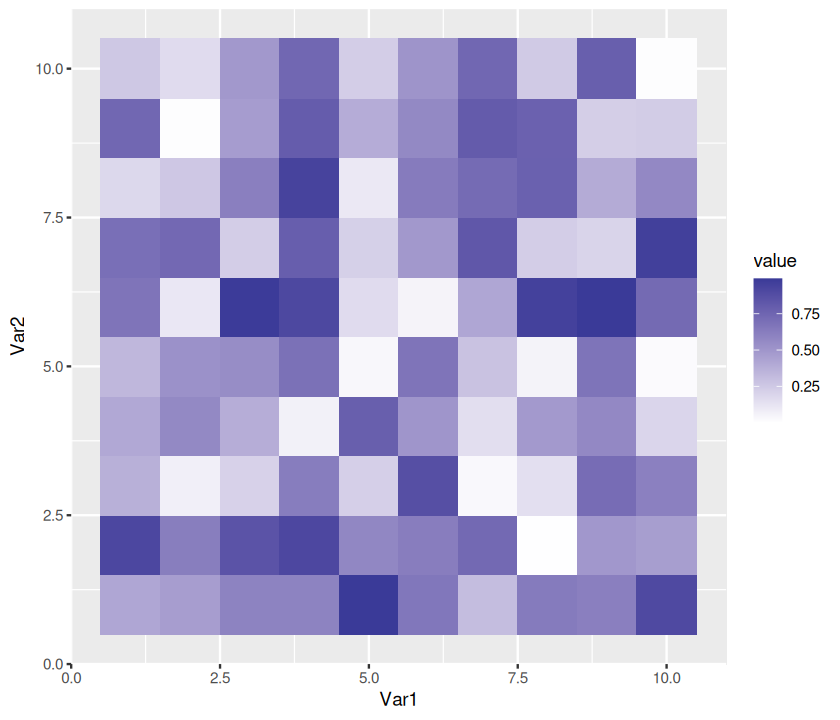

In [113]:
p + scale_fill_gradient2()

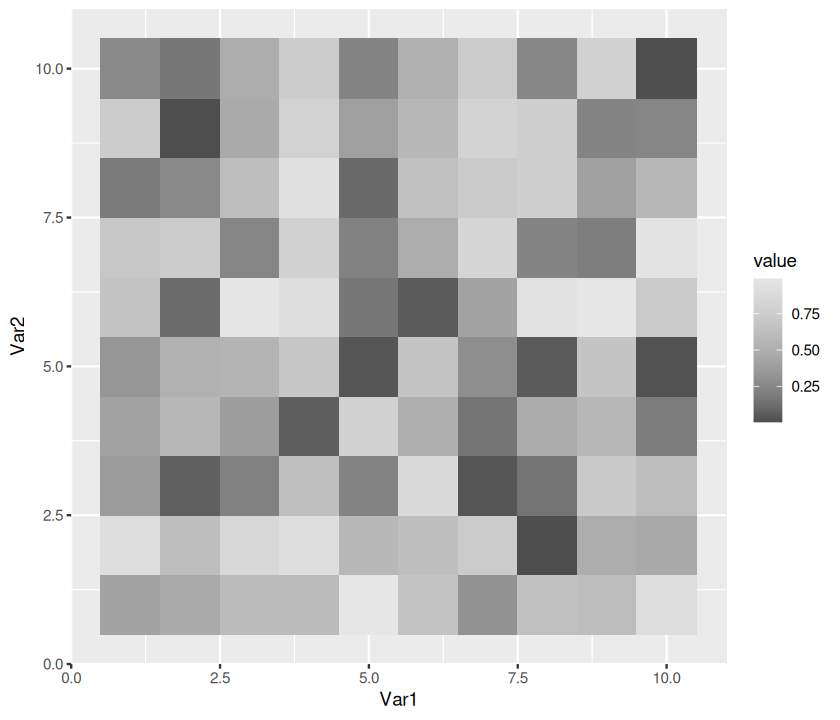

In [114]:
p + scale_fill_gradientn(colours = grey.colors(10))

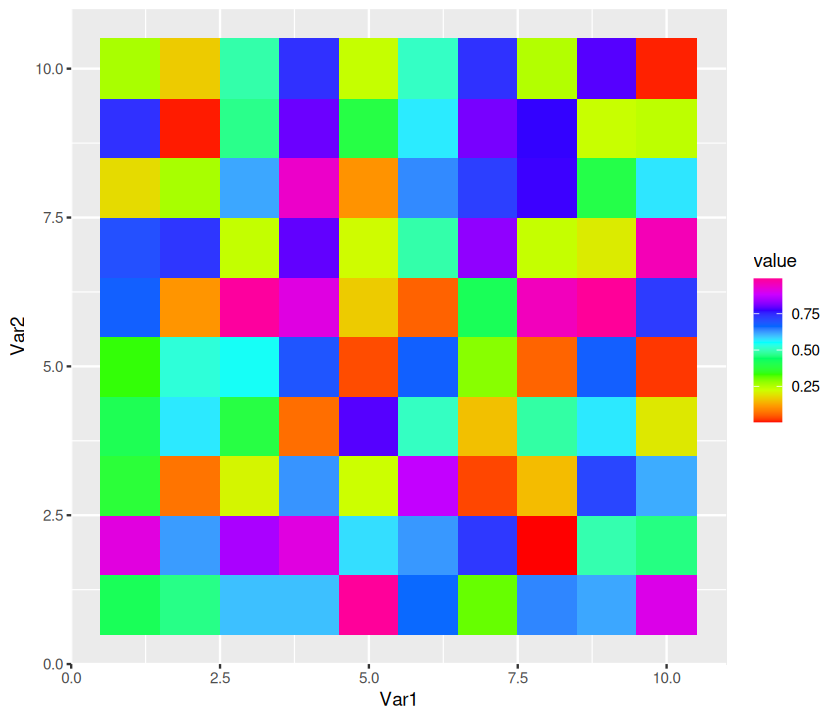

In [115]:
p + scale_fill_gradientn(colours = rainbow(10))

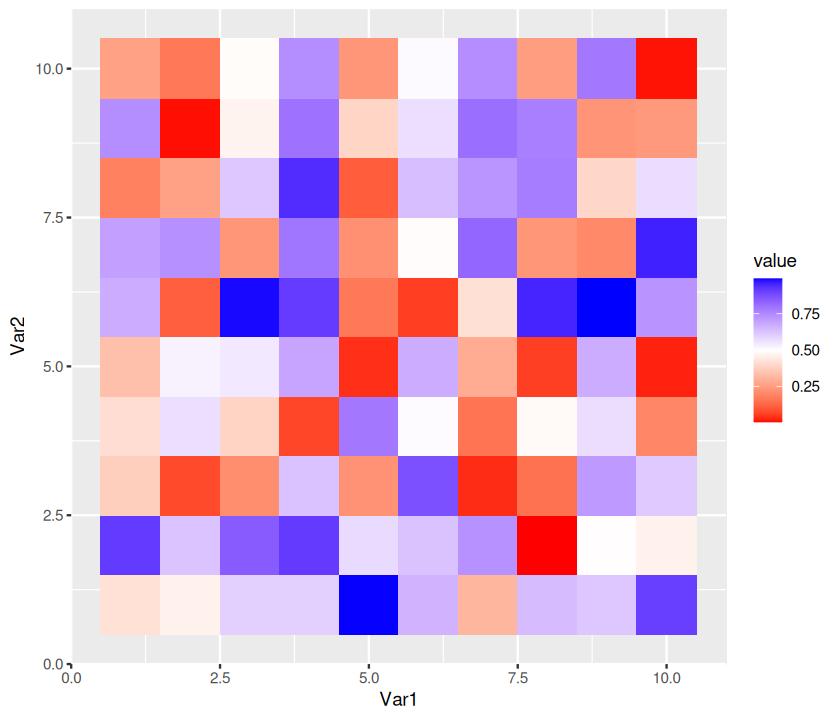

In [116]:
p + scale_fill_gradientn(colours = c("red", "white", "blue"))

```{tip}
Look up the `plotly` package, which allows you to create interactive graphs from ggplot2 plots
``` 

### Plotting two dataframes together

According to Girko's circular law, the eigenvalues of a matrix $M$ of size $N \times N$ are approximately contained in a circle in the complex plane with radius $\sqrt{N}$. Let's draw the results of a simulation displaying this result.

First, we need to build a function object that will calculate the ellipse (the perdicted bounds of the eigenvalues): 

In [117]:
build_ellipse <- function(hradius, vradius){ # function that returns an ellipse
  npoints = 250
  a <- seq(0, 2 * pi, length = npoints + 1)
  x <- hradius * cos(a)
  y <- vradius * sin(a)  
  return(data.frame(x = x, y = y))
}

In [118]:
N <- 250 # Assign size of the matrix

M <- matrix(rnorm(N * N), N, N) # Build the matrix

eigvals <- eigen(M)$values # Find the eigenvalues

eigDF <- data.frame("Real" = Re(eigvals), "Imaginary" = Im(eigvals)) # Build a dataframe

my_radius <- sqrt(N) # The radius of the circle is sqrt(N)

ellDF <- build_ellipse(my_radius, my_radius) # Dataframe to plot the ellipse

names(ellDF) <- c("Real", "Imaginary") # rename the columns

Now the plotting:

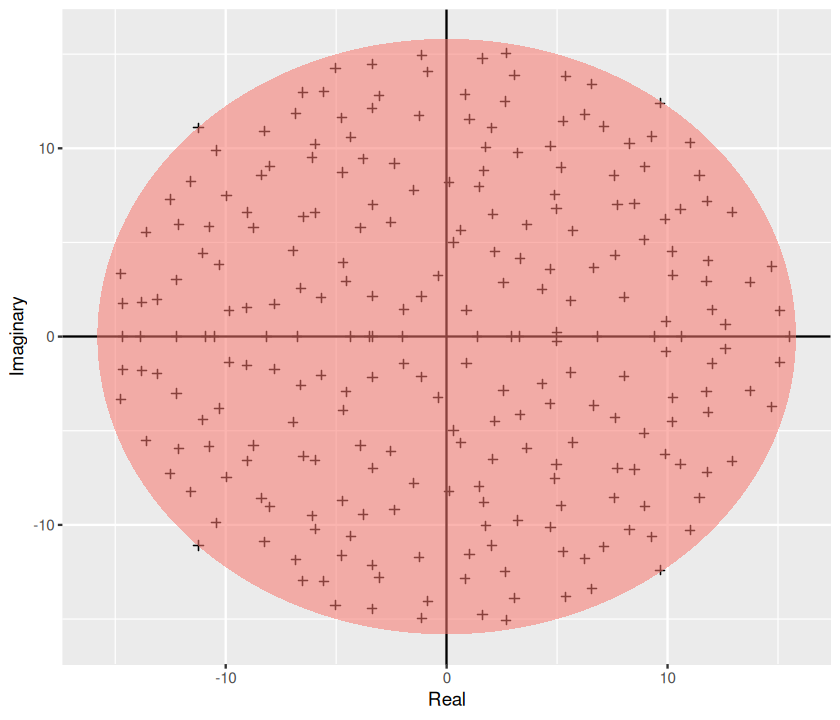

In [119]:
# plot the eigenvalues
p <- ggplot(eigDF, aes(x = Real, y = Imaginary))
p <- p +
  geom_point(shape = I(3)) +
  theme(legend.position = "none")

# now add the vertical and horizontal line
p <- p + geom_hline(aes(yintercept = 0))
p <- p + geom_vline(aes(xintercept = 0))

# finally, add the ellipse
p <- p + geom_polygon(data = ellDF, aes(x = Real, y = Imaginary, alpha = 1/20, fill = "red"))
p

$\star$ Create a self-sufficient R Script called `Girko.R` that combines all the above commands for plotting the Girko's law simulation, including saving the result figure as a file called `Girko.pdf` in the results directory.

### Annotating plots

In this example, we will use the ggplot `geom` `text` to annotate a plot.

In [120]:
a <- read.table("data/results.txt", header = TRUE)

Check what the data look like:

In [121]:
head(a)

,x,y1,y2,y3,Label
,<dbl>,<int>,<int>,<int>,<chr>
1,3.515424,4320,4320,0,NA
2,3.533984,2160,2160,0,NA
3,3.557647,4320,4320,0,NA
4,3.569953,4320,4320,0,NA
5,3.578984,8640,8640,0,NA
6,3.585665,2160,2160,0,NA


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


Warning message:
“Removed 91 rows containing missing values or values outside the scale range
(`geom_text()`).”


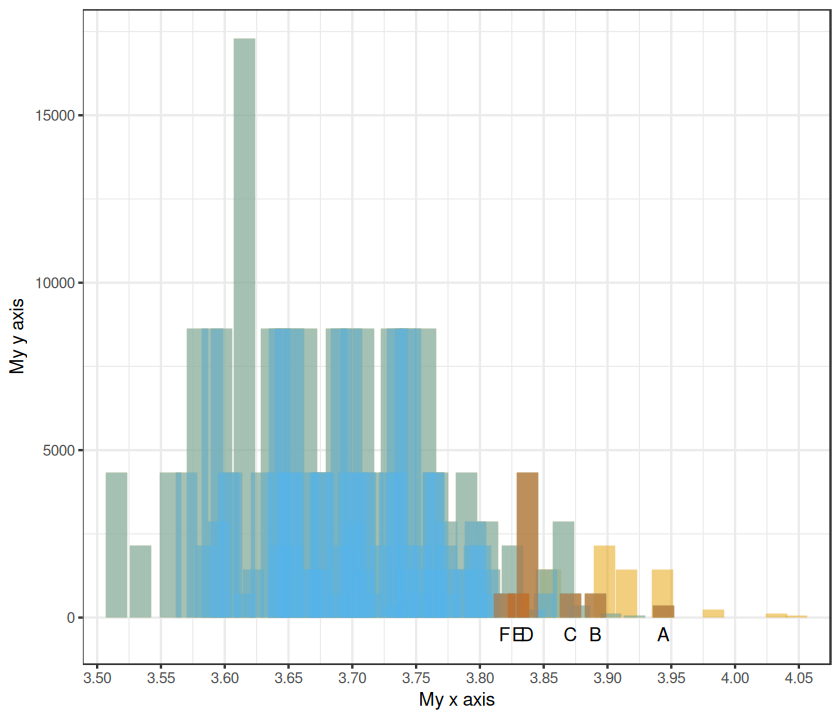

In [122]:
a$ymin <- rep(0, dim(a)[1]) # append a column of zeros

# Print the first linerange
p <- ggplot(a)
p <- p + geom_linerange(data = a, aes(
                          x = x,
                          ymin = ymin,
                          ymax = y1,
                          size = (0.5)
                          ),
                        colour = "#E69F00",
                        alpha = 1/2, show.legend = FALSE)

# Print the second linerange
p <- p + geom_linerange(data = a, aes(
                          x = x,
                          ymin = ymin,
                          ymax = y2,
                          size = (0.5)
                          ),
                        colour = "#56B4E9",
                        alpha = 1/2, show.legend = FALSE)

# Print the third linerange:
p <- p + geom_linerange(data = a, aes(
                          x = x,
                          ymin = ymin,
                          ymax = y3,
                          size = (0.5)
                          ),
                        colour = "#D55E00",
                        alpha = 1/2, show.legend = FALSE)

# Annotate the plot with labels:
p <- p + geom_text(data = a, aes(x = x, y = -500, label = Label))

# now set the axis labels, remove the legend, and prepare for bw printing
p <- p + scale_x_continuous("My x axis",
                            breaks = seq(3, 5, by = 0.05)) + 
                            scale_y_continuous("My y axis") + 
                            theme_bw() + 
                            theme(legend.position = "none") 
p

$\star$ Create a self-sufficient R Script called `MyBars.R` that combines all the above commands for annotating a plot, including saving the result figure as a file called `MyBars.pdf`.

### Mathematical display

Let's try mathematical annotation of an axis as well as within the plot area.

First create some linear regression "data":

Warning message in geom_text(aes(x = 60, y = 0, label = "sqrt(alpha) * 2* pi"), :
“All aesthetics have length 1, but the data has 1001 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


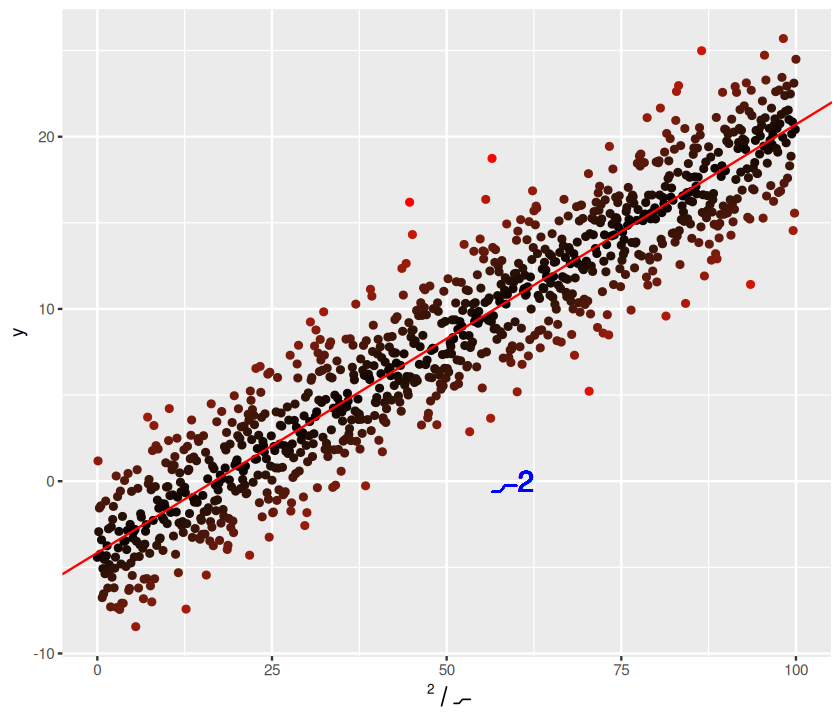

In [123]:
x <- seq(0, 100, by = 0.1)
y <- -4. + 0.25 * x +
  rnorm(length(x), mean = 0., sd = 2.5)

# and put them in a dataframe
my_data <- data.frame(x = x, y = y)

# perform a linear regression
my_lm <- summary(lm(y ~ x, data = my_data))

# plot the data
p <-  ggplot(my_data, aes(x = x, y = y,
                          colour = abs(my_lm$residual))
             ) +
  geom_point() +
  scale_colour_gradient(low = "black", high = "red") +
  theme(legend.position = "none") +
  scale_x_continuous(
    expression(alpha^2 * pi / beta * sqrt(Theta)))

# add the regression line
p <- p + geom_abline(
  intercept = my_lm$coefficients[1][1],
  slope = my_lm$coefficients[2][1],
  colour = "red")
# throw some math on the plot
p <- p + geom_text(aes(x = 60, y = 0,
                       label = "sqrt(alpha) * 2* pi"), 
                       parse = TRUE, size = 6, 
                       colour = "blue")

p

$\star$ Create a self-sufficient R Script called `plotLin.R` that combines all the above commands for annotating a linear regression plot, including saving the resulting figure as a file called `MyLinReg.pdf`.

### ggthemes

The package `ggthemes` provides you some additional `geom`s, ` scale`s, and `theme`s for `ggplot`. These include a theme based on Tufte's *The Visual Display of Quantitative Information* (see {ref}`data-r-readings`). 

Let's try this package. First install it:

```R
install.packages("ggthemes")
```

Then try:

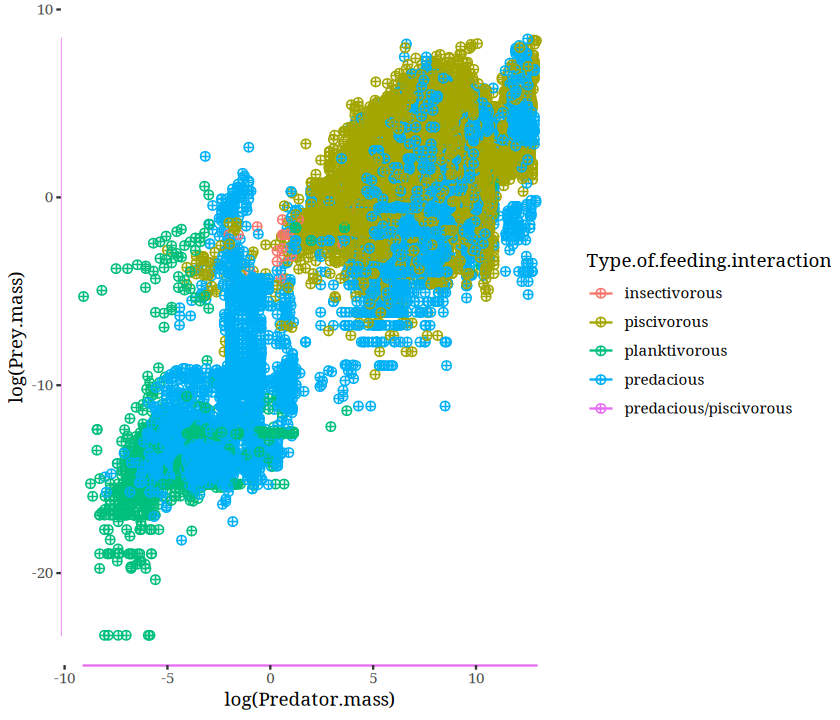

In [124]:
library(ggthemes)

p <- ggplot(MyDF, aes(x = log(Predator.mass), y = log(Prey.mass),
                colour = Type.of.feeding.interaction )) +
                geom_point(size=I(2), shape=I(10)) + theme_bw()

p + geom_rangeframe() + # now fine tune the geom to Tufte's range frame
        theme_tufte() # and theme to Tufte's minimal ink theme    

Go to https://github.com/jrnold/ggthemes for more information and a list of `geom`s, `theme`s, and `scale`s.

## Data-visualization practicals

(pound-hill-richness-practical)=
### Practical: cultivation timing and plant species richness at Pound Hill

Start from the supplied Pound Hill data and metadata; you do not need to have saved the intermediate objects from earlier chapter examples. This practical takes you from those files to a reproducible analysis and figure. The scientific question is:

> **How does mean plant species richness per quadrat vary among the March, May and October cultivation treatments?**

Species richness is the number of species observed, not the total number of individual plants. For a single quadrat, you can therefore calculate richness by counting how many species have `Count > 0`.

There is one more piece of reasoning to get right before you start. Quadrats are nested within plots, and plots are assigned to cultivation treatments. The plots, rather than all the individual quadrats, provide the treatment-level replication. The number of sampled quadrats also differs among plots. First calculate richness for each quadrat, then calculate the mean quadrat richness for each plot. Otherwise, a plot with more sampled quadrats would quietly exert more influence on your treatment comparison.

#### Start here

- {download}`Download the Pound Hill data <../data/pound_hill_data.csv>` and {download}`metadata <../data/pound_hill_meta_data.csv>` into `data/` in a project with `code/`, `data/` and `results/` directories. Keep both supplied files unchanged.
- Create one script, `code/pound_hill_analysis.R`, that reads the files from the project root and recreates both `results/pound_hill_plot_richness.csv` and `results/pound_hill_plot_richness.pdf`. The CSV has one row per plot; the figure shows those plot values by treatment.
- Finish with a short interpretation in comments in the script. Run it with `Rscript` from the project root, inspect both outputs and rerun it to check reproducibility. Keep the source script, inputs and a brief run/check note in your root README; the generated outputs can be recreated.

#### Build the analysis

Create `code/pound_hill_analysis.R`. You may begin with the working wrangling steps in {download}`data_wrang.R <../code/data_wrang.R>`, but the new script should run as a complete analysis from the project root. Use base R or `dplyr`/`ggplot2`; the important thing is that you understand and check each transformation.

1. Import the Pound Hill data and metadata. Inspect their dimensions, column types and first few rows. Keep both raw files unchanged.
2. Use the metadata to justify converting blank species counts to observed zeros, then reshape the counts to long form. Do not assume that a blank means zero in another dataset.
3. Check the result before analysing it. Confirm that counts are numeric and non-negative, and determine the number of distinct species, quadrats and plots. A quadrat is identified by its cultivation, block, plot and quadrat labels together; `Q1` alone is not a unique sampling unit.
4. Make a quadrat-level table containing `Cultivation`, `Block`, `Plot`, `Quadrat` and `Richness`. For each quadrat, `Richness` is the number of species whose count is greater than zero.
5. From that table, make a plot-level summary containing `Cultivation`, `Block`, `Plot` and `MeanRichness`. Each of the 12 plots should appear exactly once. Save it as `results/pound_hill_plot_richness.csv`.
6. Draw a figure comparing plot-level mean richness among the three cultivation treatments. Show the individual plot values rather than only a bar or treatment mean. Label the axes so that somebody can understand the response and treatment without reading your code, and save the figure as `results/pound_hill_plot_richness.pdf`.
7. At the end of the script, add two or three commented sentences interpreting the figure. Which treatment has the highest typical richness? How variable are the plots within treatments? Does the figure alone show that cultivation timing caused the differences? What else would you need to know about the design?

#### Check that it is reproducible

Close R, then run the analysis from the project root:

```bash
Rscript code/pound_hill_analysis.R
```

Inspect the saved table and figure, then run the same command again. It should replace them cleanly and produce the same results without relying on objects left in your workspace. Stop when the script, table, figure and interpretation form one rerunnable analysis.

Repeat the plot-level summary for total abundance, calculated as the sum of species counts in each quadrat. Compare its pattern with richness. Why might the two responses tell different ecological stories?

### Practical: visualize regression analyses

Download {download}`the predator-prey data <../data/ecol_archives_e_089_51_d_1.csv>` into `data/` in a project with `code/`, `data/` and `results/` directories. Write a script that reads that file, draws and saves a PDF of the following figure, and writes the accompanying regression results to a CSV table. As the plot suggests, subset the analysis by the `Predator.lifestage` field. 

---

![image](./graphics/Figure1.png)
<small><center>
               Write a script that generates this figure
    </center></small>


*Guidelines*:

* Write an R script called `PP_Regress.R` and save it in the `code` directory. Running this
script should result in one pdf file containing the following figure being saved in the `results` directory: (Hint: Use the `print()` command to write to the pdf)

* In addition, the script should calculate the regression results corresponding to the lines fitted in the figure and save it to a csv delimited table called (`PP_Regress_Results.csv`), in the `results` directory. (Hint: you will have to initialize a new dataframe in the script to first store the calculations and then `write.csv()` or `write.table()` it.)

* All that you are being asked for here is results of an analysis of Linear regression on subsets of the data corresponding to available Feeding Type $\times$ Predator life Stage combination — not a multivariate linear model with these two as separate covariates!

* The regression results should include the following with appropriate headers (e.g., slope, intercept, etc, in each Feeding type $\times$ life stage category): regression slope, regression intercept, R$^2$, F-statistic value, and p-value of the overall regression (hint: review the [Linear models chapter](./regress.ipynb)).

* The script should read `data/ecol_archives_e_089_51_d_1.csv` itself and write the PDF and CSV under `results/`, creating that directory if needed. Run it from the project root with `Rscript code/PP_Regress.R`; rerun it to confirm that it replaces the generated results.

* You can also use the `dplyr` function instead of looping (see R Chapter, and the `ggplot` command instead of `qplot`.


### Practical: map population data

You can do mapping in R using the `maps` package. In this practical, you will map the Global Population Dynamics Database (GPDD). This is a freely available database that was developed at Silwood. The [Living Planet Index](http://livingplanetindex.org/home/index) is based upon these data.
 *  Download {download}`gpdd_filtered.RData <../data/gpdd_filtered.RData>` into `data/` in a project with `code/`, `data/` and `results/` directories. Use `load("data/gpdd_filtered.RData")` from the project root and inspect the data contents. 
 *  What you need is latitude and longitude information for a bunch of species for which population time series are available in the GPDD.
 *  Now use `install.packages()` to install the package `maps`, as you did with `ggplot2`
 *  Now create `code/GPDD_Data.R` and run it from the project root with `Rscript code/GPDD_Data.R`. Save the map as `results/GPDD_map.pdf`, creating `results/` if needed. The script should:
    * Loads the maps package
    * Loads the GPDD data
    * Creates a world map (use the map function, read its help, also google examples using `maps`
    * Superimposes on the map all the locations from which we have data in the GPDD dataframe
 * Looking at the map, what biases might you expect in any analysis based on the data represented? *include your answer as a comment at the end of your R script*.


### Group practical: regression analysis by location

Download {download}`the predator-prey data <../data/ecol_archives_e_089_51_d_1.csv>` into `data/` and use the project layout described above. Repeat the regression analysis, this time separating results by the dataset's `Location` field. Write `code/PP_Regress_loc.R`, run it from the project root and save its results as `results/PP_Regress_loc_Results.csv`. No plot is needed, as a combination of `Type.of.feeding.interaction`, `Predator.lifestage`, and ` Location` will be far too busy (faceting by three variables is too much to be meaningful)!

(data-r-readings)=

## Readings & Resources



Check out *DataDataData!*, *Visualization* and *R*, under [*readings* on the MQB repository](https://github.com/MulQuaBio/MQB/tree/main/content/readings).

### Data management, reformatting and cleaning



* Brian McGill's [Ten commandments for data management](https://dynamicecology.wordpress.com/2016/08/22/ten-commandments-for-good-data-management)

* This paper covers similar ground (available in the readings directory): {cite}`Borer2009`.

* [Dasu, T. & Johnson, T. Exploratory Data Mining and Data Cleaning. (John Wiley & Sons, Inc., 2003). doi:10.1002/0471448354](https://onlinelibrary.wiley.com/doi/book/10.1002/0471448354)

* [Wide vs. long data](http://www.theanalysisfactor.com/wide-and-long-data/)

* [Hadley Wickham's excellent article about "tidy" data](http://vita.had.co.nz/papers/tidy-data.pdf).

* [Wrangler](http://vis.stanford.edu/papers/wrangler)



* [An interactive framework for data cleaning](https://www2.eecs.berkeley.edu/Pubs/TechRpts/2000/CSD-00-1110.pdf)

### Data analysis



* [R for Data Science](https://r4ds.had.co.nz/index.html)



### Data visualization



* [Ten Simple Rules for Better Figures](https://journals.plos.org/ploscompbiol/article?id=10.1371/journal.pcbi.1003833)

* https://clauswilke.com/dataviz/



* [Rolandi et al. "A Brief Guide to Designing Effective Figures for the Scientific Paper", doi:10.1002/adma.201102518](https://onlinelibrary.wiley.com/doi/pdf/10.1002/adma.201102518?casa_token=48b0PGtaUiYAAAAA:DQ9bHugikOkHDkf4uLTYIq74negyWefZjAbexYcgYObHn0sks2Q8ulvHcTUWxteqwTb5qAa0IV71Mg)

* The classic [Tufte](https://www.edwardtufte.com/tufte/books_vdqi); Available in the Imperial College Central Library. I have also added extracts and a related book in pdf on the git repository. BTW, check out what Tufte thinks of [PowerPoint](https://www.edwardtufte.com/tufte/powerpoint).

* [Tufte in R](http://motioninsocial.com/tufte)

## Where next?

You can now take a dataset from raw files to a checked table and an informative figure. The Pound Hill analysis also leaves us with a harder question: what can we infer from the pattern? Answering that depends on how the observations were sampled, which units received the treatment, and whether the comparison is replicated and independent. We take up those questions in [Experimental design and data exploration](exp-design.ipynb).